# Spotify Genre Classification

### About the dataset

This dataset is from Kaggle and contains Spotify tracks from a lot of different genres. The Kaggle page says 125 genres, but the file itself contains 114 genres with 1,000 tracks each, which gives 114,000 tracks in total. Each track has a set of audio features that describe how the song sounds, like how danceable, energetic or loud it is.

The data is in CSV format, which is tabular and quick to load with pandas.

Link: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

Credit goes to Maharshi Pandya.

### Goal

The goal is to predict the genre of a song based on its audio features. This is a multiclass classification problem, since there are more than two possible genres.

I compare two baseline models, five ensemble models (including XGBoost and LightGBM) and two neural networks. As an extra, I also combine the best models in a stacking ensemble. Besides the scores, I want to understand which features separate the genres from each other, and which mistakes the models make.

### Understanding the audio features

To make it easier to understand how the models separate the genres, here is a simple explanation of what each column measures:

- popularity: a score from 0 to 100 based on how many times a song has been played recently.
- duration_ms: the length of the track in milliseconds.
- explicit: true or false, depending on whether the song has lyrics that are not suitable for children.
- danceability: how suitable a track is for dancing, based on tempo, rhythm and beat strength (from 0 to 1).
- energy: how intense and active a song feels, from 0 to 1. High energy feels fast, loud and noisy, like heavy metal.
- key: the musical key of the track (C, C#, D and so on), stored as a number from 0 to 11.
- loudness: the overall loudness in decibels, usually between -60 and 0 dB.
- mode: major (1) or minor (0), which often decides if a song sounds "happy" or "sad".
- speechiness: how much spoken word there is. Close to 1 means it is mostly talking, like a podcast or rap, and lower values mean music.
- acousticness: a score from 0 to 1 for how likely it is that the song is played on acoustic instruments, like an acoustic guitar or a piano, instead of electronic ones.
- instrumentalness: how likely it is that the track has no vocals. The closer to 1, the more likely there is no singing at all.
- liveness: how likely it is that there was an audience in the recording. High values mean the song was probably recorded live.
- valence: how positive the music sounds, from 0 to 1. High valence sounds happy, low valence sounds sad or angry.
- tempo: the speed of the track in beats per minute (BPM).
- time_signature: the number of beats in each bar, for example 3 for 3/4 and 4 for 4/4.

The other columns are not audio features. Unnamed: 0 is a leftover row number from when the file was saved, and track_id is Spotify's unique ID for each track. Artists, album_name and track_name tell who made the song, which album it is from, and what it is called. Finally, track_genre is the genre of the track, and this is the label I want to predict.

Sources:

- https://developer.spotify.com/documentation/web-api/reference/get-audio-features

## Contents

1. Exploratory data analysis: the full dataset, choosing six genres, data quality, distributions, outliers, correlation, and how the features differ between the genres.
2. Preprocessing: cleaning (including copies of the same song on different albums), encoding, the train/test split, and a pipeline with different processing options.
3. Models: random guessing as a reference, two baselines (Decision Tree and KNN), five ensembles (Random Forest, Gradient Boosting, Extra Trees, XGBoost and LightGBM) and two neural networks (MLP and Keras). All of them are tuned automatically with cross-validation. As an extra, a stacking ensemble that combines some of the best models.
4. Evaluation: cross-validation comparison, test results, confusion matrices, and ROC and precision-recall curves.
5. Further analysis: how much popularity adds, which features matter most, which songs the final model gets wrong, and whether more data would help.
6. Conclusion.

# EXPLORATORY DATA ANALYSIS

In [54]:
# The Keras backend has to be chosen BEFORE keras is imported for the first time.
# I use PyTorch as the backend, since TensorFlow does not support my Python version (3.14) yet.
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# Preprocessing
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (LabelEncoder, MinMaxScaler, OneHotEncoder,
                                   PowerTransformer, StandardScaler, label_binarize)

# Tuning and validation
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, learning_curve)

# Models
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluation
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.inspection import permutation_importance

# Neural network with Keras
import keras
import scikeras
from scikeras.wrappers import KerasClassifier

# One random_state for the whole notebook, so every run gives the same split and results
random_state = 42
keras.utils.set_random_seed(random_state)

In [55]:
df = pd.read_csv("../dataset/spotify.csv")

In [56]:
df.head(10) # checking the data and their rows

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
8,8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,...,-8.700,1,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic
9,9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,205594,False,0.442,0.6320,...,-6.770,1,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic


In [57]:
df.shape # Tells us the amount of instances and features in the dataset 

(114000, 21)

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

### Interpretation

The dataset contains 114,000 rows and 21 columns. Most columns have complete data, but artists, album_name and track_name each have one missing value.

There are 1 bool, 9 float, 6 integer and 5 text columns. Some integer columns are really categories: key, mode and time_signature. A higher number there does not mean "more", so they need to be handled as categories later.

#### Dropping the row number

The first column, Unnamed: 0, looks like the row number from when the file was saved. Here I check that it is exactly the same as the row index pandas already gives every row. If it is, the column says nothing about the songs, and I can drop it right away.

There is also a second reason to drop it early. Since it gives every row its own number, no two rows would ever be exactly the same, so a duplicate check would miss real duplicates.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html

In [59]:
# Unnamed: 0 should be the same as the row index. If that is true for every row, the column has no information.
print(f"Unnamed: 0 is the same as the row index: {(df['Unnamed: 0'] == df.index).all()}")

# Drop it, so it can't hide duplicates later
df = df.drop(columns='Unnamed: 0')
print(f"Columns left: {df.shape[1]}")

Unnamed: 0 is the same as the row index: True
Columns left: 20


#### Missing values

info() showed that artists, album_name and track_name each have one missing value. Here I check exactly where they are, and whether it is the same row.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html
- https://www.geeksforgeeks.org/data-analysis/working-with-missing-data-in-pandas/

In [60]:
df.isnull().sum() # checking for null values in the dataset

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [61]:
df[df['artists'].isnull()]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


#### Interpretation

The three columns artists, album_name and track_name are all missing in the same row. This row also has a duration of 0 ms, which is not possible for a real song, so it looks like a broken entry.

Since it is only 1 row out of 114,000, removing it will not affect the analysis. I will drop it in preprocessing.

#### Duplicates

Here I check if the dataset counts some songs more than once. Copies can make the model see the same song in both training and test data, which gives results that look better than they really are.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html
- https://www.geeksforgeeks.org/python/pandas-dataframe-duplicated/
- https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
- https://www.geeksforgeeks.org/pandas/pandas-groupby/

In [62]:
# Check for exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 450


In [63]:
# Comparing the number of rows with the number of unique songs.
# The same track_id means the same song.
print(f"Total rows: {len(df)}")
print(f"Unique songs: {df['track_id'].nunique()}")
print(f"Repeated songs: {df['track_id'].duplicated().sum()}")

Total rows: 114000
Unique songs: 89741
Repeated songs: 24259


Unique songs (89,741) means every different song counted once, and repeated songs (24,259) means every extra time a song shows up after the first time.

Unique songs = 89741 
Repeated songs = 24259 

total songs = Unique songs + Repeated songs => 89741 + 24259 = 114000


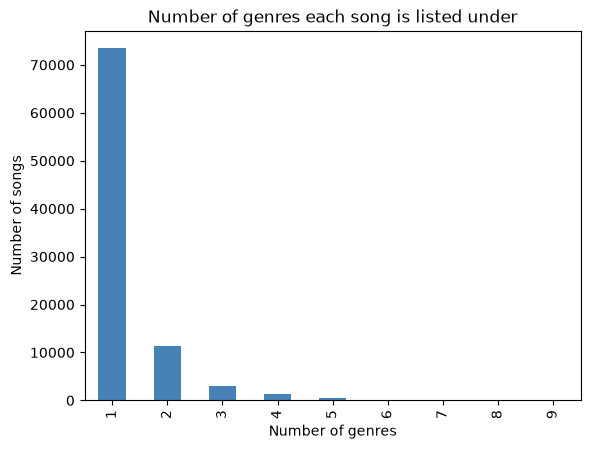

In [64]:
# How many different genres is each song listed under?
genres_per_song = df.groupby('track_id')['track_genre'].nunique()

genres_per_song.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Number of genres each song is listed under')
plt.xlabel('Number of genres')
plt.ylabel('Number of songs')
plt.show()

In [65]:
print(genres_per_song.value_counts().sort_index())

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


In [66]:
# Check if repeated songs have the same audio values
audio = ['danceability', 'energy', 'tempo', 'loudness', 'valence']
print(f"Repeats with the same audio values: {df.duplicated(subset=['track_id'] + audio).sum()}")

Repeats with the same audio values: 24259


#### Interpretation

There are 450 rows that are exact copies of another row. This is also why I dropped Unnamed: 0 first: with the row number still there, every row would be unique, and the check would have found 0 duplicates.

There are also fewer unique songs than rows, so many songs appear more than once. The plot shows that most songs belong to one genre, but a lot of songs are listed under two or more. When a song appears again, its audio values are exactly the same. Only the genre is different.

This is a problem for two reasons. The model sees the same song with different answers, so it can't learn what separates those genres. And copies of the same song could end up in both the training and test data, which would make the results look better than they really are.

I will handle this in preprocessing.

### Summary statistics

Here I look at the basic numbers for each numeric column: the average, the smallest and largest value, and how spread out the values are. The goal is to spot values that look wrong or unrealistic.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html
- https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-describe-method/
- https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/

In [67]:
# Summary statistics for all numeric columns.
# .T flips the table so each column becomes a row, which is easier to read.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000


A short note on what the columns in the table mean: count is how many values there are, mean is the average, std shows how spread out the values are, and min and max are the smallest and the largest value. The 25%, 50% and 75% columns mean that a quarter of the songs are below the 25% value, half of the songs are below the 50% value (the median), and so on.

In [68]:
# Count values that are not possible, or unusual, for a real song
print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")
print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")
print(f"Songs with duration 0: {(df['duration_ms'] == 0).sum()}")
print(f"Songs louder than 0 dB: {(df['loudness'] > 0).sum()}")

Songs with tempo 0: 157
Songs with time_signature 0: 163
Songs with duration 0: 1
Songs louder than 0 dB: 90


### Interpretation

Most values look realistic, but some are not possible for a real song. 157 songs have a tempo of 0 and 163 songs have a time signature of 0. A song without a beat can't be measured, so these zeros most likely mean "missing" and not a real value. 1 song has a duration of 0, which is the broken row from the missing values step.

Some values are unusual, but possible. The longest song in the full dataset is about 87 minutes, which could be a long classical or ambient track. 90 songs are louder than 0 dB, which is above the normal range. This can happen when a track is mastered very loud.

For instrumentalness and speechiness, the mean is much higher than the median. This means that most songs are close to 0, while a small group has very high values.

Key and mode are categories, so their mean doesn't really mean anything.

In [69]:
df[df['tempo'] == 0]['track_genre'].value_counts()

track_genre
sleep          138
guitar           4
iranian          4
ambient          3
world-music      3
opera            2
jazz             1
romance          1
show-tunes       1
Name: count, dtype: int64

### Interpretation

Most of the songs with tempo 0 are from the sleep genre. These are often rain sounds or white noise without a beat, so Spotify can't measure a tempo. The few songs from other genres, like guitar and jazz, are probably tracks with a very free rhythm where the measurement failed.

In both cases, a tempo of 0 means the value is missing, not that the song is extremely slow. I will remove these songs in preprocessing.

#### The target: track_genre

Here I look at the label I want to predict: how many genres there are, and how the songs are spread across them.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
- https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html

In [70]:
# How many genres are there, and how many songs does each have?
print(f"Number of genres: {df['track_genre'].nunique()}")
print(df['track_genre'].value_counts())

Number of genres: 114
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64


In [71]:
# Check that every genre has the same number of songs
print(f"Different song counts per genre: {df['track_genre'].value_counts().unique()}")

Different song counts per genre: [1000]


### Interpretation

There are 114 genres, and every genre has exactly 1,000 songs, so the classes are perfectly balanced. No genre is easier to guess just because it has more songs.

With 114 genres, a model that guesses at random would only be right about 0.9% of the time. This makes it a very hard problem, especially since many songs are listed under more than one genre.

In [72]:
# Counting how many songs two genres have in common
def shared_songs(genre1, genre2):
    songs1 = set(df[df['track_genre'] == genre1]['track_id'])
    songs2 = set(df[df['track_genre'] == genre2]['track_id'])
    return len(songs1 & songs2)

In [73]:
# Genre pairs with similar names, plus one very different pair for comparison
pairs = [
    ('singer-songwriter', 'songwriter'),
    ('punk', 'punk-rock'),
    ('alt-rock', 'alternative'),
    ('latin', 'latino'),
    ('indie', 'indie-pop'),
    ('classical', 'heavy-metal'),   # very different, for comparison
]

for genre1, genre2 in pairs:
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

singer-songwriter / songwriter: 1000 shared songs


punk / punk-rock: 628 shared songs
alt-rock / alternative: 592 shared songs
latin / latino: 588 shared songs
indie / indie-pop: 579 shared songs
classical / heavy-metal: 0 shared songs


### Interpretation

From the results, I can see that some genres share many of the same songs. For example, singer-songwriter and songwriter share all 1,000 songs, while punk and punk-rock share 628 songs.

This can be a problem when training a classification model because the same song may appear with identical audio features but different genre labels. Since the model is trying to predict one genre for each song, this makes it harder to learn clear differences between genres.

Because of this, I want to reduce the number of genres and focus on genres with less overlap. The goal is to give the model clearer patterns to learn from and reduce conflicting labels.

### Choosing which genres to keep

When choosing the genres, I focus on three things. First, I want genres that share as few songs as possible, so the model doesn't get conflicting labels. Second, I want genres that sound different, because then features like energy, tempo, danceability and loudness can help the model tell them apart. Third, I need enough data. Every genre has 1,000 rows, so six genres give me 6,000 rows, which is more than the assignment requires.

I decided to start with classical, country, heavy-metal, hip-hop, jazz and techno, because they are very different types of music. Classical is mostly orchestral and instrumental music. Country often uses acoustic instruments and is inspired by folk music. Heavy-metal usually has loud guitars, drums and a lot of energy. Hip-hop is focused on rap, rhythm and beats. Jazz often uses improvisation and acoustic instruments. And techno is mostly electronic music with repetitive beats.

My thinking is that these differences might help the model recognise each genre with features like energy, tempo, danceability, loudness and instrumentalness.

However, just because the genres sound different doesn't mean they share no songs. I still need to check the overlap with my shared_songs() function before I decide to keep them.

Sources:

- https://docs.python.org/3/tutorial/datastructures.html
- https://docs.python.org/3/library/itertools.html
- https://seaborn.pydata.org/generated/seaborn.scatterplot.html
- https://seaborn.pydata.org/generated/seaborn.relplot.html

In [74]:
# The genres I want to keep
genres = ['classical', 'country', 'heavy-metal', 'hip-hop', 'jazz', 'techno']

# Check how many songs each pair of chosen genres shares
for genre1, genre2 in combinations(genres,2):
    print(f"{genre1} / {genre2}: {shared_songs(genre1, genre2)} shared songs")

classical / country: 0 shared songs
classical / heavy-metal: 0 shared songs
classical / hip-hop: 0 shared songs
classical / jazz: 10 shared songs
classical / techno: 0 shared songs
country / heavy-metal: 0 shared songs
country / hip-hop: 0 shared songs
country / jazz: 0 shared songs
country / techno: 0 shared songs
heavy-metal / hip-hop: 0 shared songs
heavy-metal / jazz: 0 shared songs
heavy-metal / techno: 0 shared songs
hip-hop / jazz: 0 shared songs
hip-hop / techno: 0 shared songs
jazz / techno: 1 shared songs


### Interpretation

From the results, I can see that the six genres I selected share very few songs. Out of the 15 comparisons, 13 pairs have no songs in common. Only classical and jazz share 10 songs, and jazz and techno share 1 song.

This is a good result, because I wanted genres with as little overlap as possible. It means there are fewer cases where the model sees the same song with different genre labels. Based on this, I decided to keep these six genres and continue the analysis with them.

However, even though they share very few songs, this does not guarantee that the model will classify them correctly. I still need to train and evaluate the models to see how well the audio features separate the genres.

It is also important to see the difference between overlap and similar features. Overlap means the exact same song is listed in two genres. When classical and jazz share 10 songs, it is the same recording with the same track_id, so of course it has exactly the same features. Similar features means different songs that sound alike. One punk song and one punk-rock song can both be loud, fast and energetic, but they are still different songs with similar, not identical, values.

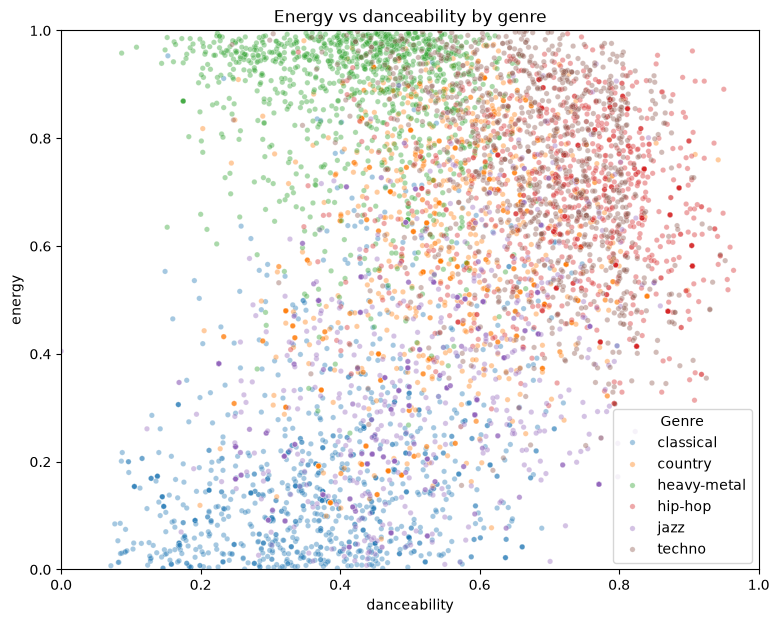

In [75]:
# Energy vs danceability for the six genres, one colour per genre
plot_df = df[df['track_genre'].isin(genres)]

plt.figure(figsize=(9, 7))
sns.scatterplot(data=plot_df, x='danceability', y='energy', hue='track_genre', alpha=0.4, s=15)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.title('Energy vs danceability by genre')
plt.legend(title='Genre')
plt.show()

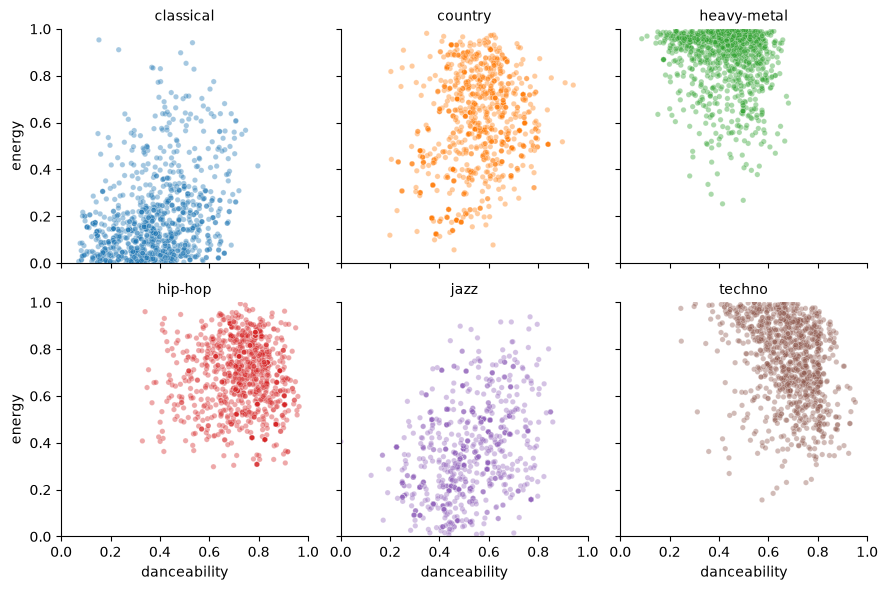

In [76]:
# The same plot with one small plot per genre, so the genres don't hide each other
grid = sns.relplot(data=plot_df, x='danceability', y='energy', col='track_genre', col_wrap=3,
                   hue='track_genre', alpha=0.4, s=15, height=3, legend=False)
grid.set(xlim=(0, 1), ylim=(0, 1))
grid.set_titles('{col_name}')
plt.show()

### Interpretation (Energy vs. Danceability)

From the scatter plots, I can see that the genres have different patterns when comparing energy and danceability.

Heavy-metal is at the top of the plot. Almost all heavy-metal songs have an energy close to 1, while the danceability varies a lot, from about 0.2 to 0.6.

Classical is at the bottom left. Most classical songs have a low energy (below 0.3) and a lower danceability than the other genres.

Hip-hop and techno are both in the upper right corner, so they are both energetic and danceable. Techno has a bit higher energy and hip-hop has the highest danceability, but the two groups overlap a lot.

Jazz and country are in the middle. Jazz is spread out with low to medium energy, and overlaps with classical at the bottom. Country is spread from about 0.3 to 1.0 in energy, and overlaps with almost every other genre.

The small plots, one per genre, make this easier to see, since the genres don't cover each other.

What I find interesting is that some genres are easy to separate with only these two features, like classical and heavy-metal, while others overlap a lot: hip-hop and techno, jazz and classical, and country with almost everything. So these two features are not enough on their own, and the models will need to combine more features.

## Keeping only the six chosen genres

From here on, the analysis only uses the six genres I chose.

In [77]:
# Keep only the six chosen genres
df = df[df['track_genre'].isin(genres)]

print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 6000
track_genre
classical      1000
country        1000
heavy-metal    1000
hip-hop        1000
jazz           1000
techno         1000
Name: count, dtype: int64


### Interpretation

From the results, I can see that my dataset has been reduced from 114,000 to 6,000 rows.

Each of the six genres still contains exactly 1,000 rows, which means the dataset is still balanced between the different classes.

This is important because no genre has more rows than the others, so the model will not be biased toward a genre simply because it appears more often in the training data.

Now I have a smaller dataset with six different genres, and I can continue with the preprocessing before training my models.

However, I still need to remember that some songs appear in more than one genre, so 6,000 rows does not necessarily mean 6,000 unique songs.

In [78]:
# Re-check the problems found earlier, now only for the six genres
# We found missing values, duplicates and zero tempos earlier.
# Now I want to check if these problems still exist after keeping only six genres.
print(f"Missing values: {df.isnull().sum().sum()}")

print(f"Exact duplicate rows: {df.duplicated().sum()}")

print(f"Unique songs: {df['track_id'].nunique()} out of {len(df)} rows")

print(f"Songs with tempo 0: {(df['tempo'] == 0).sum()}")

print(f"Songs with time_signature 0: {(df['time_signature'] == 0).sum()}")

Missing values: 0
Exact duplicate rows: 79
Unique songs: 5910 out of 6000 rows
Songs with tempo 0: 1
Songs with time_signature 0: 1


### Interpretation

Most of the problems from earlier are gone. There are no missing values anymore, since the broken row belonged to a genre I removed.

Some problems are still there, but they are small. There are 79 exact duplicate rows, and 11 songs are listed under two of the six genres. This matches what I found earlier when comparing the genres, where classical and jazz shared 10 songs, while jazz and techno shared 1 song. I also found one song with a tempo of 0 and one with a time signature of 0. These might be the same song, and it could mean that Spotify was unable to detect a clear beat or time signature.

I will handle these problems during preprocessing. The main reason is that duplicates could end up in both the training and test data, or in different folds during cross-validation. Then the model would be tested on a song it has already seen during training, and metrics such as accuracy, precision, recall and F1-score would look better than they really are.

However, these checks only find copies with the same track_id. Next I check whether the same recording can also hide under a different track_id.

#### Re-released recordings

The same recording is often released more than once, for example first on an album and later on a compilation like "Mozart: A Night of Classics". Every release gets its own track_id and its own popularity, so the duplicate checks above can't find these copies. But the audio features are measured from the sound itself, so they should be exactly the same. Here I look for songs where all the audio features are identical to another song.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
- https://www.geeksforgeeks.org/python/pandas-dataframe-duplicated/

In [79]:
# The columns that describe the recording itself. popularity, explicit and the names are left out,
# because they can be different for two releases of the same recording.
audio_cols = ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
              'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

same_audio = df.duplicated(subset=audio_cols)                    # same sound as an earlier row
same_track = df.duplicated(subset=audio_cols + ['track_id'])     # ... and also the same track_id

print(f"Rows with exactly the same audio as an earlier row: {same_audio.sum()}")
print(f" of these, with a different track_id (re-releases): {(same_audio & ~same_track).sum()}")

Rows with exactly the same audio as an earlier row: 1339
 of these, with a different track_id (re-releases): 1249


In [80]:
# A few examples: the same recording on different albums, with different track_ids
releases = df.drop_duplicates(subset=audio_cols + ['track_id'])     # ignore the exact copies here
copies = releases[releases.duplicated(subset=audio_cols, keep=False)].sort_values(audio_cols)
copies[['track_id', 'track_name', 'album_name', 'track_genre', 'popularity', 'energy', 'tempo']].head(6)

,track_id,track_name,album_name,track_genre,popularity,energy,tempo
16682,0hzWbtiRS535mA1URdFBNg,"Divertimento No. 11 in D, K.251 ""Nannerl-Septe...",Mozart: A Night of Classics,classical,26,0.1730,116.714
16785,7lRUJ9zBbrOBnz91KOiw0L,"Divertimento No. 11 in D, K.251 ""Nannerl-Septe...",Mozart - All Day Classics,classical,24,0.1730,116.714
16708,5R02WO5PUrHxynXWfheAqN,"12 Variations on an Allegretto in B Flat, K.50...",Mozart: A Night of Classics,classical,24,0.0220,89.780
16814,2mo0DJxh0B6TBGDfK5ZOOa,"12 Variations on an Allegretto in B Flat, K.50...",Mozart - A Classical Dawn,classical,16,0.0220,89.780
16032,0wfvJwWZ1ju6C6ieGQI9hW,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Classical Christmas,classical,0,0.0142,95.139
16046,5vFFMf3on3rtVu46VDQJ1T,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Klassische Weihnachtsmusik,classical,0,0.0142,95.139


In [81]:
# How many re-released copies does each genre have?
re_releases = df[same_audio & ~same_track]
print(re_releases['track_genre'].value_counts().to_string())

# How many times is the most copied recording in the data?
print(f"\nMost copies of one recording: {df.groupby(audio_cols).size().max()}")

# Share of the groups of identical recordings where all copies have the same track name
groups = df[df.duplicated(subset=audio_cols, keep=False)].groupby(audio_cols)
print(f"Groups where all copies have the same name: {(groups['track_name'].nunique() == 1).mean():.1%}")

track_genre
jazz           487
country        367
hip-hop        244
classical      119
techno          25
heavy-metal      7

Most copies of one recording: 34
Groups where all copies have the same name: 98.5%


### Interpretation

This is a much bigger problem than the exact duplicates. 1,339 rows have exactly the same audio values as an earlier row, and 1,249 of them have a different track_id. These are re-releases: the same recording released on different albums. The examples show the same Mozart pieces on albums like "Mozart: A Night of Classics" and "Mozart - All Day Classics", with exactly the same energy and tempo, but a different popularity.

I am sure that these are copies of the same recording, and not just similar songs. It is very unlikely that two different songs get exactly the same value for all 13 audio features, and in 98.5% of the groups all the copies even have the same song name. One recording is in the data 34 times.

The copies are not spread evenly between the genres. Jazz has 487, country 367 and hip-hop 244, while heavy-metal only has 7. This probably comes from how the dataset was collected, since jazz and country playlists contain a lot of compilation albums.

This matters for the models. If one copy ends up in the training data and another copy in the test data, the model is tested on a song it has already seen. I will remove the copies in preprocessing, and keep one copy of each recording.

## Distributions: Histograms

Here I look at how the values of each audio feature are spread out across all songs.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html
- https://www.geeksforgeeks.org/data-visualization/plotting-histogram-in-python-using-matplotlib/
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.skew.html
- https://www.geeksforgeeks.org/data-science/skewness-measures-and-interpretation/

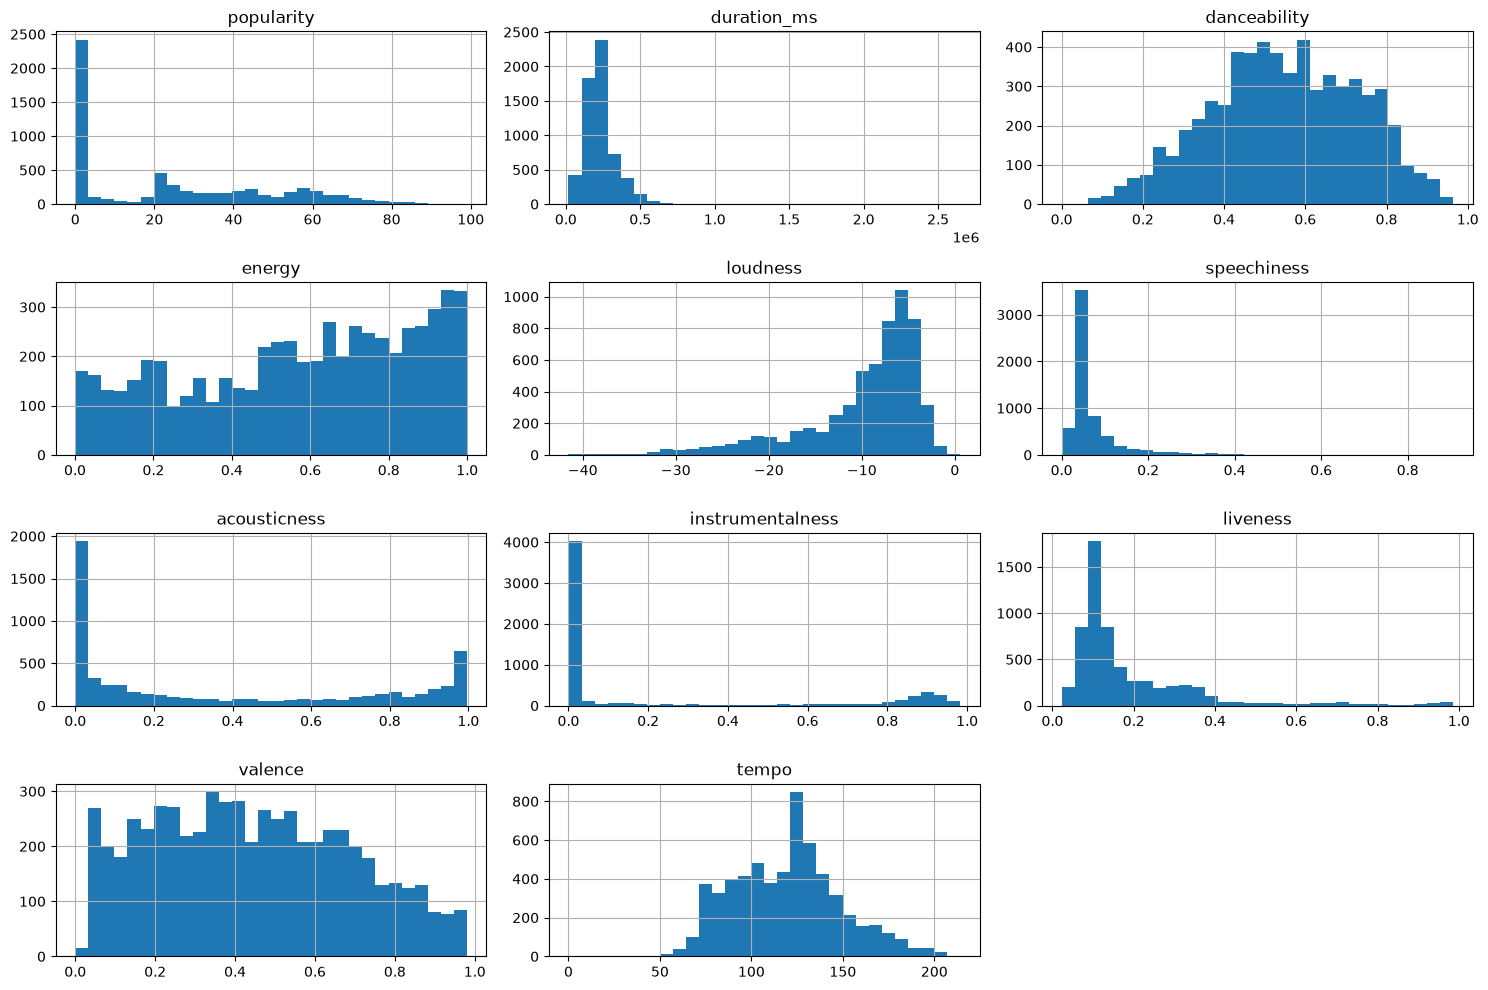

In [82]:
# Histograms of the audio features
plot_features = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df[plot_features].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

### Interpretation

From the histograms, I can see that the audio features are spread out in different ways.

Some features, like danceability, tempo and valence, look roughly bell-shaped. This means most songs are somewhere in the middle, and only a few songs have very low or very high values.

Other features are skewed. Speechiness, liveness and duration_ms are right-skewed, which means most songs have low values, while a small group of songs has much higher values. Loudness and energy are the opposite. Here most songs are loud and energetic, and only a few songs are very quiet or calm.

The most interesting ones are acousticness and instrumentalness, because they have two peaks instead of one. For acousticness, many songs are close to 0 and many are close to 1. This tells me there are two groups of songs: some are made with acoustic instruments, and some are more electronic. Instrumentalness shows something similar, where most songs have vocals, but one group has almost no vocals at all. Since my goal is to separate genres, I think these two features could be very useful, because they seem to split the songs into clear groups.

I decided not to change the skewed features right now. Tree-based models like Decision Tree and Random Forest are not affected by the shape of the data, because they only look for a value to split on. KNN and neural networks are more sensitive to the size of the values, so I will scale the features in preprocessing. I will also test a power transform on the skewed features as one of my processing alternatives, and let the tuning show if it actually helps.

I left out key, mode and time_signature because they represent categories rather than continuous measurements. For example, key represents musical notes, while mode tells us whether a song is in major or minor. A histogram of these values would show how often each category appears, rather than how a continuous feature is distributed.

I will look at the categorical features separately later, since they need to be interpreted differently.

In [83]:
# Skewness: near 0 = symmetric, positive = long tail to the right, negative = long tail to the left.
# It only describes how lopsided a distribution is, so I use it together with the histograms.
print("Skewness per feature:")
print(df[plot_features].skew().round(3).sort_values().to_string())

Skewness per feature:
loudness           -1.638
energy             -0.348
danceability       -0.134
valence             0.203
tempo               0.275
acousticness        0.486
popularity          0.568
instrumentalness    1.173
liveness            2.463
speechiness         4.300
duration_ms         5.005


### Interpretation

The skewness numbers confirm what the histograms showed. duration_ms (5.0) and speechiness (4.3) are the most right-skewed, followed by liveness (2.5) and instrumentalness (1.2): most songs have low values, and a few songs have very high values. Loudness (-1.6) is skewed to the left, since most songs are loud and only a few are very quiet. Danceability, tempo and valence are close to 0, so they are almost symmetric.

A rule of thumb is that a skewness above 1 or below -1 is strong. Five of the features pass that limit, so testing a power transform in preprocessing makes sense.

In [84]:
# How many songs have popularity 0, and which genres are they from 
print(f"Songs with popularity 0: {(df['popularity'] == 0).sum()}")
print(df[df['popularity'] == 0]['track_genre'].value_counts())

Songs with popularity 0: 2029
track_genre
jazz           681
country        587
classical      398
hip-hop        289
techno          72
heavy-metal      2
Name: count, dtype: int64


### Interpretation

2029 songs have a popularity of 0. That is about one third of all the songs in my six genres, which is a lot.

What stands out is that the zeros are not spread evenly between the genres. Jazz has 681 songs with popularity 0, which is more than two thirds of all the jazz songs. Country and classical also have many. Heavy metal, on the other hand, only has 2.

A popularity of 0 most likely means that a song has very few or no recent plays on Spotify. It says something about how many people listen to the song, not about how the song sounds.

This is a problem for my goal. If I keep popularity, the model could learn a shortcut like "if popularity is 0, the song is probably jazz or country". That might help the accuracy, but it doesn't teach the model anything about what makes a genre sound the way it does. And it would not work for a new jazz song that happens to be popular.

Because of this, I am leaning towards dropping popularity. Since the assignment asks for multiple processing alternatives, I will test both keeping and dropping it in preprocessing. At the end I also compare every model with and without it, to see how much of the score comes from this shortcut.

## Outliers

Here I look for songs with values that are far away from the rest. These could be errors in the data, or just unusual songs.

Sources:

- https://seaborn.pydata.org/generated/seaborn.boxplot.html
- https://www.geeksforgeeks.org/data-analysis/box-plot/
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html
- https://www.geeksforgeeks.org/machine-learning/interquartile-range-to-detect-outliers-in-data/

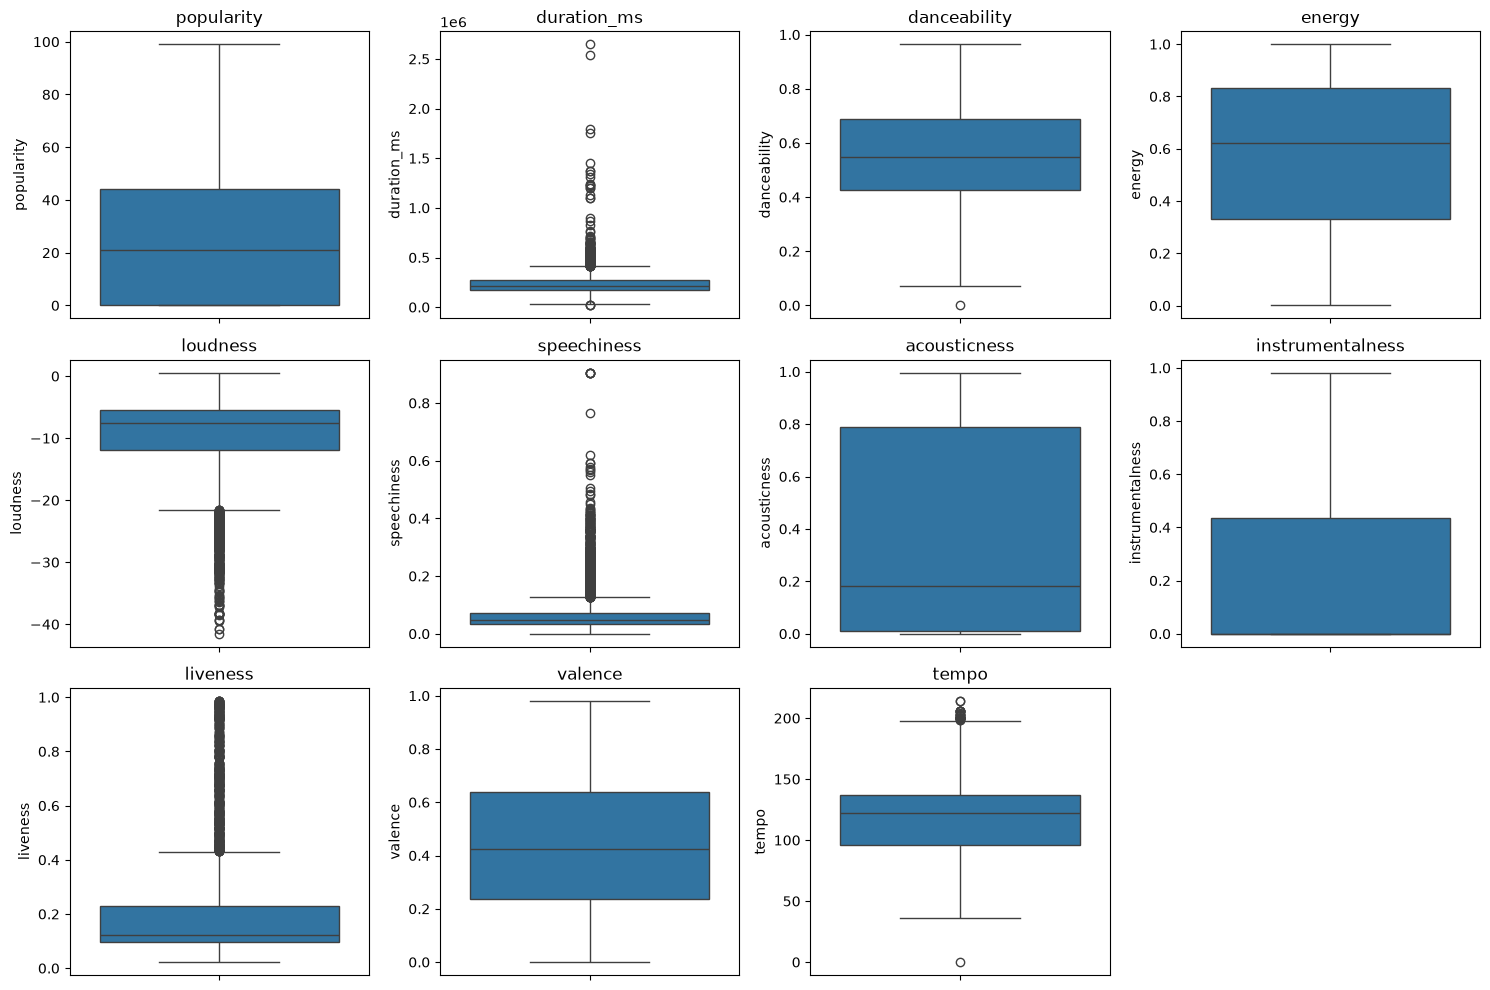

In [85]:
# Box plots of the audio features
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(plot_features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Hide the empty 12th plot, since there are only 11 features
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [86]:
# Checking exactly how many outliers there are in each column using the IQR method (Interquartile Range).
for col in plot_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} outliers")
    else:
        print(f"  {col}: no outliers")

  popularity: no outliers
  duration_ms: 382 outliers
  danceability: 1 outliers
  energy: no outliers
  loudness: 442 outliers
  speechiness: 638 outliers
  acousticness: no outliers
  instrumentalness: no outliers
  liveness: 411 outliers
  valence: no outliers
  tempo: 29 outliers


### Interpretation

The features with the most outliers are speechiness, loudness, liveness and duration_ms. These are the same features that looked skewed in the histograms, so this was expected.

I decided to keep these outliers, because they look like real songs and not errors. For example, hip-hop has a lot of rapping, so many hip-hop songs will have a high speechiness. If I removed these as outliers, I would remove part of what makes hip-hop sound different from the other genres, which is exactly what I want the model to learn. In the same way, very quiet songs are probably classical or jazz, and the longest songs, around 44 minutes, are most likely long classical pieces. Some songs also have a high liveness because they were recorded live with an audience.

The only outlier I don't trust is the song with a tempo of 0, which also shows up as an outlier in danceability. This is the song where Spotify couldn't measure a beat, which I found earlier. I will remove it in preprocessing.

## Correlation

Here I check which features are related to each other. If two features are very strongly correlated, they give the model almost the same information.

Sources:

- https://lost-stats.github.io/Presentation/Figures/heatmap_colored_correlation_matrix.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
- https://seaborn.pydata.org/generated/seaborn.heatmap.html
- https://www.geeksforgeeks.org/python/plotting-correlation-matrix-using-python/

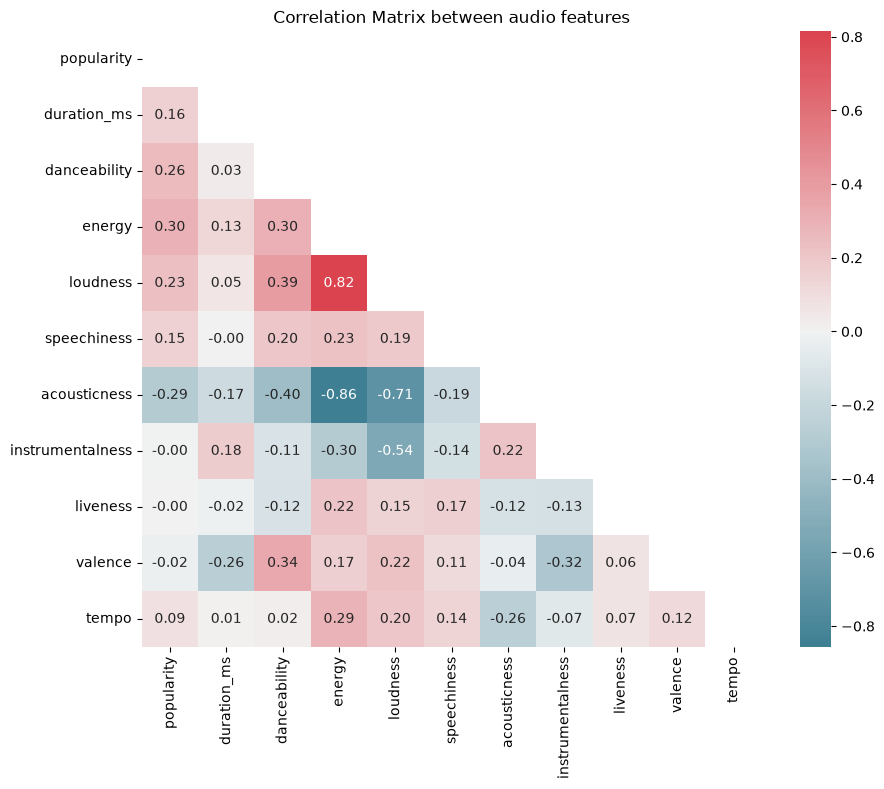

In [87]:
# Correlation between the audio features 

corr = df[plot_features].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)


plt.figure(figsize=(10,8))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',cmap=cmap,center=0)

plt.title('Correlation Matrix between audio features')

plt.show()

### Interpretation

The strongest relationships are between energy, loudness and acousticness. Acousticness and energy have a strong negative correlation (-0.86), and energy and loudness have a strong positive one (0.82). Acousticness and loudness are also strongly negative (-0.71). This makes sense to me: loud songs usually feel energetic, while acoustic songs, like classical or jazz played on real instruments, tend to be calmer and quieter. Electronic or heavy songs are the opposite, louder and more energetic.

There are also some moderate relationships. Instrumentalness is negatively related to loudness (-0.54), so songs without vocals tend to be quieter. Danceability goes together with loudness (0.39) and valence (0.34), and goes against acousticness (-0.40). So happy and loud songs tend to be more danceable, and acoustic songs less danceable.

Popularity has a weak relationship with some of the audio features, for example energy (0.30) and acousticness (-0.29). I don't think this means that energetic songs are more popular in general. It comes from the genres: jazz and classical have many songs with popularity 0, and they are also the calmest and most acoustic genres. So the genre affects both the popularity and the sound. This is one more reason why I test the models both with and without popularity.

My decision: I use a threshold of 0.8. If two features correlate more strongly than that, they give the model almost the same information, and I would consider dropping one of them. Two pairs go above the threshold: acousticness and energy (-0.86), and energy and loudness (0.82). Energy is part of both pairs, so it would be the natural one to drop.

I still decided to keep all the features. First, the correlations are strong but not perfect, so the features still carry some different information. A song can be loud without feeling energetic, for example a slow but loud orchestral piece. Second, my strongest models are tree-based. A tree just picks the most useful feature at every split, so two similar features don't confuse it, they only share the importance between them. Third, with only 15 features, removing one saves very little, but it could remove useful information.

I keep this in mind for later: when features are correlated, the feature importance can be spread out between them, so each of them can look less important than it really is.

## Features vs genre

Here I compare each audio feature across the six genres. If a feature has very different values for different genres, it should be useful for telling them apart.

Sources:

- https://seaborn.pydata.org/generated/seaborn.boxplot.html
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

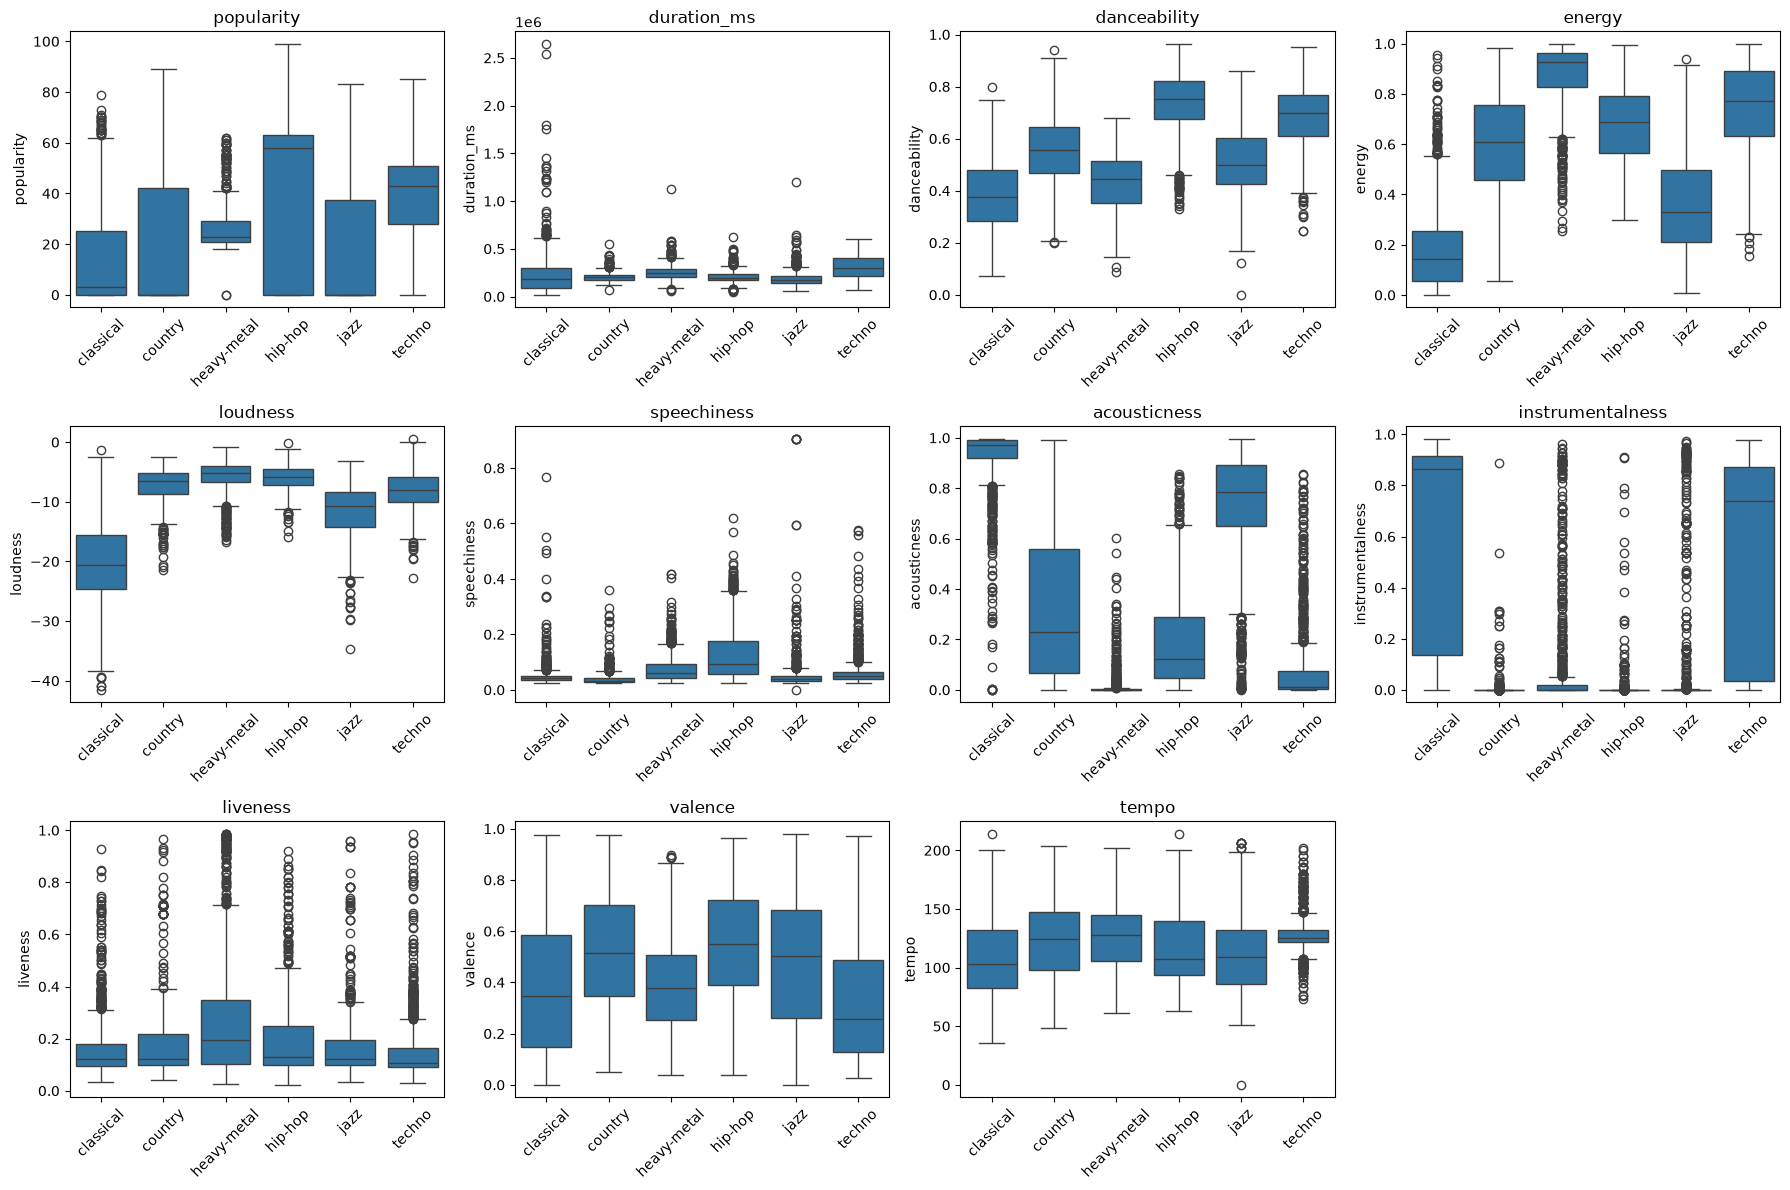

In [88]:
# Box plots of each feature, split by genre
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(plot_features):
    sns.boxplot(data=df, x='track_genre', y=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

# Hiding the empty 12th plot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Interpretation

This plot shows clear differences between the genres.

Classical is very quiet and calm, almost fully acoustic, and most songs have no vocals. Heavy-metal is the opposite: it is the most energetic and loudest genre, and not acoustic at all. Hip-hop is the most danceable genre and has the most speech, which makes sense because of the rapping. Techno is energetic and danceable, often without vocals, and almost all techno songs have a very similar tempo. Jazz is calm and acoustic like classical, while country sits somewhere in the middle on most features.

The features that separate the genres best are acousticness, energy, loudness, instrumentalness and danceability, because the boxes for the different genres are at very different heights. Speechiness mostly helps to recognise hip-hop, and tempo mostly helps to recognise techno. Liveness looks almost the same for every genre, so it probably won't help much. duration_ms also looks similar in the plot, but that is because a few very long songs squash the boxes. If I look at the medians, techno songs are actually much longer (about 4.9 minutes) than jazz (about 2.9 minutes) and classical (about 3.0 minutes), so duration can help a bit to recognise techno.

What I find most interesting is how similar genres can still be told apart. Classical and jazz are both calm and acoustic, but classical usually has no vocals while jazz does. Heavy-metal and techno are both energetic, but techno is more danceable and has fewer vocals. This tells me that no single feature can separate all the genres on its own. The models will need to combine several features to tell them apart.

## Categorical features

Explicit, mode, time_signature and key are categories, not amounts. Here I check how often each category appears in each genre, to see if they could help tell the genres apart.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html
- https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html
- https://www.geeksforgeeks.org/python/pandas-crosstab-function-in-python/
- https://seaborn.pydata.org/generated/seaborn.heatmap.html

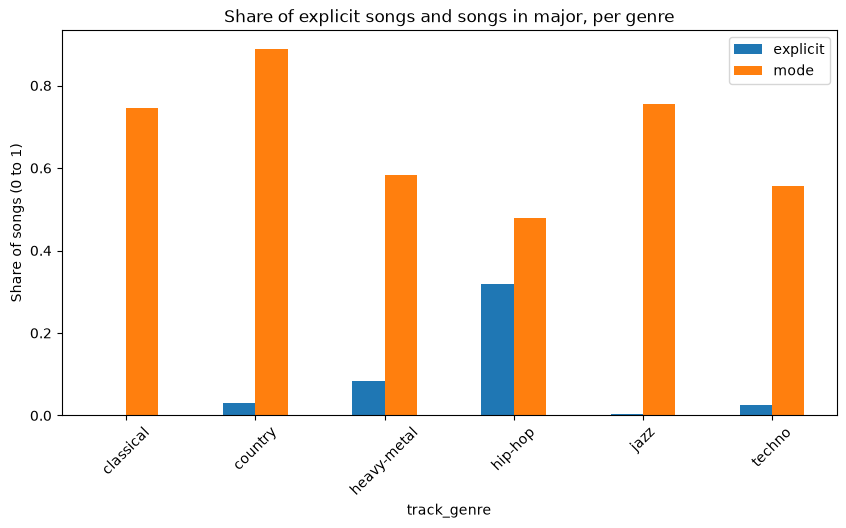

In [89]:
# Share of explicit songs and songs in major, for each genre
share = df.groupby('track_genre')[['explicit', 'mode']].mean()

share.plot(kind='bar', figsize=(10, 5))
plt.title('Share of explicit songs and songs in major, per genre')
plt.ylabel('Share of songs (0 to 1)')
plt.xticks(rotation=45)
plt.show()

### Interpretation

Hip-hop is the only genre with a lot of explicit songs, about 32%. The other genres have very few, and classical and jazz have almost none. This means explicit can help the model recognise hip-hop, but it won't help much to tell the other genres apart.

For mode, country has the most songs in major, close to 90%, while hip-hop is about half major and half minor. Classical and jazz are mostly in major too, while heavy-metal and techno are more mixed. There are some differences, but they are not as big as for features like acousticness or energy.

In [90]:
# How many songs in each genre have each time signature
pd.crosstab(df['track_genre'],df['time_signature'])

time_signature,0,1,3,4,5
track_genre,,,,,
classical,0,42,226,691,41
country,0,1,116,877,6
heavy-metal,0,3,47,945,5
hip-hop,0,11,23,948,18
jazz,1,17,144,807,31
techno,0,3,26,969,2


### Interpretation

Almost every song in every genre has a time signature of 4, which is the most common rhythm in music. The main exception is classical and jazz, which have more songs in 3 than the other genres (226 and 144). This is the rhythm used in waltzes. Classical also has more songs in 1 and 5, which are unusual rhythms.

This means time_signature can help a little to recognise classical and jazz, but for the other genres it is almost always 4.

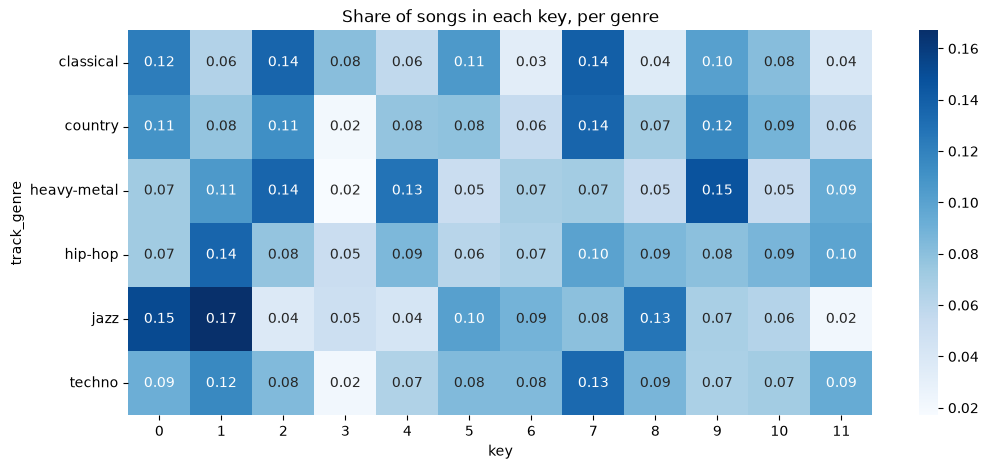

In [91]:
# Share of songs in each key, for each genre
key_share = pd.crosstab(df['track_genre'], df['key'], normalize='index')

plt.figure(figsize=(12, 5))
sns.heatmap(key_share, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of songs in each key, per genre')
plt.show()

### Interpretation

If songs were spread completely evenly across the 12 keys, each square would be about 0.08, since 1 divided by 12 is about 0.08.

Most squares are close to that, but some genres lean towards certain keys. Jazz has more songs in key 0 and key 1 (0.15 and 0.17) and very few in key 11 (0.02). Heavy-metal has more songs in key 9 (0.15) and key 2 (0.14). Key 3 is rare in almost every genre.

So key shows some differences between the genres, but they are smaller than for the audio features. It might help the model a little, together with the other features.

## EDA summary

### What I found

The full dataset has 114,000 songs across 114 genres, with 1,000 songs in each genre. Many genres share songs. For example, singer-songwriter and songwriter share all 1,000 songs, and pairs like punk and punk-rock share more than half. A model can't separate genres that contain the same songs, so I chose six genres that share almost no songs: classical, country, heavy-metal, hip-hop, jazz and techno. This gives 6,000 songs, perfectly balanced, so a random guess would be right about 17% of the time.

In the six genres there are no missing values. There are 79 exact duplicate rows, and 11 songs are listed under two of my genres. One song has a tempo and time signature of 0, which means Spotify couldn't measure its beat. The biggest problem is the re-released recordings: 1,249 rows are copies of another recording with a different track_id, mostly in jazz, country and hip-hop.

The features that separate the genres best are acousticness, energy, loudness, instrumentalness and danceability. Speechiness and explicit mostly help to recognise hip-hop, and tempo mostly helps to recognise techno. Time signature helps a little for classical and jazz. Liveness looks almost the same for every genre, and duration mostly helps to recognise techno, which has the longest songs. No single feature separates all six genres. For example, classical and jazz are both calm and acoustic, but classical usually has no vocals while jazz does. So the models will need to combine several features.

Popularity only has weak relationships with the audio features (at most 0.30), and a third of the songs have a popularity of 0, mostly in jazz, country and classical. It says something about listeners, not about how a song sounds.

### My decisions for preprocessing

Based on the EDA, this is what I will do with the data.

I already dropped Unnamed: 0 at the start, since it is just a row number. I also drop track_id, which is Spotify's ID for a song and says nothing about the music. I use track_id to find duplicates first, and drop it after that. I also drop artists, album_name and track_name, because they are names and not sound. If I kept them, the model could learn who made a song instead of how it sounds.

I remove the exact duplicates, the songs that are listed under two genres, and the re-released copies, where I keep one copy of each recording. Duplicates and copies could end up in both the training and the test data, and a song with two different genres would confuse the model. I also remove the song with a tempo of 0, since its tempo is missing and not really 0.

I keep the outliers. They are real songs, and they are often exactly what makes a genre different.

Some choices I don't make myself, but test as processing alternatives in the tuning. I test keeping and dropping popularity, since it might help the score, but it is not about the sound, so I compare both at the end. I test the skewed features with and without a power transform, since some models are sensitive to skew and others are not. I test one-hot encoding key and time_signature against keeping them as numbers, since a higher number doesn't mean "more", but trees can still split on the numbers. And I test different ways of scaling.

I keep all the correlated features. Two pairs go above my threshold of 0.8 (energy with loudness, and energy with acousticness), but the features still carry different information, and trees handle similar features well. Finally, explicit is turned into 1 and 0, since it is True/False.

Scaling matters because some numerical features have very different ranges. For example, energy goes from 0 to 1, while duration is measured in thousands of milliseconds. This affects distance-based models like KNN and the neural networks, so I test different ways of scaling the numerical features in preprocessing.

# PREPROCESSING

In this part I carry out the decisions from the EDA summary. First I clean the data, then I prepare the features and the label for the models.

## Cleaning

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
- https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html

In [92]:
# Remove exact duplicate rows
df = df.drop_duplicates()
print(f"Rows after removing exact duplicates: {len(df)}")

Rows after removing exact duplicates: 5921


In [93]:
# Find songs that are listed under more than one genre
genres_per_song = df.groupby('track_id')['track_genre'].nunique()
songs_in_two_genres = genres_per_song[genres_per_song > 1].index

# Remove all copies of those songs, since we can't know which genre is the right one
df = df[~df['track_id'].isin(songs_in_two_genres)]
print(f"Songs listed under two genres: {len(songs_in_two_genres)}")
print(f"Rows left: {len(df)}")

Songs listed under two genres: 11
Rows left: 5899


In [94]:
# Remove re-released copies: keep one copy of every recording, based on the audio features only.
# I save the data before this step, so I can show afterwards how much the copies would have mattered.
df_with_copies = df.copy()

df = df.drop_duplicates(subset=audio_cols)
print(f"Re-released copies removed: {len(df_with_copies) - len(df)}")
print(f"Rows left: {len(df)}")

Re-released copies removed: 1248
Rows left: 4651


In [95]:
# Remove songs where Spotify couldn't measure a tempo
df = df[df['tempo'] != 0]
print(f"Rows left: {len(df)}")
print(df['track_genre'].value_counts())

Rows left: 4650
track_genre
heavy-metal    991
techno         974
classical      805
hip-hop        747
country        633
jazz           500
Name: count, dtype: int64


### Interpretation

After cleaning, 4,650 songs are left. Most of the removed rows were re-released copies (1,248). The rest were exact duplicates (79), songs listed under two genres (22 rows from 11 songs) and the song with a tempo of 0.

Removing the copies changed the balance between the genres a lot. Heavy-metal (991) and techno (974) kept almost all their songs, but jazz went down to 500 and country to 633. So the dataset is not balanced anymore: heavy-metal now has about twice as many songs as jazz.

I still think removing the copies is the right choice, because a model that is tested on copies of its training songs gives results that are too good (I show how much below). But the imbalance changes a few things for the rest of the project. I use a stratified split, so every genre has the same share in the training and the test data. I use the macro average for precision, recall and F1, which gives every genre the same weight, because accuracy alone would favour the big genres. For the tree models I tune class_weight (None or 'balanced'), which can give the smaller genres more weight during training, like I did in my first project. And since a random guess is no longer exactly 1/6, I measure it with a DummyClassifier before the real models.

### How much would the re-released copies have mattered?

To see why removing the copies is important, I repeat the split on the data that still has the copies and train one Gradient Boosting model with default settings. Here I use HistGradientBoostingClassifier, the fast version, since this is only a quick check. Then I compare two groups of test songs: songs that have an identical copy in the training data, and songs that are truly new.

Sources:

- https://scikit-learn.org/stable/common_pitfalls.html
- https://www.geeksforgeeks.org/machine-learning/data-leakage/
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

In [96]:
# The data before the copies were removed (without the tempo 0 song), split the same way as below
leaky = df_with_copies[df_with_copies['tempo'] != 0]
leaky_train = leaky.groupby('track_genre').sample(frac=0.8, random_state=random_state)
leaky_test = leaky.drop(leaky_train.index)

# A test song is "already seen" if a song with exactly the same audio values is in the training data
train_recordings = set(leaky_train[audio_cols].apply(tuple, axis=1))
already_seen = leaky_test[audio_cols].apply(tuple, axis=1).isin(train_recordings).to_numpy()
print(f"Test songs with an identical copy in the training data: {already_seen.sum()} of "
      f"{len(leaky_test)} ({already_seen.mean():.1%})")

# One Gradient Boosting model with default settings
input_cols = audio_cols + ['popularity']
leaky_model = HistGradientBoostingClassifier(random_state=random_state)
leaky_model.fit(leaky_train[input_cols], leaky_train['track_genre'])
leaky_pred = leaky_model.predict(leaky_test[input_cols])

true_genres = leaky_test['track_genre'].to_numpy()
print(f"\nMacro F1, all test songs:     {f1_score(true_genres, leaky_pred, average='macro'):.3f}")
print(f"Macro F1, already seen songs: {f1_score(true_genres[already_seen], leaky_pred[already_seen], average='macro'):.3f}")
print(f"Macro F1, truly new songs:    {f1_score(true_genres[~already_seen], leaky_pred[~already_seen], average='macro'):.3f}")

Test songs with an identical copy in the training data: 305 of 1180 (25.8%)

Macro F1, all test songs:     0.926
Macro F1, already seen songs: 1.000
Macro F1, truly new songs:    0.884


### Interpretation

Without removing the copies, 305 of the 1,180 test songs (25.8%) would have an identical copy in the training data. That is about one in four test songs.

The model gets a macro F1 of 1.000 on these songs: every single one is correct, because the model has already seen exactly the same values with the right genre. On the truly new songs, the F1 is only 0.884. All together the score would have been 0.926, which looks better than what the model can actually do on new songs.

This is exactly the kind of data leakage I wanted to avoid, and the same thing would happen inside the cross-validation, so the tuning would also be too optimistic. With the copies removed, the scores in the rest of the notebook are lower than in my first version, but they are honest: they show how well the models do on songs they have really never seen.

## Dropping columns

Here I drop the columns that don't describe how a song sounds.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html

In [97]:
# Keep the song names in a separate table, so I can look up the songs the models get wrong at the end
song_info = df[['track_name', 'artists', 'album_name']].copy()

# Drop columns that are names or IDs, not audio features.
# track_id is dropped now, since I'm done using it to find duplicates.
df = df.drop(columns=['track_id', 'artists', 'album_name', 'track_name'])

print(f"Columns left: {list(df.columns)}")

Columns left: ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


### Interpretation

I dropped track_id, artists, album_name and track_name. They are IDs and names, and they don't describe how a song sounds. If I kept the artist, for example, the model could learn who made a song instead of how it sounds. Popularity stays for now, because I test keeping and dropping it in the tuning. This leaves 15 features and the genre as the label. The song names are saved in song_info, so I can look at them in the error analysis at the end.

## Encoding

Models need numbers. Here I turn explicit into numbers, and separate the features from the label.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html
- https://www.geeksforgeeks.org/machine-learning/ml-label-encoding-of-datasets-in-python/
- https://www.geeksforgeeks.org/machine-learning/what-is-feature-engineering/

In [98]:
# explicit is True/False. Turn it into 1/0 so the models can use it.
df['explicit'] = df['explicit'].astype(int)
print(df['explicit'].value_counts())

explicit
0    4320
1     330
Name: count, dtype: int64


In [99]:
# Separate the features (input) from the label (what we want to predict)
features = df.drop(columns='track_genre')
targets = df['track_genre']

print(f"Features: {features.shape[1]} columns")
print(f"Targets: {targets.nunique()} genres")

Features: 15 columns
Targets: 6 genres


In [100]:
# Turn the genre names into numbers 0 to 5
label_encoder = LabelEncoder()
targets = pd.Series(label_encoder.fit_transform(df['track_genre']), index=df.index)

# Show which number belongs to which genre
for number, genre in enumerate(label_encoder.classes_):
    print(f"{number} = {genre}")

0 = classical
1 = country
2 = heavy-metal
3 = hip-hop
4 = jazz
5 = techno


### Interpretation

Explicit is now 1/0 instead of True/False. The genre names are turned into numbers from 0 to 5 with LabelEncoder. The numbers are just labels and don't mean that one genre is "more" than another. I keep the encoder so I can turn the numbers back into genre names later, for example on the confusion matrices.

I don't encode key and time_signature here, because I want to test two ways of handling them. That choice is part of the pipeline later.

## Train/test split

I split the data into a training set and a test set. The models learn from the training set, and the test set is only used once at the very end, to see how well they do on songs they have never seen.

Unlike in my first project, I don't need a separate validation set. The hyperparameter tuning uses cross-validation, which creates its own validation folds from the training data. I create the folds once with StratifiedKFold, and give the same folds to every model. That way all the models are tuned and compared on exactly the same data.

Sources:

- https://www.geeksforgeeks.org/machine-learning/splitting-data-for-machine-learning-models/
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
- https://www.geeksforgeeks.org/machine-learning/stratified-k-fold-cross-validation/
- https://scikit-learn.org/stable/modules/cross_validation.html
- https://www.geeksforgeeks.org/machine-learning/cross-validation-machine-learning/

In [101]:
# Stratified split: 80% train, 20% test. Wich means both train and test keep approximately the same genre proportions. 
# Sampling 80% from each genre separately keeps the same share of every genre in both sets.
train_indices = df.groupby('track_genre').sample(frac=0.8, random_state=random_state).index
test_indices = df.drop(train_indices).index

# The sampled rows come out sorted by genre. I shuffle the training set once, so the order of the
# rows has nothing to do with the genre. (Keras uses the last 10% of its training data for early
# stopping, so without shuffling that part could contain only one genre.)
train_features = features.loc[train_indices].sample(frac=1, random_state=random_state)
train_targets = targets.loc[train_features.index]

test_features = features.loc[test_indices]
test_targets = targets.loc[test_indices]

# The same 5 folds are used for the tuning of every model.
# shuffle=True mixes the songs before they are divided into folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

print(f"Training songs: {len(train_features)}, test songs: {len(test_features)}\n")

# Checking that every genre has the same share in both sets
shares = pd.DataFrame({'train': train_targets.value_counts(normalize=True),
                       'test': test_targets.value_counts(normalize=True)})
shares.index = label_encoder.classes_[shares.index]
print(shares.round(3))


Training songs: 3720, test songs: 930

             train   test
heavy-metal  0.213  0.213
techno       0.209  0.210
classical    0.173  0.173
hip-hop      0.161  0.160
country      0.136  0.137
jazz         0.108  0.108


### Interpretation

The data is split into 3,720 training songs and 930 test songs. Each genre has almost exactly the same share in both sets, so the split is stratified as intended. The table also shows the imbalance from the cleaning: heavy-metal is 21.3% of the songs, while jazz is only 10.8%.

This means the test set is a fair representation of the training set, and no genre is over- or under-represented when I evaluate the models.

## Pipeline and processing alternatives

Instead of choosing one way to process the data, I set up several alternatives and let the automated tuning compare them. I use a Pipeline with a ColumnTransformer, following the approach from the course workshop.

A pipeline also prevents data leakage. During cross-validation, the processing (for example the scaling) is learned only from the training folds, and then used on the validation fold.

The alternatives come from my EDA. For the skewed features, I test with and without a PowerTransformer (Yeo-Johnson). For scaling, I test no scaling, StandardScaler and MinMaxScaler. Popularity can be kept or dropped. And key and time_signature can be one-hot encoded or kept as numbers.

The trees (the Decision Tree and the tree ensembles) only get the popularity and encoding alternatives. Scaling or a power transform doesn't change a tree: it only changes the numbers, not the order of the songs, so the tree finds exactly the same splits. KNN and the neural networks get all the alternatives, since they work with distances and the size of the values.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
- https://scikit-learn.org/stable/modules/compose.html
- https://www.geeksforgeeks.org/machine-learning/using-columntransformer-in-scikit-learn-for-data-preprocessing/
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html
- https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/
- https://www.digitalocean.com/community/tutorials/understanding-one-hot-encoding-in-machine-learning
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html
- https://scikit-learn.org/stable/modules/preprocessing.html
- https://www.geeksforgeeks.org/machine-learning/standardscaler-minmaxscaler-and-robustscaler-techniques-ml/
- https://www.geeksforgeeks.org/machine-learning/feature-engineering-scaling-normalization-and-standardization/

In [102]:
# Group the columns by how they should be processed
numeric_features = ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
                    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

categorical_features = ['key', 'time_signature']
binary_features = ['explicit', 'mode']

## Preprocessor

The preprocessor describes how each group of columns is processed before the model sees it. Before this step I only did things that follow a fixed rule and don't depend on the data: cleaning, explicit to 1/0 and the genre label. Everything that learns from the data (scaling, power transform, one-hot encoding) is defined here.

Nothing is processed yet. This only defines the steps. The values are calculated when the pipeline is fitted inside GridSearchCV, so the mean and standard deviation come from the training folds only. I make it a function so every model gets its own fresh copy.

StandardScaler subtracts the mean and divides by the standard deviation for each column, the same formula as the mean normalization in my first project. KNN and neural networks need it. Trees don't.

In [103]:
# Build the preprocessing step. Each part below is a default, and the grid search can swap it
# for one of the alternatives.
def make_preprocessor():
    return ColumnTransformer([
        # Numeric features: first an optional power transform, then scaling
        ('numeric', Pipeline([
            ('power', 'passthrough'),
            ('scale', StandardScaler())
        ]), numeric_features),

        # popularity on its own, so it can be kept (scaled) or dropped
        ('popularity', StandardScaler(), ['popularity']),

        # key and time_signature: one-hot encoded by default.
        # handle_unknown='ignore' avoids errors if a rare value only appears in one fold
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),

        # explicit and mode are already 0/1
        ('binary', 'passthrough', binary_features)
    ])

# MODELS

I train two baseline models, five ensemble models (Random Forest, Gradient Boosting, Extra Trees, XGBoost and LightGBM) and two neural networks, plus a stacking ensemble as an extra. Each model is tuned automatically with GridSearchCV or RandomizedSearchCV, using the same 5 cross-validation folds. The processing alternatives are tuned together with the model settings. I use the macro F1 score to compare the settings, so every genre counts the same.

After the tuning, the search automatically trains the best settings again on the whole training set. The test set is not used in this part at all. All the models are tested together in the evaluation part.

For every model I show the best settings and the best cross-validation score. Then summarize_results shows the best score for every value of every tuned setting, show_score shows the average score and the spread over the 5 folds, and plot_search makes a plot of the average score for every value of every setting.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html
- https://scikit-learn.org/stable/modules/grid_search.html
- https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning/
- https://www.geeksforgeeks.org/machine-learning/comparing-randomized-search-and-grid-search-for-hyperparameter-estimation-in-scikit-learn/
- https://seaborn.pydata.org/generated/seaborn.barplot.html
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

In [104]:
# Short names for the processing objects, so the tables and plots are easier to read
def short_name(value):
    names = {"OneHotEncoder(handle_unknown='ignore')": 'one-hot',
             'StandardScaler()': 'StandardScaler',
             'MinMaxScaler()': 'MinMaxScaler',
             'PowerTransformer()': 'PowerTransformer'}
    return names.get(str(value), str(value))


# Puts parameter values in a natural order: numbers from small to large first, then text
def value_order(labels):
    def key(label):
        try:
            return (0, float(label), '')
        except ValueError:
            return (1, 0, label)
    return sorted(set(labels), key=key)


# Prints the best cross-validation score for every value of every tuned parameter.
def summarize_results(search):

    cv_results = pd.DataFrame(search.cv_results_)
    
    for col in cv_results.columns:
        if col.startswith('param_'):
            # fillna('None') makes sure max_depth=None is included in the table
            values = cv_results[col].fillna('None').map(short_name)
            best_per_value = cv_results.groupby(values)['mean_test_score'].max()
            best_per_value = best_per_value.reindex(value_order(best_per_value.index)).rename_axis(None)
            print(f"\n{col.replace('param_', '')}:")
            print(best_per_value.round(3).to_string())


# Prints the mean score and the spread over the 5 folds for the best settings of one search
def show_score(name, search):
    best = pd.DataFrame(search.cv_results_).loc[search.best_index_]
    print(f"\n{name}: {best['mean_test_score']:.3f} ± {best['std_test_score']:.3f}")


# One bar plot per tuned parameter. Each bar is the AVERAGE score over all the other settings
# (summarize_results shows the BEST score), so the plots show how much a parameter matters in general.
def plot_search(search, ncols=3):
    results = pd.DataFrame(search.cv_results_)
    params = [col for col in results.columns if col.startswith('param_')]
    nrows = int(np.ceil(len(params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
    axes = np.array(axes).flatten()
    low, high = results['mean_test_score'].min(), results['mean_test_score'].max()
    for ax, col in zip(axes, params):
        values = results[col].fillna('None').map(short_name)
        sns.barplot(x=values, y=results['mean_test_score'], order=value_order(values), ax=ax,
                    color='steelblue', errorbar=None)
        ax.set_title(col.replace('param_', ''))
        ax.set_xlabel('')
        ax.set_ylabel('mean CV macro F1')
        ax.set_ylim(low - 0.02, high + 0.01)    # zoomed in so small differences are visible
        ax.tick_params(axis='x', rotation=20)
    for ax in axes[len(params):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

## Reference: random guessing

Before the real models, I measure what random guessing scores. DummyClassifier with strategy='uniform' picks a random genre for every song. Every real model has to beat this.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html
- https://www.geeksforgeeks.org/machine-learning/ml-dummy-classifiers-using-sklearn/
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html

In [105]:
dummy = DummyClassifier(strategy='uniform', random_state=random_state)
dummy_scores = cross_val_score(dummy, train_features, train_targets, cv=cv, scoring='f1_macro')
print(f"Random guessing, macro F1: {dummy_scores.mean():.3f} ± {dummy_scores.std():.3f}")

# Fitted on the training data for the test comparison later
dummy.fit(train_features, train_targets);


Random guessing, macro F1: 0.162 ± 0.009


### Interpretation

Random guessing gets a macro F1 of 0.162 ± 0.009. This is close to 1/6 ≈ 0.17, which makes sense for six genres. This is the score every model has to beat.

## Baseline: Decision Tree

A decision tree asks a series of yes/no questions about the features, for example "is acousticness above 0.8?", and ends in a leaf with a genre. It is easy to understand, but a deep tree can memorize the training data, so max_depth and min_samples_leaf are important to tune.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- https://www.geeksforgeeks.org/machine-learning/decision-tree-introduction-example/
- https://www.geeksforgeeks.org/machine-learning/handling-imbalanced-data-for-classification/

In [106]:
dt_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', DecisionTreeClassifier(random_state=random_state))
])

dt_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__max_depth': [4, 8, 12, 16, None],
    'estimator__min_samples_leaf': [1, 5, 10],
    'estimator__criterion': ['gini', 'entropy'],
    'estimator__class_weight': [None, 'balanced']     # give the smaller genres more weight or not
}

dt_grid = GridSearchCV(dt_pipe, dt_params, cv=cv, scoring='f1_macro', n_jobs=-1)
dt_grid.fit(train_features, train_targets)

print(f"Best settings: {dt_grid.best_params_}")
print(f"Best cross-validation F1: {dt_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': None, 'estimator__criterion': 'entropy', 'estimator__max_depth': 16, 'estimator__min_samples_leaf': 5, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.779



estimator__class_weight:
None        0.779
balanced    0.767

estimator__criterion:
entropy    0.779
gini       0.772

estimator__max_depth:
4       0.685
8       0.772
12      0.776
16      0.779
None    0.779

estimator__min_samples_leaf:
1     0.772
5     0.779
10    0.766

preprocess__categorical:
one-hot        0.776
passthrough    0.779

preprocess__popularity:
StandardScaler    0.779
drop              0.726

Decision Tree: 0.779 ± 0.007


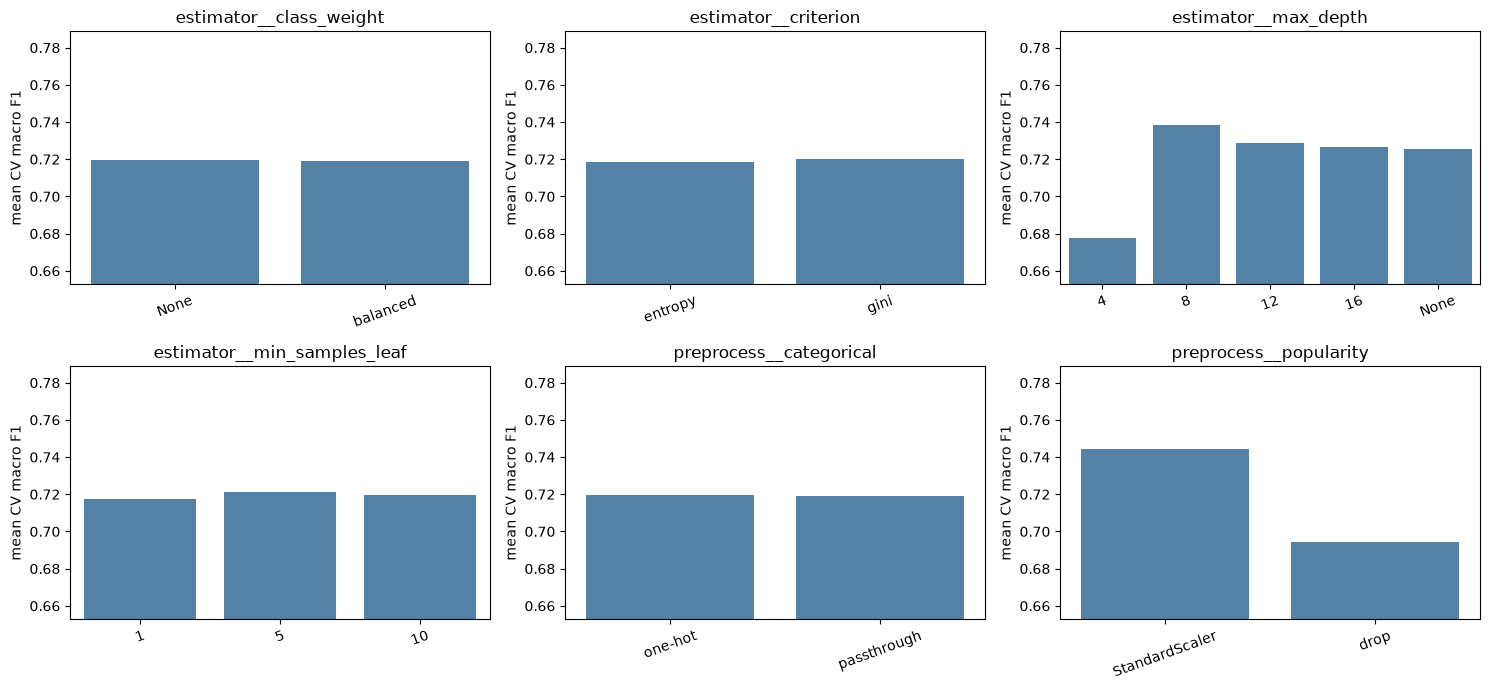

In [107]:
summarize_results(dt_grid)
show_score('Decision Tree', dt_grid)
plot_search(dt_grid)

### Interpretation

The best Decision Tree reaches a macro F1 of 0.779 ± 0.007 in cross-validation. This is far above random guessing (0.162), but it is the lowest of all my models.

The best settings are max_depth=16, min_samples_leaf=5 and entropy, without class weights. For max_depth, the score jumps from 0.685 at depth 4 to 0.772 at depth 8, and then levels out: depth 16 and no limit both give 0.779. So the range I tested is wide enough, and a deeper tree doesn't help. For min_samples_leaf, 5 is in the middle of the range and works best, so forcing every leaf to contain at least 5 songs helps the tree a little against overfitting. Gini and entropy give almost the same result (0.772 and 0.779).

class_weight='balanced' doesn't help here (0.767 vs 0.779). Keeping key and time_signature as numbers is slightly better than one-hot encoding (0.779 vs 0.776). This makes sense for a tree, since it can split directly on a number, while one-hot encoding spreads key over 12 separate columns.

Keeping popularity gives the biggest improvement of all the settings, from 0.726 to 0.779. I still think part of this comes from a shortcut, since jazz and country have many songs with popularity 0. I look closer at this in the further analysis.

## Baseline: K-Nearest Neighbors (KNN)

KNN predicts the genre of a song by looking at the most similar songs in the training data. Since it measures distances between songs, it is sensitive to the scale of the features. This is where the scaling and power transform alternatives matter most.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
- https://www.geeksforgeeks.org/machine-learning/k-nearest-neighbours/
- https://www.geeksforgeeks.org/machine-learning/feature-engineering-scaling-normalization-and-standardization/

In [108]:
knn_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', KNeighborsClassifier())
])

knn_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': ['passthrough', StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__n_neighbors': [5, 11, 21, 31, 51, 75, 101],
    'estimator__weights': ['uniform', 'distance'],
    'estimator__p': [1, 2]
}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=cv, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(train_features, train_targets)

print(f"Best settings: {knn_grid.best_params_}")
print(f"Best cross-validation F1: {knn_grid.best_score_:.3f}")

Best settings: {'estimator__n_neighbors': 11, 'estimator__p': 1, 'estimator__weights': 'distance', 'preprocess__numeric__power': PowerTransformer(), 'preprocess__numeric__scale': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.793



estimator__n_neighbors:
5      0.779
11     0.793
21     0.791
31     0.787
51     0.776
75     0.775
101    0.765

estimator__p:
1    0.793
2    0.776

estimator__weights:
distance    0.793
uniform     0.785

preprocess__numeric__power:
PowerTransformer    0.793
passthrough         0.783

preprocess__numeric__scale:
MinMaxScaler      0.750
StandardScaler    0.793
passthrough       0.793

preprocess__popularity:
StandardScaler    0.793
drop              0.754

KNN: 0.793 ± 0.011


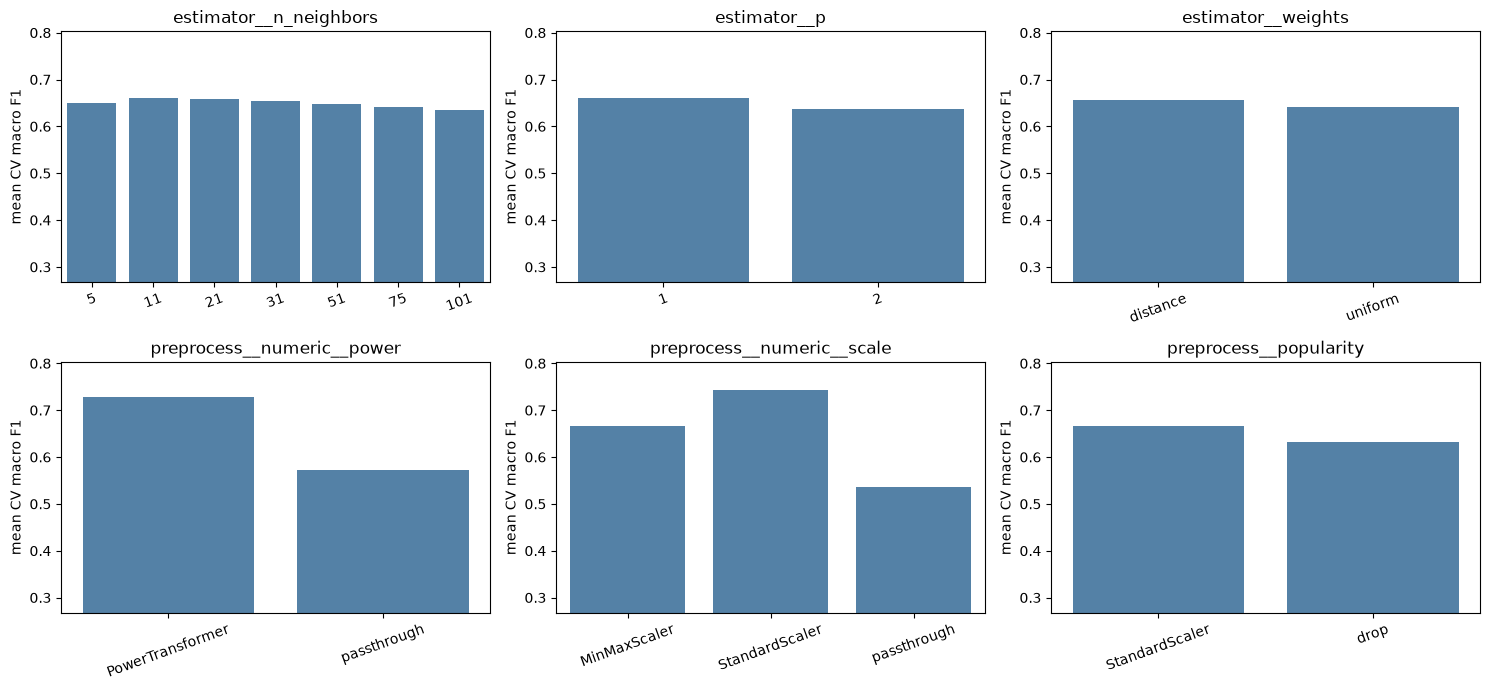

In [109]:
summarize_results(knn_grid)
show_score('KNN', knn_grid)
plot_search(knn_grid)

### Interpretation

The best KNN reaches a macro F1 of 0.793 ± 0.011, a bit better than the Decision Tree (0.779).

The best number of neighbours is 11, which is in the middle of the range I tested (5 to 101). With 5 neighbours the score is lower (0.779), because the vote depends on very few songs. From 21 neighbours and up it slowly drops (0.765 at 101), because songs that are far away also get a vote. So the range is wide enough.

The plots show that the processing matters much more for KNN than the model settings. Without any scaling, the average score is only about 0.54, compared to about 0.74 with StandardScaler, because features with large values like duration_ms dominate the distance between songs. The PowerTransformer also helps a lot on average (about 0.73 vs 0.57), which fits with the skewed features I found in the EDA. This confirms what I expected.

The best combination uses the PowerTransformer without an extra scaler. This looks strange at first, but the PowerTransformer already standardizes the values by default, so the data is still scaled. With StandardScaler after it, the score is the same (0.793).

Giving closer songs a bigger vote (distance) works better than giving every neighbour the same vote (0.793 vs 0.785), and Manhattan distance (p=1) works better than Euclidean distance (0.793 vs 0.776). Keeping popularity improves the score from 0.754 to 0.793.

## Ensemble: Random Forest

A Random Forest trains many decision trees, each on a random part of the data and with a random selection of features. The final prediction is a vote between all the trees. Combining many trees usually reduces overfitting compared to a single tree.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/
- https://scikit-learn.org/stable/modules/ensemble.html

In [110]:
rf_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', RandomForestClassifier(random_state=random_state))
])

rf_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 300],
    'estimator__max_depth': [10, 20, None],
    'estimator__max_features': ['sqrt', 'log2'],
    'estimator__class_weight': [None, 'balanced']
}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv=cv, scoring='f1_macro', n_jobs=-1)
rf_grid.fit(train_features, train_targets)

print(f"Best settings: {rf_grid.best_params_}")
print(f"Best cross-validation F1: {rf_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': 'balanced', 'estimator__max_depth': 20, 'estimator__max_features': 'sqrt', 'estimator__n_estimators': 300, 'preprocess__categorical': 'passthrough', 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.850



estimator__class_weight:
None        0.843
balanced    0.850

estimator__max_depth:
10      0.837
20      0.850
None    0.849

estimator__max_features:
log2    0.85
sqrt    0.85

estimator__n_estimators:
100    0.844
300    0.850

preprocess__categorical:
one-hot        0.843
passthrough    0.850

preprocess__popularity:
StandardScaler    0.850
drop              0.793

Random Forest: 0.850 ± 0.006


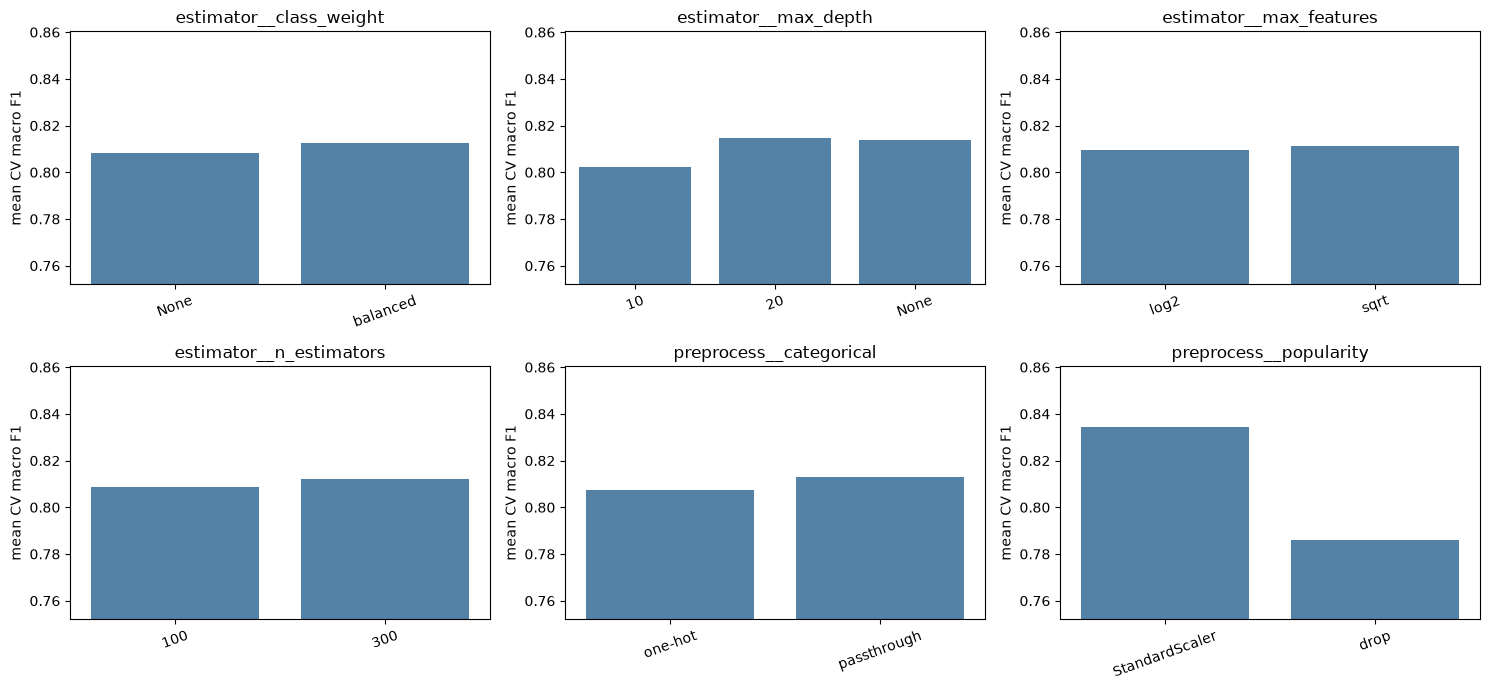

In [111]:
summarize_results(rf_grid)
show_score('Random Forest', rf_grid)
plot_search(rf_grid)

### Interpretation

The best Random Forest reaches a macro F1 of 0.850 ± 0.006, clearly better than both baselines (0.779 and 0.793).

Deeper trees are better up to a point: 0.837 for depth 10 and 0.850 for depth 20. No limit gives the same score (0.849), so the range is wide enough. 300 trees are slightly better than 100 (0.850 vs 0.844). 300 is the largest value I tested, so more trees might give a tiny improvement, but the gain from 100 to 300 is already small, and more trees make the model slower. Sqrt and log2 give exactly the same score. With 15 columns, both settings give 3 features per split (√15 ≈ 3.9 and log2(15) ≈ 3.9, rounded down), so they are actually the same setting here.

This is the first model where class_weight='balanced' helps (0.850 vs 0.843). When the smaller genres, like jazz and country, get more weight, the forest finds more of their songs.

Popularity has the biggest effect again: 0.850 with it and 0.793 without it.

## Ensemble: Gradient Boosting

Gradient Boosting also combines many decision trees, but in a different way than a Random Forest. A Random Forest builds its trees independently and lets them vote. Gradient Boosting builds the trees one after another, and every new tree focuses on the mistakes the previous trees made.

I use GradientBoostingClassifier, which is the classic version of Gradient Boosting in scikit-learn. With six genres it builds six trees at every step, one for each genre, so it is slower than the other ensembles. My dataset is small enough for that.

I tune the learning rate (how much every new tree is allowed to correct), the number of trees, the depth of each tree and subsample (the share of the songs each tree learns from), together with popularity and the encoding of key and time_signature. GradientBoostingClassifier has no class_weight setting, so I don't tune that here.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- https://www.geeksforgeeks.org/machine-learning/ml-gradient-boosting/
- https://scikit-learn.org/stable/modules/ensemble.html

In [112]:
gb_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', GradientBoostingClassifier(random_state=random_state))
])

gb_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__learning_rate': [0.05, 0.1, 0.2],
    'estimator__n_estimators': [100, 300],
    'estimator__max_depth': [3, 5],
    'estimator__subsample': [0.8, 1.0]      # share of the songs each tree learns from
}

gb_grid = GridSearchCV(gb_pipe, gb_params, cv=cv, scoring='f1_macro', n_jobs=-1)
gb_grid.fit(train_features, train_targets)

print(f"Best settings: {gb_grid.best_params_}")
print(f"Best cross-validation F1: {gb_grid.best_score_:.3f}")

Best settings: {'estimator__learning_rate': 0.2, 'estimator__max_depth': 5, 'estimator__n_estimators': 100, 'estimator__subsample': 1.0, 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.865



estimator__learning_rate:
0.05    0.864
0.1     0.863
0.2     0.865

estimator__max_depth:
3    0.859
5    0.865

estimator__n_estimators:
100    0.865
300    0.864

estimator__subsample:
0.8    0.864
1.0    0.865

preprocess__categorical:
one-hot        0.865
passthrough    0.864

preprocess__popularity:
StandardScaler    0.865
drop              0.785

Gradient Boosting: 0.865 ± 0.009


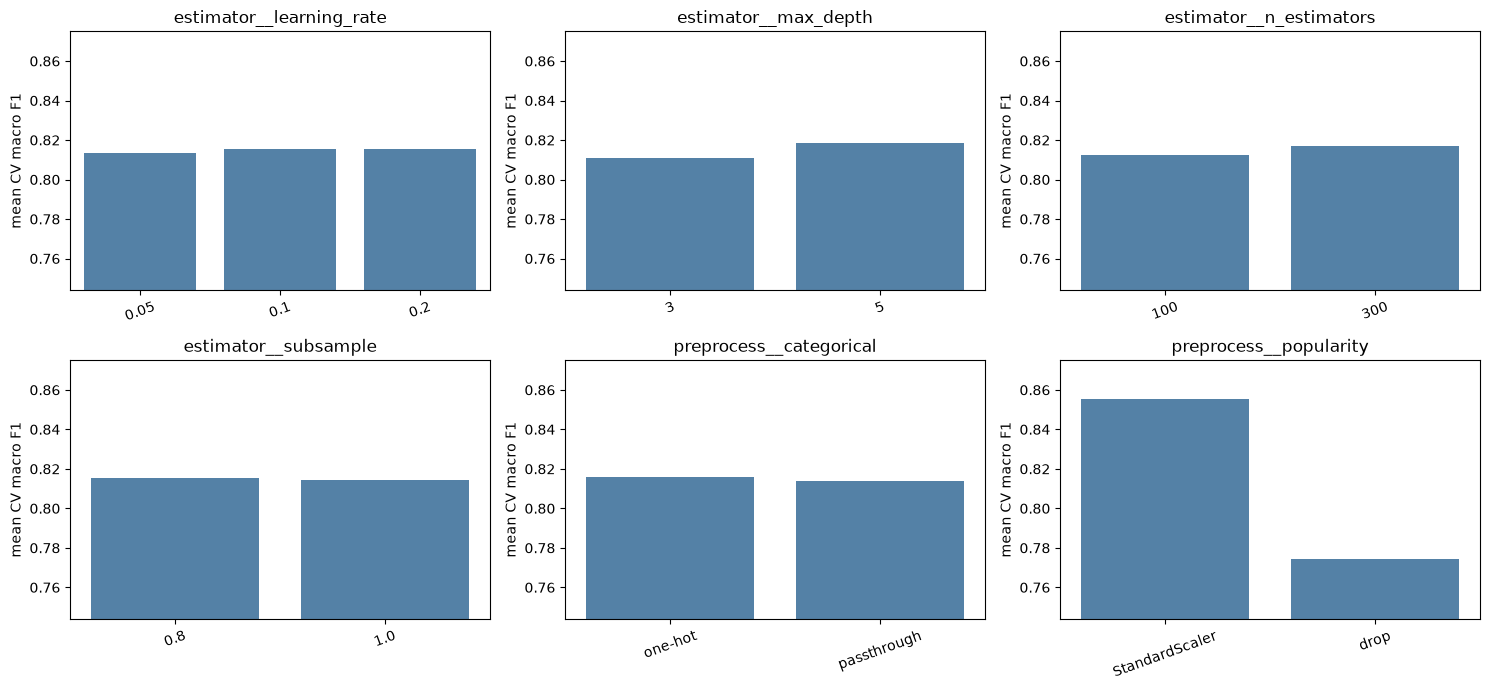

In [113]:
summarize_results(gb_grid)
show_score('Gradient Boosting', gb_grid)
plot_search(gb_grid)

In [114]:
# The 5 fold scores behind the average of the best settings
fold_columns = [f'split{i}_test_score' for i in range(5)]
print(pd.DataFrame(gb_grid.cv_results_).loc[gb_grid.best_index_, fold_columns].astype(float).round(3).to_string())

split0_test_score    0.858
split1_test_score    0.871
split2_test_score    0.853
split3_test_score    0.868
split4_test_score    0.877


### Interpretation

The best Gradient Boosting reaches a macro F1 of 0.865 ± 0.009 in cross-validation, the best model so far. It is 0.015 better than the Random Forest (0.850 ± 0.006). That gap is bigger than the spread between the folds, so I think Gradient Boosting really is better than the Random Forest, and not just lucky. The five fold scores are between 0.853 and 0.877.

The best settings are a learning rate of 0.2, a depth of 5, 100 trees and subsample 1.0, with popularity kept and key and time_signature one-hot encoded. Depth 5 is clearly better than depth 3 (0.865 vs 0.859), so the trees need to be a bit deeper to find the patterns. The other settings make almost no difference: the three learning rates give between 0.863 and 0.865, 100 and 300 trees give 0.865 and 0.864, and subsample 0.8 and 1.0 give 0.864 and 0.865.

One-hot encoding of key and time_signature is only a tiny bit better than keeping them as numbers (0.865 vs 0.864). Popularity has the biggest effect again: 0.865 with it and 0.785 without it.

Because it builds six trees at every step, this is the slowest of the tree ensembles to train. I come back to the training times in the evaluation.

## Ensemble: Extra Trees

Extra Trees is very similar to a Random Forest: many decision trees that vote together. The difference is that a Random Forest searches for the best split value, while Extra Trees picks the split values at random. This makes each tree a bit weaker, but the trees are more different from each other, and the model trains faster.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html
- https://www.geeksforgeeks.org/machine-learning/ml-extra-tree-classifier-for-feature-selection/

In [115]:
et_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', ExtraTreesClassifier(random_state=random_state))
])

extrees_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 300],          # how many trees
    'estimator__max_depth': [10, 20, 30, None],
    'estimator__max_features': ['sqrt', 0.5, 1.0],  # share of the features each split can choose from
    'estimator__class_weight': [None, 'balanced']
}

extrees_grid = GridSearchCV(et_pipe, extrees_params, cv=cv, scoring='f1_macro', n_jobs=-1)
extrees_grid.fit(train_features, train_targets)

print(f"Best settings: {extrees_grid.best_params_}")
print(f"Best cross-validation F1: {extrees_grid.best_score_:.3f}")

Best settings: {'estimator__class_weight': None, 'estimator__max_depth': 20, 'estimator__max_features': 1.0, 'estimator__n_estimators': 300, 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'preprocess__popularity': StandardScaler()}
Best cross-validation F1: 0.851



estimator__class_weight:
None        0.851
balanced    0.849

estimator__max_depth:
10      0.836
20      0.851
30      0.849
None    0.850

estimator__max_features:
0.5     0.850
1.0     0.851
sqrt    0.835

estimator__n_estimators:
100    0.850
300    0.851

preprocess__categorical:
one-hot        0.851
passthrough    0.850

preprocess__popularity:
StandardScaler    0.851
drop              0.783

Extra Trees: 0.851 ± 0.010


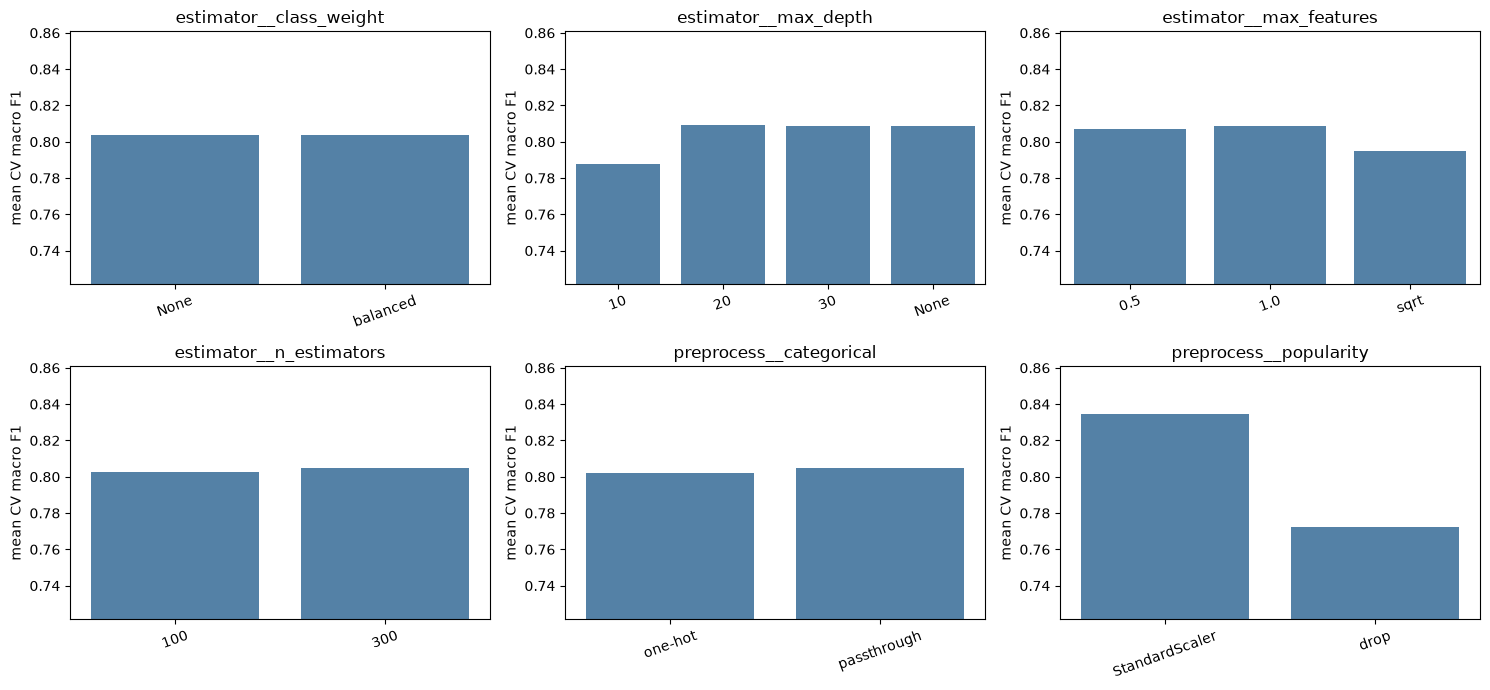

In [116]:
summarize_results(extrees_grid)
show_score('Extra Trees', extrees_grid)
plot_search(extrees_grid)

### Interpretation

The best Extra Trees reaches a macro F1 of 0.851 ± 0.010. This is the same as the Random Forest (0.850 ± 0.006) and below Gradient Boosting (0.865).

A depth of 10 is too shallow (0.836), but from depth 20 the score levels out (0.849 to 0.851), so a deeper forest would not help. 100 and 300 trees give almost the same score. For max_features, sqrt is clearly worse (0.835) than half of the features (0.850) or all of them (0.851). This is the opposite of the Random Forest. I think this is because Extra Trees picks its split values at random, so each split needs more features to choose from to find a good one.

class_weight makes almost no difference (0.851 vs 0.849), and neither does the encoding (0.851 vs 0.850). Popularity has the biggest effect again: 0.851 with it and 0.783 without it.

## Ensemble: XGBoost

XGBoost ("Extreme Gradient Boosting") is one of the most popular machine learning libraries, and it has won many Kaggle competitions as ive heard. Like Gradient Boosting, it builds trees one after another, where every new tree corrects the mistakes of the trees before. Compared to scikit-learn's version, it has more built-in ways to avoid overfitting, for example colsample_bytree, which lets every tree use only a random part of the features, and reg_lambda, a penalty that keeps the trees careful.

XGBoost was one of my best models, so I tune a lot of settings here: the number of trees, the depth of each tree, the learning rate, subsample, colsample_bytree (the share of the features each tree can use), min_child_weight (how much data a leaf needs, where a bigger value gives simpler trees) and reg_lambda (a penalty that keeps the trees more careful). I tune them together with popularity and the encoding of key and time_signature. That is far too many combinations to test all of them, so I use RandomizedSearchCV, which tests 100 random combinations. XGBoost has no class_weight setting, so I don't tune that here. n_jobs=1 makes every XGBoost model use one CPU core, since the search already trains several models at the same time.

Sources:

- https://xgboost.readthedocs.io/en/stable/python/python_api.html
- https://xgboost.readthedocs.io/en/stable/parameter.html
- https://xgboost.readthedocs.io/en/stable/tutorials/model.html
- https://www.geeksforgeeks.org/machine-learning/xgboost/

In [117]:
xgb_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', XGBClassifier(random_state=random_state, n_jobs=1))
])

xgb_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 200, 300, 500],
    'estimator__max_depth': [3, 4, 6, 8],
    'estimator__learning_rate': [0.03, 0.05, 0.1, 0.2],
    'estimator__subsample': [0.7, 0.8, 1.0],          # share of the songs each tree learns from
    'estimator__colsample_bytree': [0.6, 0.8, 1.0],   # share of the features each tree can use
    'estimator__min_child_weight': [1, 3, 5],         # how much data a leaf needs, bigger = simpler trees
    'estimator__reg_lambda': [0.5, 1, 2, 5]           # penalty that keeps the trees careful, bigger = more careful
}

# There are far too many combinations to test all of them, so I test 100 random ones
xgb_grid = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=100, cv=cv, scoring='f1_macro',
                              random_state=random_state, n_jobs=-1)
xgb_grid.fit(train_features, train_targets)

print(f"Best settings: {xgb_grid.best_params_}")
print(f"Best cross-validation F1: {xgb_grid.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'estimator__subsample': 0.7, 'estimator__reg_lambda': 2, 'estimator__n_estimators': 200, 'estimator__min_child_weight': 3, 'estimator__max_depth': 8, 'estimator__learning_rate': 0.05, 'estimator__colsample_bytree': 0.6}
Best cross-validation F1: 0.869



preprocess__popularity:
StandardScaler    0.869
drop              0.792

preprocess__categorical:
one-hot        0.869
passthrough    0.868

estimator__subsample:
0.7    0.869
0.8    0.868
1.0    0.865

estimator__reg_lambda:
0.5    0.865
1.0    0.868
2.0    0.869
5.0    0.867

estimator__n_estimators:
100    0.864
200    0.869
300    0.868
500    0.868

estimator__min_child_weight:
1    0.868
3    0.869
5    0.865

estimator__max_depth:
3    0.859
4    0.865
6    0.868
8    0.869

estimator__learning_rate:
0.03    0.868
0.05    0.869
0.1     0.865
0.2     0.865

estimator__colsample_bytree:
0.6    0.869
0.8    0.868
1.0    0.867

XGBoost: 0.869 ± 0.005


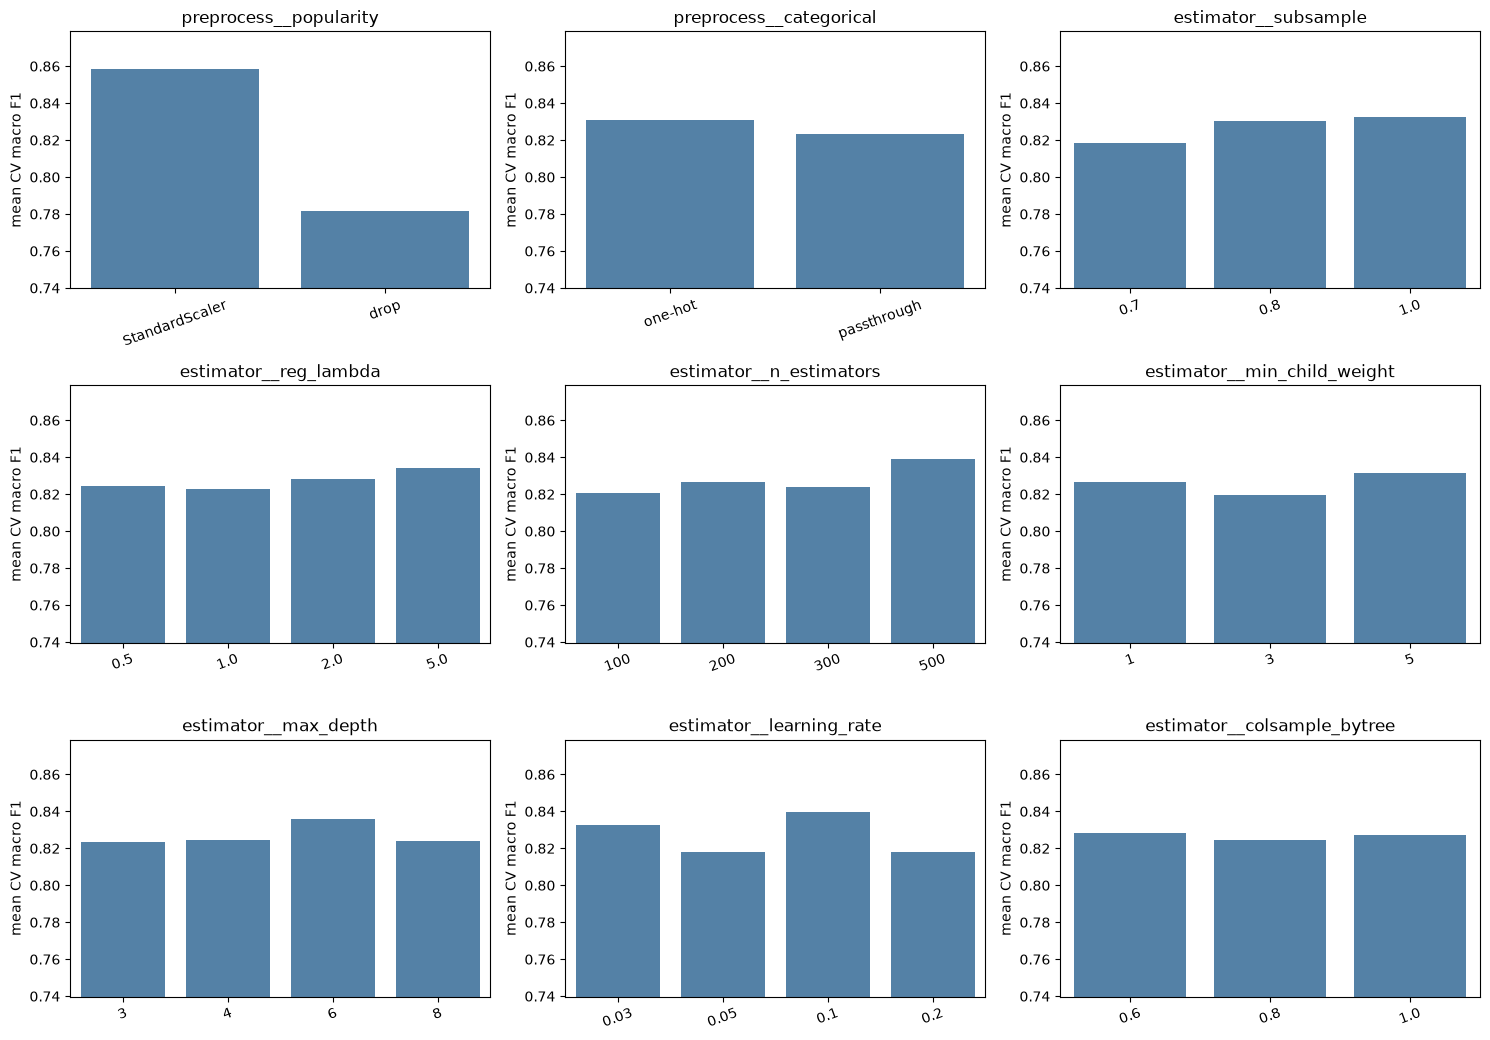

In [118]:
summarize_results(xgb_grid)
show_score('XGBoost', xgb_grid)
plot_search(xgb_grid)

### Interpretation

With the bigger search, the best XGBoost reaches a macro F1 of 0.869 ± 0.005 in cross-validation. That is a bit above Gradient Boosting (0.865 ± 0.009), and the spread between the folds (0.005) is the smallest of all my models, so XGBoost is very stable.

The best settings are 200 trees with a depth of 8, a learning rate of 0.05, subsample 0.7, colsample_bytree 0.6, min_child_weight 3 and reg_lambda 2, with popularity kept and key and time_signature one-hot encoded. What I find interesting is that the best model uses quite deep trees (depth 8), but at the same time it only lets each tree see 70% of the songs and 60% of the features. My thinking is that the deep trees can learn detailed patterns, while the randomness keeps them from memorizing the training songs.

Most of the settings only change the best score a little. A depth of 3 is clearly the worst (0.859), and 100 trees are a bit worse than 200 (0.864 vs 0.869), but after that more trees don't help (0.868 for both 300 and 500). The learning rates 0.03 and 0.05 are slightly better than 0.1 and 0.2 (0.868 and 0.869 vs 0.865). Using all the songs for every tree (subsample 1.0) is a bit worse than 0.7 (0.865 vs 0.869). Popularity has the biggest effect again: 0.869 with it and 0.792 without it.

The bar plots look a bit messier here than for the grid searches. That is because a random search tests random combinations, so every bar is the average of different combinations of the other settings. The best score for each value, in the list above the plots, is easier to compare.

## Ensemble: LightGBM

LightGBM is Microsoft's Gradient Boosting library, and together with XGBoost it is one of the most used models for tabular data. The main difference is how the trees grow. Most libraries grow a tree level by level, while LightGBM always splits the leaf that improves the model the most. That is why its most important setting is the number of leaves (num_leaves) instead of the depth.

I tune the number of trees, the number of leaves, the learning rate, min_child_samples (how many songs a leaf needs at least), subsample and colsample_bytree (the share of the songs and of the features each tree can use), reg_lambda (a penalty that keeps the trees more careful) and class_weight, together with popularity and the encoding. Like for XGBoost, I use RandomizedSearchCV with 100 random combinations. subsample_freq=1 is needed so that LightGBM actually uses subsample, and verbose=-1 turns off LightGBM's many training messages.

Sources:

- https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMClassifier.html
- https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html
- https://www.geeksforgeeks.org/machine-learning/lightgbm-light-gradient-boosting-machine/

In [119]:
lgbm_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    # subsample_freq=1 is needed, otherwise LightGBM ignores subsample
    ('estimator', LGBMClassifier(random_state=random_state, n_jobs=1, verbose=-1, subsample_freq=1))
])

lgbm_params = {
    # Processing alternatives
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__n_estimators': [100, 200, 300, 500],
    'estimator__num_leaves': [15, 31, 63],
    'estimator__learning_rate': [0.03, 0.05, 0.1],
    'estimator__min_child_samples': [10, 20, 40],     # how many songs a leaf needs at least
    'estimator__subsample': [0.7, 0.8, 1.0],          # share of the songs each tree learns from
    'estimator__colsample_bytree': [0.6, 0.8, 1.0],   # share of the features each tree can use
    'estimator__reg_lambda': [0, 1, 5],               # penalty that keeps the trees careful
    'estimator__class_weight': [None, 'balanced']
}

# Like for XGBoost, I test 100 random combinations
lgbm_grid = RandomizedSearchCV(lgbm_pipe, lgbm_params, n_iter=100, cv=cv, scoring='f1_macro',
                               random_state=random_state, n_jobs=-1)
lgbm_grid.fit(train_features, train_targets)

print(f"Best settings: {lgbm_grid.best_params_}")
print(f"Best cross-validation F1: {lgbm_grid.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__categorical': OneHotEncoder(handle_unknown='ignore'), 'estimator__subsample': 1.0, 'estimator__reg_lambda': 0, 'estimator__num_leaves': 63, 'estimator__n_estimators': 200, 'estimator__min_child_samples': 10, 'estimator__learning_rate': 0.03, 'estimator__colsample_bytree': 0.6, 'estimator__class_weight': None}
Best cross-validation F1: 0.872



preprocess__popularity:
StandardScaler    0.872
drop              0.795

preprocess__categorical:
one-hot        0.872
passthrough    0.869

estimator__subsample:
0.7    0.870
0.8    0.869
1.0    0.872

estimator__reg_lambda:
0    0.872
1    0.871
5    0.867

estimator__num_leaves:
15    0.866
31    0.871
63    0.872

estimator__n_estimators:
100    0.865
200    0.872
300    0.871
500    0.869

estimator__min_child_samples:
10    0.872
20    0.869
40    0.871

estimator__learning_rate:
0.03    0.872
0.05    0.871
0.1     0.868

estimator__colsample_bytree:
0.6    0.872
0.8    0.868
1.0    0.868

estimator__class_weight:
None        0.872
balanced    0.868

LightGBM: 0.872 ± 0.008


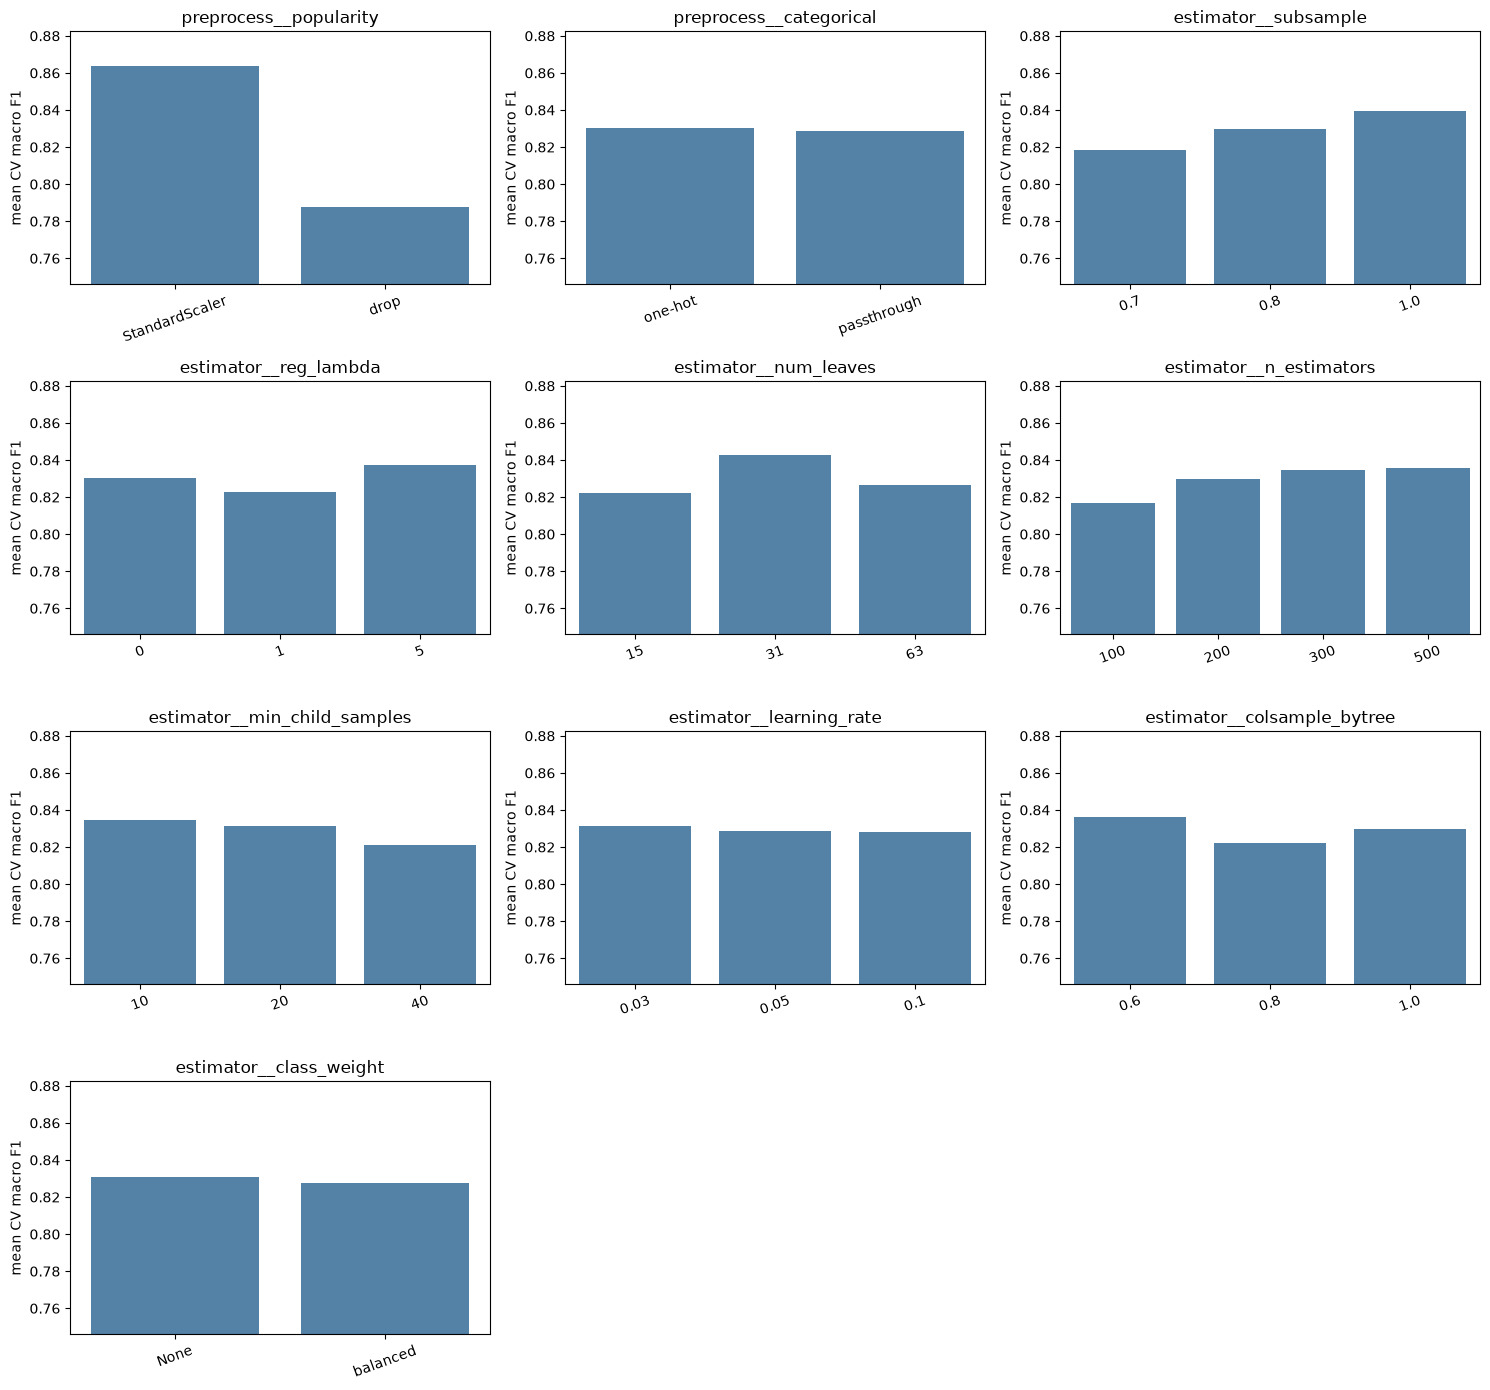

In [120]:
summarize_results(lgbm_grid)
show_score('LightGBM', lgbm_grid)
plot_search(lgbm_grid)

### Interpretation

The best LightGBM reaches a macro F1 of 0.872 ± 0.008, which is the highest cross-validation score of all my single models. It is just above XGBoost (0.869) and Gradient Boosting (0.865), but the differences between the three boosting models are smaller than the spread between the folds, so I can't say that one of them is really better.

The best settings are 200 trees, 63 leaves, a learning rate of 0.03, min_child_samples 10, subsample 1.0, colsample_bytree 0.6 and reg_lambda 0, without class weights, with popularity kept and key and time_signature one-hot encoded. Like XGBoost, the best LightGBM only lets each tree look at 60% of the features (0.872, against 0.868 for both 0.8 and 1.0). 15 leaves are clearly too few (0.866), while 31 and 63 leaves are almost the same (0.871 and 0.872). 200 trees are better than 100 (0.872 vs 0.865), and more trees don't help after that.

class_weight='balanced' doesn't help here (0.868 vs 0.872), and neither does a stronger penalty (reg_lambda 5 gives 0.867). Popularity matters the most again: 0.872 with it and 0.795 without it.

Like for XGBoost, the bar plots show averages over random combinations, so I look mostly at the best score for each value.

# ARTIFICIAL NEURAL NETWORKS

## What is a neural network?

A neural network is a model that learns to make predictions from examples. In this project, it gets the processed numbers for a song, like energy, acousticness and duration, and tries to predict the genre. It doesn't know from the start what "high energy" or "classical music" means. Instead, it looks at a lot of songs where the genre is known, and slowly learns which combinations of numbers belong to each genre.

The network is made of layers of small calculations called neurons. Each neuron takes some input values and gives each of them a weight. The weight decides how much that input matters: a positive weight pushes the result up, and a negative weight pushes it down. Each neuron also has a bias, which works like a starting point. The weights and biases start as small random numbers and are adjusted during training.

After adding up its inputs, a neuron uses an activation function. In the hidden layers, a common one is ReLU, which turns negative values into 0 and keeps positive values. Activation functions are important, because they let the network learn more complicated patterns than straight lines. With several layers, the network can learn more and more useful combinations of the song features.

At the end, the network gives a score for every genre. Softmax turns these scores into probabilities that add up to 100%. For example, the model might say 70% jazz, 20% classical and 10% country, and then it chooses jazz.

During training, the network compares its probabilities with the true genre and calculates a loss, which is a number for how wrong it was. A low loss means it gave a high probability to the right genre, and a high loss means it was confident but wrong. With backpropagation and gradient descent, the network makes small changes to its weights and biases to make the loss smaller. By repeating this over many songs and many rounds, the network gets better at predicting the genre.

I train two neural networks: an MLPClassifier from scikit-learn, and a network that I build myself with Keras.

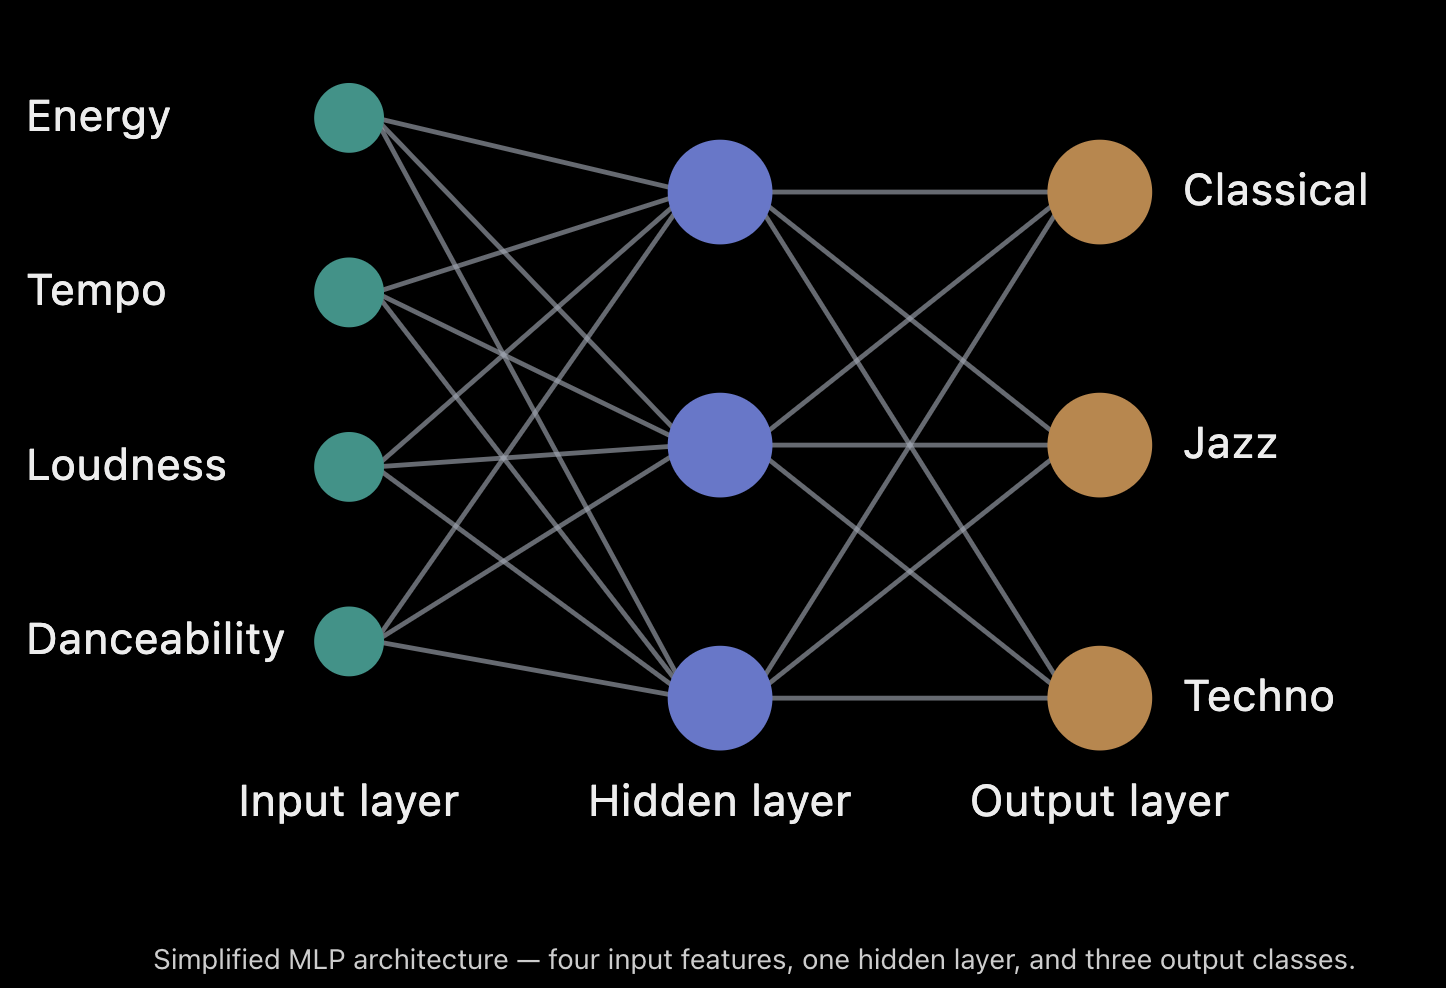

Sources:

- https://scikit-learn.org/stable/modules/neural_networks_supervised.html
- https://www.geeksforgeeks.org/deep-learning/multi-layer-perceptron-learning-in-tensorflow/

## ANN 1: MLPClassifier

MLPClassifier is scikit-learn's neural network. I tune the size of the hidden layers, the activation function, the regularization (alpha) and the learning rate, together with the processing alternatives. With early_stopping=True it keeps 10% of its training data aside and stops when the score on that part stops improving. There are many combinations, so I use RandomizedSearchCV, which tests 40 random combinations instead of all of them.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html
- https://www.geeksforgeeks.org/machine-learning/regularization-by-early-stopping/
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html

In [121]:
mlp_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', MLPClassifier(max_iter=300,early_stopping=True, random_state=random_state))
])

In [122]:
mlp_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__numeric__scale': [StandardScaler(), MinMaxScaler()],
    'preprocess__popularity': ['drop', StandardScaler()],
    'preprocess__categorical': [OneHotEncoder(handle_unknown='ignore'), 'passthrough'],
    # Model parameters
    'estimator__hidden_layer_sizes': [(64,), (128, 64), (128, 64, 32)],
    'estimator__activation': ['relu', 'tanh'],
    'estimator__alpha': [1e-4, 1e-3, 1e-2],
    'estimator__learning_rate_init': [1e-3, 3e-3, 1e-2, 3e-2]
}

In [123]:
mlp_search = RandomizedSearchCV(mlp_pipe, mlp_params, n_iter=40, cv=cv, scoring='f1_macro',
                                random_state=random_state, n_jobs=-1)
mlp_search.fit(train_features, train_targets)

print(f"Best settings: {mlp_search.best_params_}")
print(f"Best cross-validation F1: {mlp_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__scale': StandardScaler(), 'preprocess__numeric__power': 'passthrough', 'preprocess__categorical': 'passthrough', 'estimator__learning_rate_init': 0.003, 'estimator__hidden_layer_sizes': (128, 64, 32), 'estimator__alpha': 0.001, 'estimator__activation': 'tanh'}
Best cross-validation F1: 0.814



preprocess__popularity:
StandardScaler    0.814
drop              0.758

preprocess__numeric__scale:
MinMaxScaler      0.812
StandardScaler    0.814

preprocess__numeric__power:
PowerTransformer    0.812
passthrough         0.814

preprocess__categorical:
one-hot        0.807
passthrough    0.814

estimator__learning_rate_init:
0.001    0.797
0.003    0.814
0.01     0.812
0.03     0.803

estimator__hidden_layer_sizes:
(128, 64)        0.799
(128, 64, 32)    0.814
(64,)            0.803

estimator__alpha:
0.0001    0.807
0.001     0.814
0.01      0.797

estimator__activation:
relu    0.797
tanh    0.814

MLP: 0.814 ± 0.012


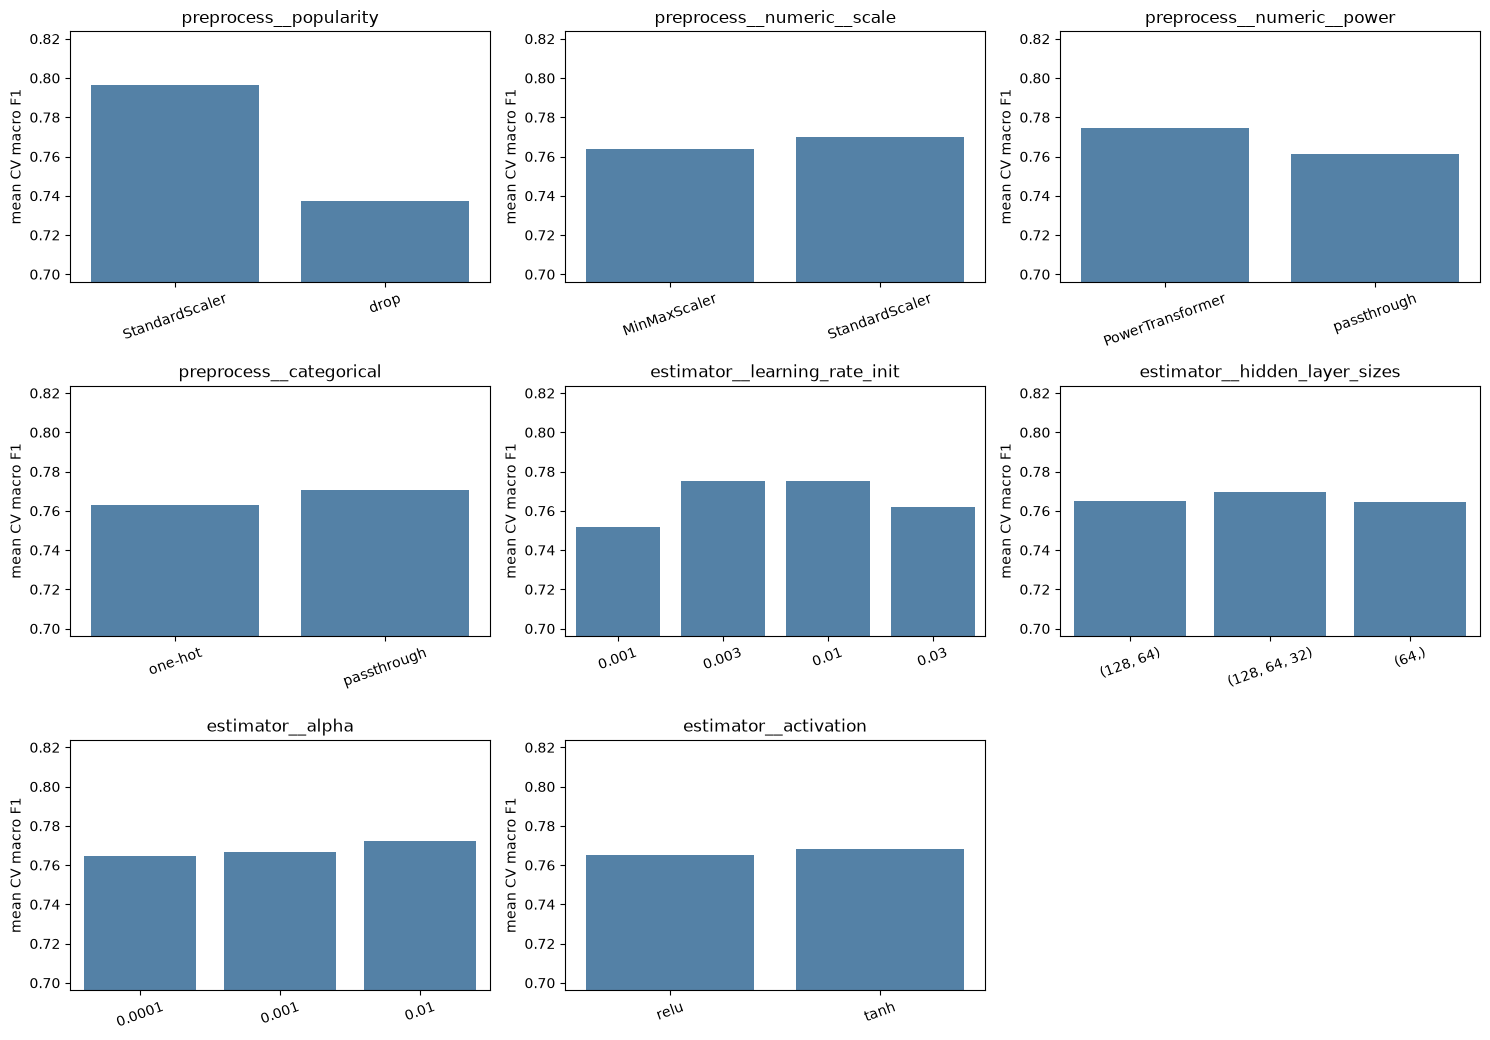

In [124]:
summarize_results(mlp_search)
show_score('MLP', mlp_search)
plot_search(mlp_search)

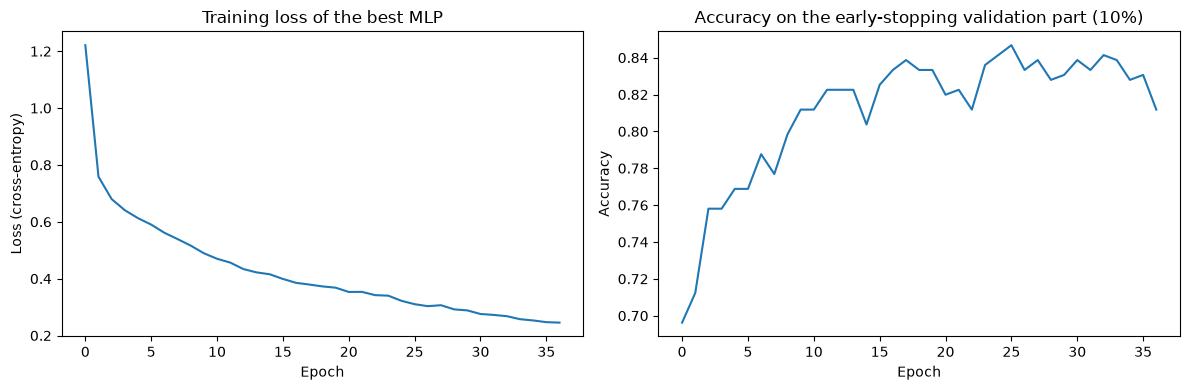

In [125]:
best_mlp = mlp_search.best_estimator_.named_steps['estimator']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_mlp.loss_curve_)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (cross-entropy)')
axes[0].set_title('Training loss of the best MLP')

axes[1].plot(best_mlp.validation_scores_)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy on the early-stopping validation part (10%)')
plt.tight_layout()
plt.show()

### Interpretation

The best MLP reaches a macro F1 of 0.814 ± 0.012. That is better than the two baselines (0.779 and 0.793), but clearly worse than the five tree ensembles (0.850 to 0.872).

The best network has three hidden layers (128, 64 and 32 neurons), the tanh activation, alpha=0.001 and a learning rate of 0.003. The learning rate and alpha are both in the middle of the ranges I tested: a learning rate of 0.001 is too slow (0.797) and 0.03 is too big (0.803), and the strongest regularization (alpha=0.01) is too strong (0.797). Tanh is better than ReLU (0.814 vs 0.797). The biggest network is the best, but the difference to the smaller ones is small.

For the processing, StandardScaler is slightly better than MinMaxScaler (0.814 vs 0.812), and the PowerTransformer doesn't help (0.812 vs 0.814). Keeping key and time_signature as numbers is better than one-hot (0.814 vs 0.807). Popularity has the biggest effect again: 0.814 with it and 0.758 without it.

The plots show the training of the best MLP. The training loss keeps falling the whole time. The accuracy on the early-stopping validation part goes up quickly at first, but after about 15 to 25 epochs it stops improving and goes up and down between 0.81 and 0.85. This is the start of overfitting: the network keeps learning the training data, but it doesn't get better on new data. Early stopping ends the training when the validation score hasn't improved for 10 epochs, which happened after about 37 epochs.

## ANN 2: Keras network

Keras is a library for building neural networks layer by layer, and it is the tool we used in the course. I build the network myself with keras.Sequential. It starts with an input layer that has one input per processed feature. Then come one to three hidden layers (Dense) with ReLU activation. After each hidden layer there is a dropout layer, which turns off a random share of the neurons during training, so the network can't rely too much on single neurons. This helps against overfitting. At the end there is an output layer with one neuron per genre and softmax, which gives one probability per genre.

The loss is sparse_categorical_crossentropy, which is the cross-entropy loss for labels stored as numbers (0 to 5). The optimizer is Adam. EarlyStopping stops the training when the validation loss hasn't improved for 10 epochs, and goes back to the best weights.

Keras runs on top of a "backend" that does the actual calculations. I use PyTorch, which I set in the first code cell. To use the Keras network in a scikit-learn Pipeline and RandomizedSearchCV, I wrap it in KerasClassifier from the scikeras library.

Neural network training uses random numbers, so the Keras results can be a little different between runs.

Sources:

- https://keras.io/getting_started/
- https://keras.io/api/models/sequential/
- https://keras.io/api/layers/core_layers/dense/
- https://keras.io/api/layers/regularization_layers/dropout/
- https://www.geeksforgeeks.org/machine-learning/dropout-in-neural-networks/
- https://keras.io/api/callbacks/early_stopping/
- https://keras.io/api/losses/probabilistic_losses/
- https://keras.io/api/optimizers/adam/
- https://adriangb.com/scikeras/stable/
- https://adriangb.com/scikeras/stable/generated/scikeras.wrappers.KerasClassifier.html

In [126]:
# Check which versions and which backend are used
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}, scikeras {scikeras.__version__}")

Keras 3.15.1, backend: torch, scikeras 0.13.0


In [127]:
def build_model(meta, hidden_units=(64, 32), dropout=0.0):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(meta["n_features_in_"],)))        # one input per column
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation='relu'))           # a hidden layer
        model.add(keras.layers.Dropout(dropout))                          # switch off a share of neurons
    model.add(keras.layers.Dense(meta["n_classes_"], activation='softmax'))   # output: one probability per genre
    return model

In [128]:
keras_clf = KerasClassifier(
    model=build_model,
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    optimizer__learning_rate=1e-3,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=0,
    random_state=random_state
)

In [129]:
keras_pipe = Pipeline([
    ('preprocess', make_preprocessor()),
    ('estimator', keras_clf)
])

In [130]:
keras_params = {
    # Processing alternatives
    'preprocess__numeric__power': ['passthrough', PowerTransformer()],
    'preprocess__popularity': ['drop', StandardScaler()],
    # Model parameters
    'estimator__model__hidden_units': [(64,), (128, 64), (128, 64, 32)],
    'estimator__model__dropout': [0.0, 0.2, 0.4],
    'estimator__optimizer__learning_rate': [3e-4, 1e-3, 3e-3, 1e-2],
    'estimator__batch_size': [32, 128]
}

In [131]:
# n_jobs=1: the Keras models are trained one at a time, since PyTorch already uses several CPU cores
keras_search = RandomizedSearchCV(keras_pipe, keras_params, n_iter=15, cv=cv, scoring='f1_macro',
                                  random_state=random_state, n_jobs=1)
keras_search.fit(train_features, train_targets)

print(f"Best settings: {keras_search.best_params_}")
print(f"Best cross-validation F1: {keras_search.best_score_:.3f}")

Best settings: {'preprocess__popularity': StandardScaler(), 'preprocess__numeric__power': 'passthrough', 'estimator__optimizer__learning_rate': 0.0003, 'estimator__model__hidden_units': (128, 64, 32), 'estimator__model__dropout': 0.0, 'estimator__batch_size': 32}
Best cross-validation F1: 0.800



preprocess__popularity:
StandardScaler    0.800
drop              0.764

preprocess__numeric__power:
PowerTransformer    0.793
passthrough         0.800

estimator__optimizer__learning_rate:
0.0003    0.800
0.001     0.793
0.003     0.800
0.01      0.798

estimator__model__hidden_units:
(128, 64)        0.798
(128, 64, 32)    0.800
(64,)            0.800

estimator__model__dropout:
0.0    0.800
0.2    0.798
0.4    0.793

estimator__batch_size:
32     0.800
128    0.793

Keras network: 0.800 ± 0.012


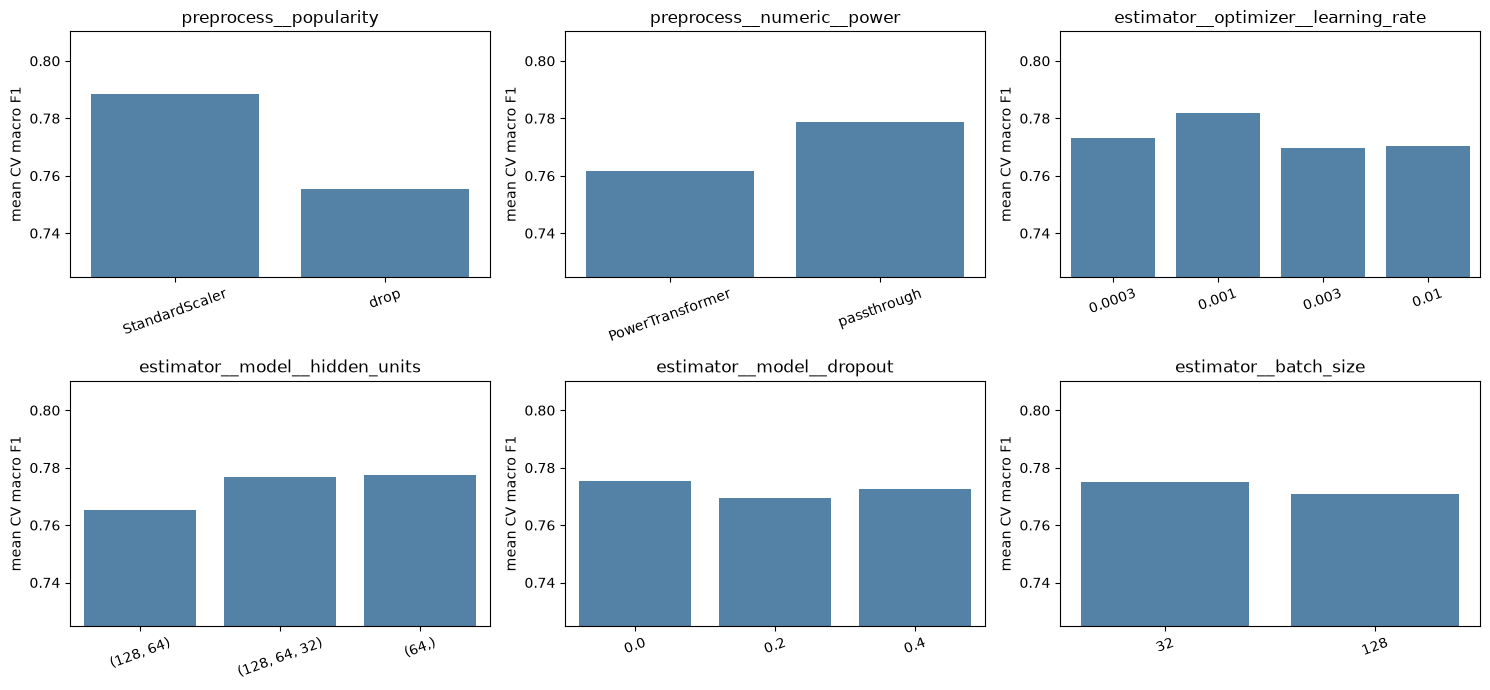

In [132]:
summarize_results(keras_search)
show_score('Keras network', keras_search)
plot_search(keras_search)

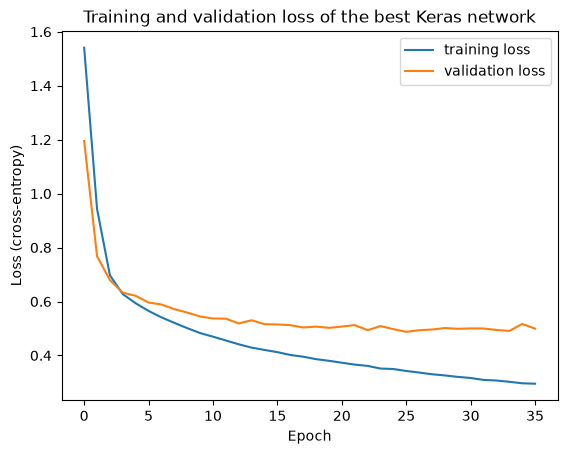

In [133]:
history = keras_search.best_estimator_.named_steps['estimator'].history_

plt.plot(history['loss'], label='training loss')
plt.plot(history['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (cross-entropy)')
plt.title('Training and validation loss of the best Keras network')
plt.legend()
plt.show()

### Interpretation

The best Keras network reaches a macro F1 of 0.800 ± 0.012 in cross-validation, a bit lower than the MLP (0.814).

The best settings are three hidden layers (128, 64 and 32 neurons), no dropout, a learning rate of 0.0003 and a batch size of 32. But most settings give almost the same score: the three network sizes are between 0.798 and 0.800, and the four learning rates between 0.793 and 0.800. These differences are smaller than the spread between the folds (0.012), so I can't say that they matter. 0.0003 is the lowest learning rate I tested, but 0.003 gives the same score, so a lower value probably wouldn't help. Dropout 0.4 is slightly worse (0.793), and small batches are slightly better than big batches (0.800 vs 0.793). The PowerTransformer doesn't help (0.793 vs 0.800). Popularity matters the most again: 0.800 with it and 0.764 without it.

The loss curves show the training of the best network on the whole training set. Both losses fall quickly in the first 5 epochs. After that, the training loss keeps falling, while the validation loss flattens out at about 0.50 from around epoch 15. This is the start of overfitting: the network keeps getting better on the training data, but not on new data. Early stopping ended the training at epoch 35 and went back to the weights from the best epoch.

# EXTRA MODEL: STACKING ENSEMBLE

The assignment is about ensembles, so as an extra I combine some of the best models in a stacking ensemble. The base models (Random Forest, Gradient Boosting, KNN and the MLP) each make a prediction, and a final model (logistic regression) learns how to combine their predicted probabilities. The idea is that different kinds of models make different mistakes, so together they might be better than each one alone.

To train the final model fairly, StackingClassifier uses cross-validation inside the training data: the base models predict songs they were not trained on, and these predictions become the training data for the final model. I tune how many folds it uses for this (cv), and how strongly the final logistic regression is regularized (C). The base models keep the settings they got in their own tuning.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html
- https://www.geeksforgeeks.org/machine-learning/stacking-in-machine-learning/
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [134]:
# The tuned base models from above. Each one keeps its own preprocessing,
# since every model needs different processing (KNN needs scaling, the trees don't).
base_models = [
    ('rf', rf_grid.best_estimator_),
    ('gb', gb_grid.best_estimator_),
    ('knn', knn_grid.best_estimator_),
    ('mlp', mlp_search.best_estimator_),
]

stack = StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(max_iter=1000))

stack_params = {
    'final_estimator__C': [0.01, 0.1, 1, 10],   # smaller C = stronger regularization of the final model
    'cv': [3, 5],                               # folds used to make the training data for the final model
}

stack_grid = GridSearchCV(stack, stack_params, cv=cv, scoring='f1_macro', n_jobs=-1)
stack_grid.fit(train_features, train_targets)

print(f"Best settings: {stack_grid.best_params_}")
print(f"Best cross-validation F1: {stack_grid.best_score_:.3f}")

Best settings: {'cv': 3, 'final_estimator__C': 0.1}
Best cross-validation F1: 0.862



cv:
3    0.862
5    0.861

final_estimator__C:
0.01    0.859
0.1     0.862
1.0     0.860
10.0    0.860

Stacking: 0.862 ± 0.007


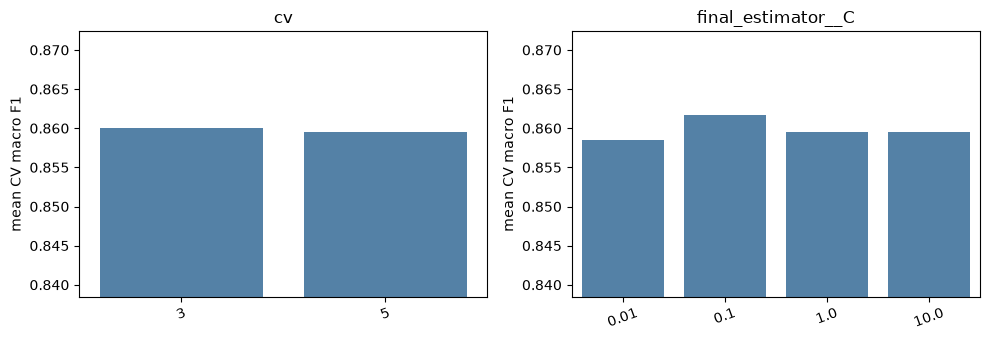

In [135]:
summarize_results(stack_grid)
show_score('Stacking', stack_grid)
plot_search(stack_grid, ncols=2)

### Interpretation

The stacking ensemble reaches a macro F1 of 0.862 ± 0.007. That is a bit lower than the three boosting models: LightGBM (0.872), XGBoost (0.869) and Gradient Boosting (0.865), which is one of its own base models. So combining the four models doesn't help here. It even makes the result a little worse than Gradient Boosting alone.

I think this is because the base models make many of the same mistakes. The biggest problem for all of them is telling country and jazz apart, and when all the base models are unsure about the same songs, the final model has nothing better to choose from. Gradient Boosting is also much stronger than KNN and the MLP, so the weaker base models probably pull the combination down more than they help.

The tuning shows the same thing: all the settings give almost the same score (0.859 to 0.862). Using 3 folds to build the training data for the final model is as good as using 5 (0.862 vs 0.861), and C=0.1 works best, but the differences are very small.

# EVALUATION

## Cross-validation comparison

First I compare all the tuned models on their cross-validation scores. The final model is chosen here, before the test set is used. I also show the score on the training data, to see how much each model overfits, and how long one training run takes.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.barh.html

In [136]:
# All the tuned models in one place. Each search has already refitted its best settings on the whole training set.
searches = {
    'Decision Tree': dt_grid,
    'KNN': knn_grid,
    'Random Forest': rf_grid,
    'Extra Trees': extrees_grid,
    'Gradient Boosting': gb_grid,
    'XGBoost': xgb_grid,
    'LightGBM': lgbm_grid,
    'MLP': mlp_search,
    'Keras network': keras_search,
    'Stacking': stack_grid,
}
best_models = {name: search.best_estimator_ for name, search in searches.items()}

# Cross-validation score, training score and training time of the best settings of every model
rows = {}
for name, search in searches.items():
    best = pd.DataFrame(search.cv_results_).loc[search.best_index_]
    rows[name] = {
        'CV F1': best['mean_test_score'],
        'CV std': best['std_test_score'],
        'Train F1': f1_score(train_targets, search.predict(train_features), average='macro'),
        'Fit time (s)': best['mean_fit_time'],
    }
cv_table = pd.DataFrame(rows).T
cv_table.loc['Random guess'] = [dummy_scores.mean(), dummy_scores.std(), np.nan, np.nan]
cv_table['Train - CV'] = cv_table['Train F1'] - cv_table['CV F1']     # a big gap means overfitting
cv_table = cv_table.astype(float).sort_values('CV F1', ascending=False).round(3)
cv_table

,CV F1,CV std,Train F1,Fit time (s),Train - CV
LightGBM,0.872,0.008,1.000,2.445,0.128
XGBoost,0.869,0.005,0.996,1.985,0.128
Gradient Boosting,0.865,0.009,1.000,8.438,0.135
Stacking,0.862,0.007,1.000,31.973,0.138
Extra Trees,0.851,0.010,1.000,2.282,0.149
Random Forest,0.850,0.006,1.000,1.348,0.150
MLP,0.814,0.012,0.877,0.674,0.063
Keras network,0.800,0.012,0.858,14.435,0.058
KNN,0.793,0.011,1.000,0.136,0.207
Decision Tree,0.779,0.007,0.910,0.030,0.131


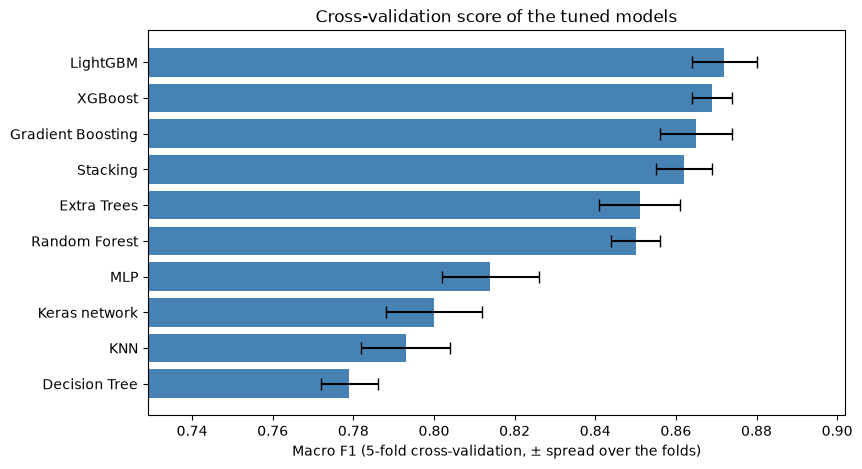

Best CV score: LightGBM (0.872 ± 0.008)
Models within one standard deviation of it: ['LightGBM', 'XGBoost', 'Gradient Boosting']
Final model (the most stable of these): XGBoost


In [137]:
plot_table = cv_table.drop('Random guess')

plt.figure(figsize=(9, 5))
plt.barh(plot_table.index, plot_table['CV F1'], xerr=plot_table['CV std'], color='steelblue', capsize=4)
plt.xlim(plot_table['CV F1'].min() - 0.05, min(1, plot_table['CV F1'].max() + 0.03))
plt.gca().invert_yaxis()             # best model at the top
plt.xlabel('Macro F1 (5-fold cross-validation, ± spread over the folds)')
plt.title('Cross-validation score of the tuned models')
plt.show()

# The final model is chosen on the cross-validation results only, before looking at the test set.
# Rule: start from the best CV score. If other models are within one standard deviation of it, the
# difference could just be noise, so I choose the most stable of those models: the one with the
# smallest spread over the 5 folds. (I first used the training time here, but the training time
# depends on how busy the computer is, so the choice could change from one run to the next.)
best_row = plot_table['CV F1'].idxmax()
best_score = plot_table.loc[best_row, 'CV F1']
best_std = plot_table.loc[best_row, 'CV std']

close_models = plot_table[plot_table['CV F1'] >= best_score - best_std]
best_name = close_models['CV std'].idxmin()

print(f"Best CV score: {best_row} ({best_score:.3f} ± {best_std:.3f})")
print(f"Models within one standard deviation of it: {list(close_models.index)}")
print(f"Final model (the most stable of these): {best_name}")

### Interpretation

The five tree ensembles and the stacking model are clearly the best (0.850 to 0.872), the two neural networks are in the middle (0.800 and 0.814), and the two baselines are the weakest (0.779 and 0.793). All the models are far above random guessing (0.162). The three boosting models are at the top: LightGBM (0.872), XGBoost (0.869) and Gradient Boosting (0.865), followed by the stacking model (0.862).

The Train - CV column shows how much each model overfits. Most of the tree ensembles and KNN score 1.000 on the training data, and XGBoost 0.996. For the ensembles this is normal, since deep trees can remember almost every training song, and it doesn't hurt them because the vote of many different trees still works well on new songs. For KNN, the perfect training score comes from weights='distance': a training song is its own nearest neighbour with a distance of 0, so it always gets its own genre. The two neural networks overfit the least (gaps of about 0.06), because early stopping stops them before they memorize the training data.

The fit time shows what each model costs. XGBoost and LightGBM are fast,  about 2 seconds per training run on my computer. The classic Gradient Boosting takes several times longer, because it builds six trees at every step. The stacking model is the slowest, because it has to train all four base models several times, and the Keras network is also slow. The exact times change a bit every time I run the notebook, depending on how busy the computer is.

Choosing the final model: LightGBM has the best cross-validation score (0.872 ± 0.008). XGBoost (0.869) and Gradient Boosting (0.865) are within one standard deviation of it, so the differences between these three could just be noise. Stacking (0.862) is just outside. I use the rule in the code above and choose the most stable of the three, which is the one with the smallest spread over the 5 folds: XGBoost (± 0.005). Its score is almost the same as LightGBM's, but it changes less from one part of the data to another, so I trust it a bit more.

I first used the training time to break the tie, but the training time depends on how busy the computer is, so the choice could change from one run to the next. The spread doesn't have that problem. I made this choice before looking at the test set.


## Test set results

Now, for the first and only time, I test all the tuned models on the test set, which none of the models have seen. After this, I don't change any model because of these results.

Sources:

- https://scikit-learn.org/stable/modules/model_evaluation.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
- https://www.geeksforgeeks.org/machine-learning/precision-and-recall-in-machine-learning/
- https://www.geeksforgeeks.org/machine-learning/f1-score-in-machine-learning/
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html

In [138]:
test_models = {'Random guess': dummy, **best_models}

test_predictions = {name: model.predict(test_features) for name, model in test_models.items()}
test_probabilities = {name: model.predict_proba(test_features) for name, model in test_models.items()}

In [139]:
test_results = {}
for name, pred in test_predictions.items():
    test_results[name] = {
        'Accuracy': accuracy_score(test_targets, pred),
        'Precision': precision_score(test_targets, pred, average='macro'),
        'Recall': recall_score(test_targets, pred, average='macro'),
        'F1': f1_score(test_targets, pred, average='macro'),
        'ROC-AUC': roc_auc_score(test_targets, test_probabilities[name], multi_class='ovr', average='macro'),
    }

test_results_df = pd.DataFrame(test_results).T
test_results_df['CV F1'] = cv_table['CV F1']                       # to compare with the test F1
test_results_df['Test - CV'] = test_results_df['F1'] - test_results_df['CV F1']
test_results_df = test_results_df.sort_values('F1', ascending=False).round(3)
test_results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1,Test - CV
LightGBM,0.884,0.868,0.866,0.867,0.983,0.872,-0.005
XGBoost,0.881,0.866,0.862,0.863,0.983,0.869,-0.006
Gradient Boosting,0.876,0.862,0.859,0.860,0.980,0.865,-0.005
Stacking,0.870,0.853,0.850,0.851,0.981,0.862,-0.011
Extra Trees,0.858,0.839,0.839,0.838,0.975,0.851,-0.013
Random Forest,0.856,0.837,0.837,0.836,0.977,0.850,-0.014
Keras network,0.852,0.831,0.831,0.831,0.972,0.800,0.031
MLP,0.835,0.814,0.812,0.813,0.973,0.814,-0.001
KNN,0.810,0.789,0.783,0.784,0.962,0.793,-0.009
Decision Tree,0.792,0.774,0.774,0.773,0.908,0.779,-0.006


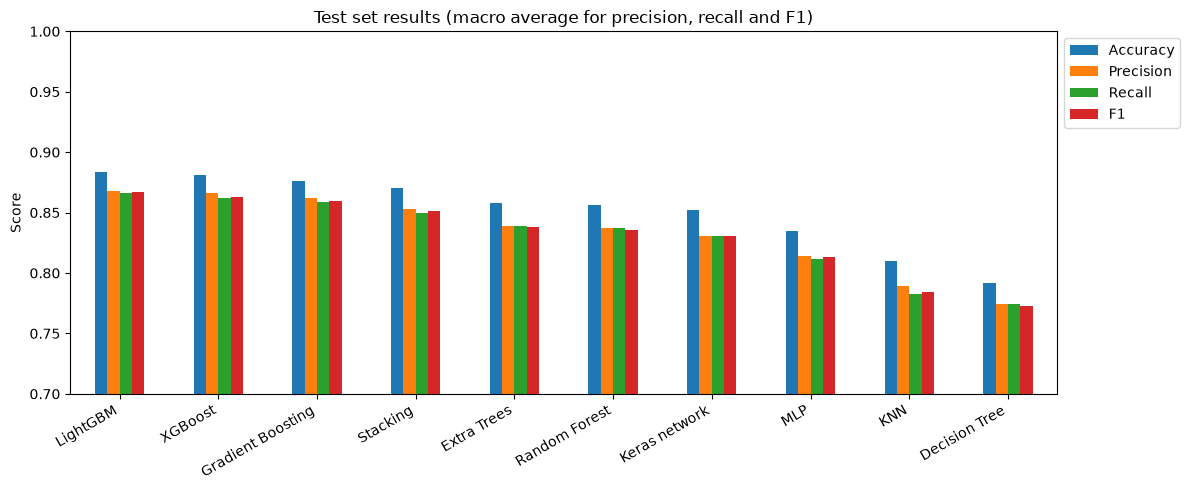

In [140]:
bars = test_results_df.drop('Random guess')[['Accuracy', 'Precision', 'Recall', 'F1']]

bars.plot(kind='bar', figsize=(12, 5))
plt.title('Test set results (macro average for precision, recall and F1)')
plt.ylabel('Score')
plt.ylim(np.floor((bars.min().min() - 0.03) * 20) / 20, 1.0)    # zoomed in so the differences are visible
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))     # outside the plot, so it hides no bars
plt.tight_layout()
plt.show()

### Interpretation

On the test set, the three boosting models are the best. LightGBM has the highest macro F1 (0.867) and accuracy (0.884), followed by my final model, XGBoost, with a macro F1 of 0.863, an accuracy of 0.881, a precision of 0.866 and a recall of 0.862. Gradient Boosting is close behind (0.860), then Stacking (0.851), Extra Trees (0.838) and Random Forest (0.836). The order is almost the same as in the cross-validation, so my choice of the final model holds up on new songs. XGBoost is only 0.004 below LightGBM, which is a very small difference. The Decision Tree is the weakest (F1 0.773), but still far above random guessing (0.158).

The Test - CV column shows that most models score a little lower on the test set than in the cross-validation, by 0.001 to 0.014. This is normal: the tuning picked the settings that happened to work best on the folds, so the CV score is a bit optimistic. The three boosting models have some of the smallest drops (0.005 for LightGBM and Gradient Boosting, and 0.006 for XGBoost), so the tuning didn't overfit to the folds. The Keras network is the exception: it does 0.031 better on the test set than in the cross-validation. I think this is mostly luck, since neural networks vary from run to run, and the final network is trained on all the training data instead of 80% of it.

Accuracy is about 0.02 higher than the macro F1 for every model. This is because of the imbalance: accuracy counts every song, so the big genres like heavy-metal and techno, which are easy, count more. The macro F1 gives the small and difficult genres, jazz and country, the same weight, so it is lower. Precision and recall are almost equal for every model, so the models don't systematically predict too many or too few songs.

All the ROC-AUC values are high (0.908 to 0.983), which means the predicted probabilities rank the songs well, even when the final prediction is wrong.

## Confusion Matrices

Confusion matrices are used to look closer at how the model classifies the different genres. Each row is the true genre and each column is the predicted genre. The diagonal shows the songs the model got right, and every number outside the diagonal is a mistake. With six genres there is no single "positive" class, so instead of TP, TN, FP and FN, the matrix shows exactly which genre each song was mistaken for.

This gives more information than accuracy alone, since we can see which genres the model mixes up. I show one confusion matrix for every model on the test set, the same way as in my first project.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html
- https://www.geeksforgeeks.org/machine-learning/confusion-matrix-machine-learning/
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

In [141]:
# A function for plotting a confusion matrix for a model on test data.
# It also prints how many songs were correct per genre, and the biggest mistakes.
def show_confusion(name):
    genre_names = label_encoder.classes_
    matrix = confusion_matrix(test_targets, test_predictions[name])

    ConfusionMatrixDisplay(matrix, display_labels=genre_names).plot(xticks_rotation=45, colorbar=False)
    plt.title(f'{name} (test set)')
    plt.show()

    correct = np.diag(matrix)
    print(f"Correct: {correct.sum()} of {matrix.sum()} songs ({correct.sum() / matrix.sum():.1%})")
    print("Correct per genre: " + ", ".join(f"{genre} {right}/{total}"
                                             for genre, right, total in zip(genre_names, correct, matrix.sum(axis=1))))
    mistakes = [(matrix[i, j], genre_names[i], genre_names[j])
                for i in range(len(genre_names)) for j in range(len(genre_names)) if i != j and matrix[i, j] > 0]
    print("Biggest mistakes (true -> predicted): " + ", ".join(f"{true} -> {pred}: {count}"
                                                               for count, true, pred in sorted(mistakes, reverse=True)[:5]))

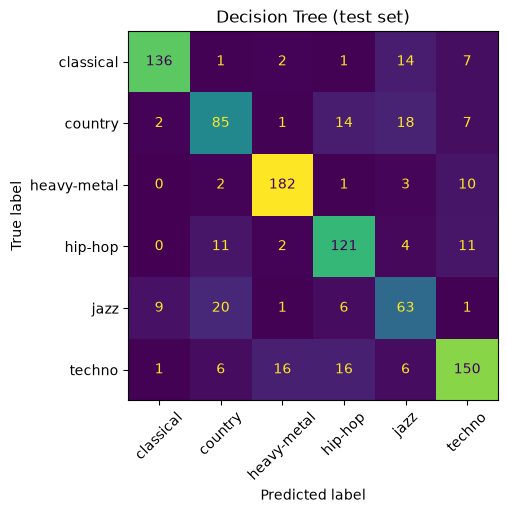

Correct: 737 of 930 songs (79.2%)
Correct per genre: classical 136/161, country 85/127, heavy-metal 182/198, hip-hop 121/149, jazz 63/100, techno 150/195
Biggest mistakes (true -> predicted): jazz -> country: 20, country -> jazz: 18, techno -> hip-hop: 16, techno -> heavy-metal: 16, country -> hip-hop: 14


In [142]:
show_confusion('Decision Tree')

#### Decision Tree confusion matrix:

The confusion matrix shows that the model correctly predicted 737 of the 930 songs (79.2%). Heavy-metal is the easiest genre: 182 of 198 songs are correct. Classical (136 of 161) and techno (150 of 195) also do quite well. Jazz is the hardest genre, only 63 of 100 jazz songs are correct, followed by country with 85 of 127.

The biggest mistakes are between jazz and country: 20 jazz songs were predicted as country, and 18 country songs as jazz. Techno is mixed up with both heavy-metal and hip-hop (16 songs each), 14 classical songs were predicted as jazz, and 14 country songs as hip-hop.

So the Decision Tree finds the very different genres well, but has problems with the genres that sound similar. A single tree makes hard yes/no splits, so songs that are close to a split value easily end up in the wrong genre.

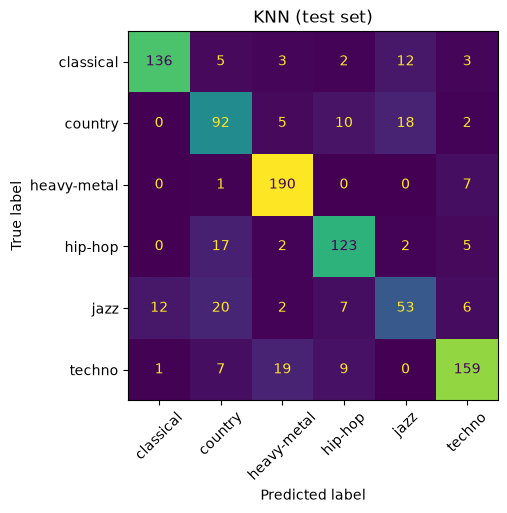

Correct: 753 of 930 songs (81.0%)
Correct per genre: classical 136/161, country 92/127, heavy-metal 190/198, hip-hop 123/149, jazz 53/100, techno 159/195
Biggest mistakes (true -> predicted): jazz -> country: 20, techno -> heavy-metal: 19, country -> jazz: 18, hip-hop -> country: 17, jazz -> classical: 12


In [143]:
show_confusion('KNN')

#### KNN confusion matrix:

The confusion matrix shows that the model correctly predicted 753 of the 930 songs (81.0%), a bit more than the Decision Tree. KNN gets more of the heavy-metal (190 of 198), techno (159 of 195) and country songs (92 of 127) right.

But KNN is even worse on jazz: only 53 of 100 jazz songs are correct. Jazz is the smallest genre, so when KNN looks at the 11 nearest songs, there are often more country or classical songs nearby than jazz songs, and the vote goes to the bigger genre. This shows up in the biggest mistakes: 20 jazz songs were predicted as country and 12 as classical. Techno is also mixed up with heavy-metal (19 songs), which are the two most energetic genres, and 17 hip-hop songs were predicted as country.

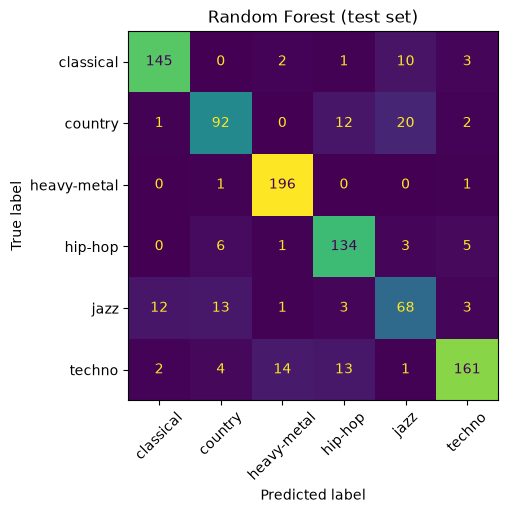

Correct: 796 of 930 songs (85.6%)
Correct per genre: classical 145/161, country 92/127, heavy-metal 196/198, hip-hop 134/149, jazz 68/100, techno 161/195
Biggest mistakes (true -> predicted): country -> jazz: 20, techno -> heavy-metal: 14, techno -> hip-hop: 13, jazz -> country: 13, jazz -> classical: 12


In [144]:
show_confusion('Random Forest')

#### Random Forest confusion matrix:

The confusion matrix shows that the model correctly predicted 796 of the 930 songs (85.6%), which is clearly better than the two baselines. Heavy-metal is almost perfect, with 196 of 198 songs correct. Jazz improves from 53 correct songs (KNN) to 68, which fits with class_weight='balanced' giving the smaller genres more weight.

The biggest mistake is now country predicted as jazz (20 songs), so the balanced weights also make the model guess jazz a bit more often. Techno is still mixed up with heavy-metal (14) and hip-hop (13), and 12 jazz songs were predicted as classical.

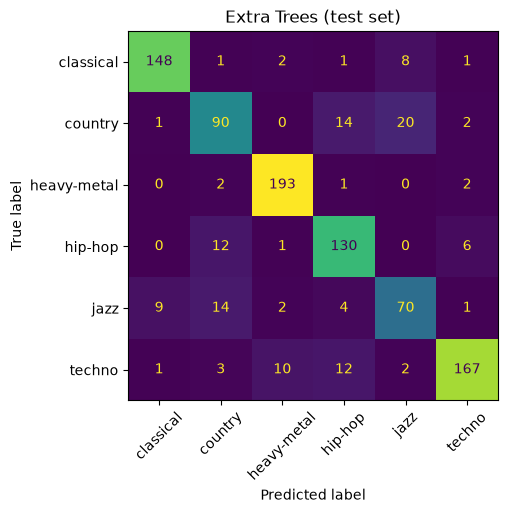

Correct: 798 of 930 songs (85.8%)
Correct per genre: classical 148/161, country 90/127, heavy-metal 193/198, hip-hop 130/149, jazz 70/100, techno 167/195
Biggest mistakes (true -> predicted): country -> jazz: 20, jazz -> country: 14, country -> hip-hop: 14, techno -> hip-hop: 12, hip-hop -> country: 12


In [145]:
show_confusion('Extra Trees')

#### Extra Trees confusion matrix:

The confusion matrix shows that the model correctly predicted 798 of the 930 songs (85.8%), almost exactly the same as the Random Forest (796). This matches their almost equal cross-validation scores. Extra Trees is a bit better on techno (167 vs 161) and classical (148 vs 145), and a bit worse on heavy-metal and hip-hop.

Country is the main problem here: it is mixed up with jazz (20) and hip-hop (14), and only 90 of 127 country songs are correct. In the EDA, country was in the middle on almost every feature, so it is close to many of the other genres.

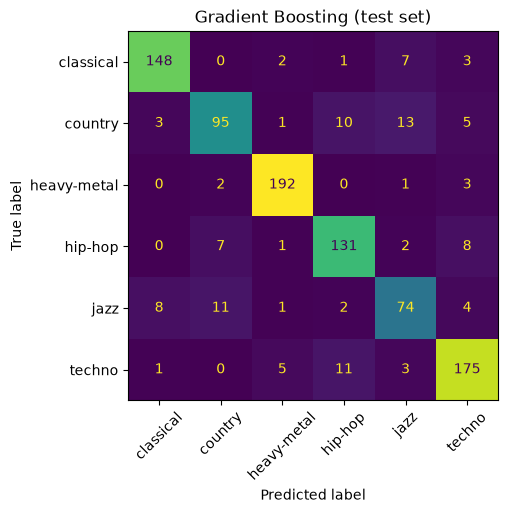

Correct: 815 of 930 songs (87.6%)
Correct per genre: classical 148/161, country 95/127, heavy-metal 192/198, hip-hop 131/149, jazz 74/100, techno 175/195
Biggest mistakes (true -> predicted): country -> jazz: 13, techno -> hip-hop: 11, jazz -> country: 11, country -> hip-hop: 10, jazz -> classical: 8


In [146]:
show_confusion('Gradient Boosting')

#### Gradient Boosting confusion matrix:

The confusion matrix shows that the model correctly predicted 815 of the 930 songs (87.6%), which is more than all the models before it in this list. It is very good on heavy-metal (192 of 198), techno (175 of 195) and classical (148 of 161), and it gets 74 of the 100 jazz songs right, which is the most of all the models, together with LightGBM.

It is also the model that mixes up country and jazz the least: only 13 country songs were predicted as jazz, compared to 17 to 21 for the other models. The biggest mistakes left are techno predicted as hip-hop (11), jazz predicted as country (11) and country predicted as hip-hop (10). These are the same genres that overlapped in the EDA: country is in the middle on most features, and jazz, classical and country are all quite calm and acoustic.

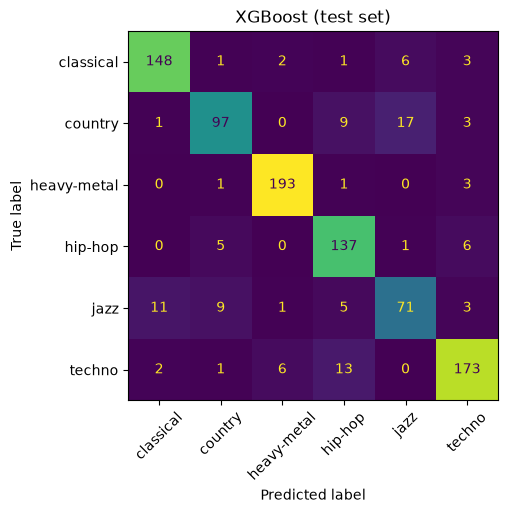

Correct: 819 of 930 songs (88.1%)
Correct per genre: classical 148/161, country 97/127, heavy-metal 193/198, hip-hop 137/149, jazz 71/100, techno 173/195
Biggest mistakes (true -> predicted): country -> jazz: 17, techno -> hip-hop: 13, jazz -> classical: 11, jazz -> country: 9, country -> hip-hop: 9


In [147]:
show_confusion('XGBoost')

#### XGBoost confusion matrix:

The confusion matrix shows that the model correctly predicted 819 of the 930 songs (88.1%), four songs more than Gradient Boosting. Classical (148 of 161), heavy-metal (193 of 198) and hip-hop (137 of 149) are very good, and XGBoost is the best of all the models on hip-hop and on country, where 97 of 127 songs are correct.

Jazz is still the hardest genre, with 71 of 100 correct: 11 jazz songs were predicted as classical and 9 as country. The biggest single mistake is country predicted as jazz (17 songs), and techno is also mixed up with hip-hop (13 songs). So the problems are the same as for the other models, there are just a few fewer of them.

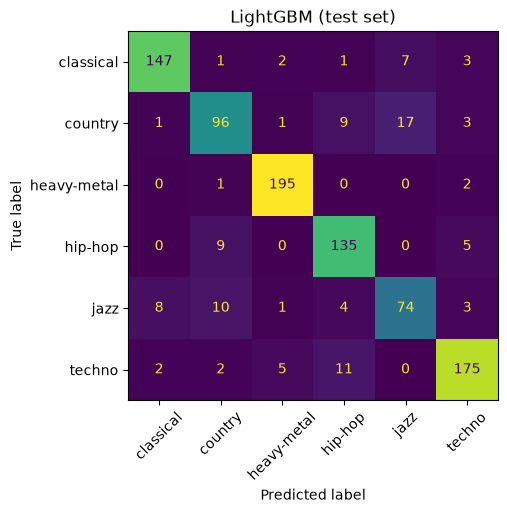

Correct: 822 of 930 songs (88.4%)
Correct per genre: classical 147/161, country 96/127, heavy-metal 195/198, hip-hop 135/149, jazz 74/100, techno 175/195
Biggest mistakes (true -> predicted): country -> jazz: 17, techno -> hip-hop: 11, jazz -> country: 10, hip-hop -> country: 9, country -> hip-hop: 9


In [148]:
show_confusion('LightGBM')

#### LightGBM confusion matrix:

The confusion matrix shows that the model correctly predicted 822 of the 930 songs (88.4%), which is the most of all the models. Together with Gradient Boosting, LightGBM gets the most jazz songs right of all the models (74 of 100), and it does very well on heavy-metal (195 of 198) and techno (175 of 195).

The biggest mistake is the same as for XGBoost: 17 country songs were predicted as jazz. Techno is mixed up with hip-hop (11 songs), and jazz with country (10 songs). LightGBM and XGBoost make almost the same mistakes, which makes sense, since they are both boosting models that build their trees in a similar way.

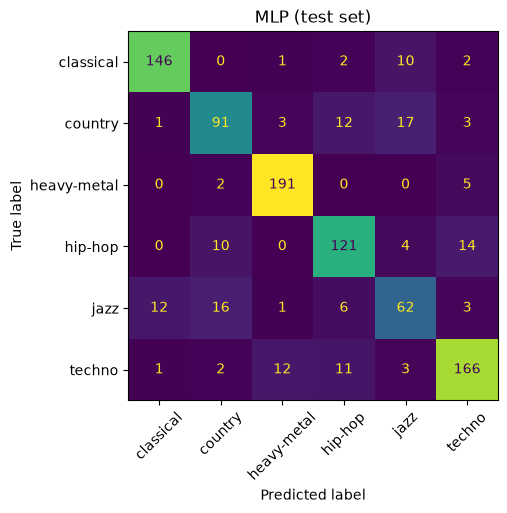

Correct: 777 of 930 songs (83.5%)
Correct per genre: classical 146/161, country 91/127, heavy-metal 191/198, hip-hop 121/149, jazz 62/100, techno 166/195
Biggest mistakes (true -> predicted): country -> jazz: 17, jazz -> country: 16, hip-hop -> techno: 14, techno -> heavy-metal: 12, jazz -> classical: 12


In [149]:
show_confusion('MLP')

#### MLP confusion matrix:

The confusion matrix shows that the model correctly predicted 777 of the 930 songs (83.5%), which is between the baselines and the ensembles. It does well on classical (146 of 161) and techno (166 of 195), but hip-hop is weaker than for the ensembles (121 of 149), and 14 hip-hop songs were predicted as techno.

Jazz and country are mixed up in both directions (17 country songs predicted as jazz, and 16 jazz songs as country), and only 62 of 100 jazz songs are correct.

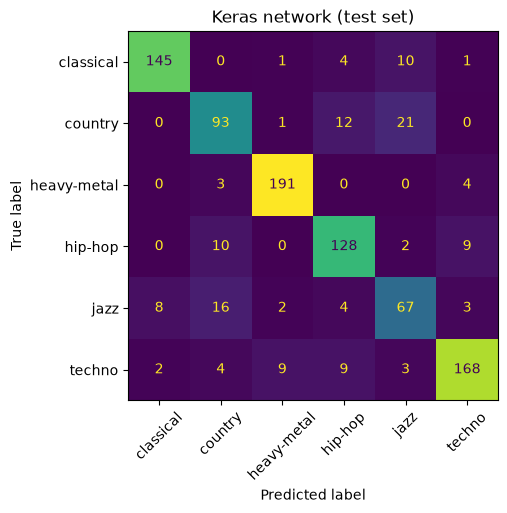

Correct: 792 of 930 songs (85.2%)
Correct per genre: classical 145/161, country 93/127, heavy-metal 191/198, hip-hop 128/149, jazz 67/100, techno 168/195
Biggest mistakes (true -> predicted): country -> jazz: 21, jazz -> country: 16, country -> hip-hop: 12, hip-hop -> country: 10, classical -> jazz: 10


In [150]:
show_confusion('Keras network')

#### Keras network confusion matrix:

The confusion matrix shows that the model correctly predicted 792 of the 930 songs (85.2%), which is better than the MLP and almost as good as the Random Forest. Heavy-metal (191 of 198) and techno (168 of 195) do well.

The biggest problem is country and jazz again: 21 country songs were predicted as jazz and 16 jazz songs as country, so only 67 of 100 jazz songs are correct. Country and hip-hop are also mixed up in both directions (12 and 10 songs), and 10 classical songs were predicted as jazz.

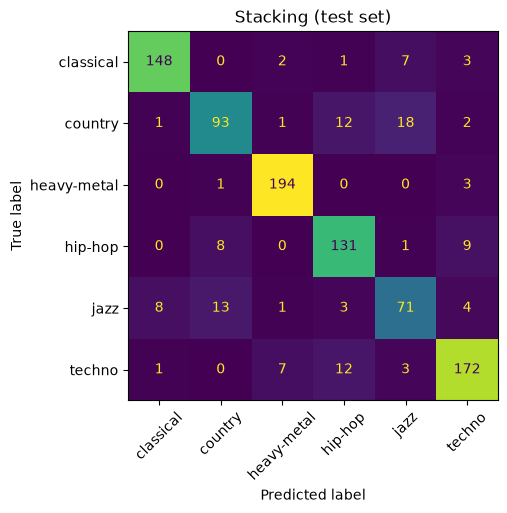

Correct: 809 of 930 songs (87.0%)
Correct per genre: classical 148/161, country 93/127, heavy-metal 194/198, hip-hop 131/149, jazz 71/100, techno 172/195
Biggest mistakes (true -> predicted): country -> jazz: 18, jazz -> country: 13, techno -> hip-hop: 12, country -> hip-hop: 12, hip-hop -> techno: 9


In [151]:
show_confusion('Stacking')

#### Stacking confusion matrix:

The confusion matrix shows that the model correctly predicted 809 of the 930 songs (87.0%), a bit less than Gradient Boosting (815), which is one of its base models. It is good on heavy-metal (194 of 198) and classical (148 of 161), but weaker on country (93 of 127) and jazz (71 of 100).

The biggest mistakes are the same as for the other models: 18 country songs predicted as jazz, 13 jazz songs predicted as country, and techno and country both mixed up with hip-hop (12 songs each). This supports what I saw in the cross-validation: combining the models doesn't fix the mistakes, because all the base models struggle with the same songs.

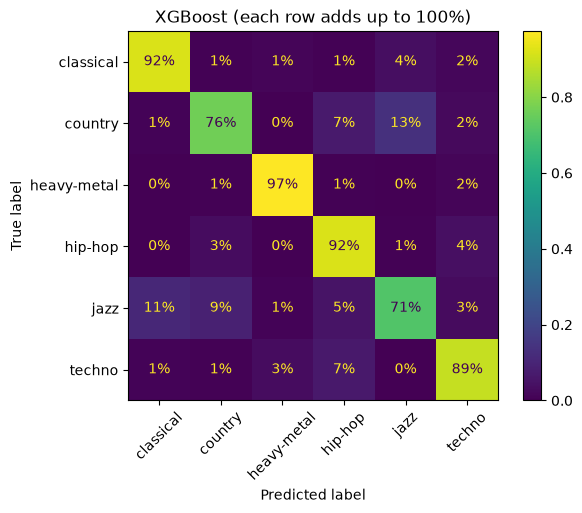

              precision    recall  f1-score   support

   classical       0.91      0.92      0.92       161
     country       0.85      0.76      0.80       127
 heavy-metal       0.96      0.97      0.96       198
     hip-hop       0.83      0.92      0.87       149
        jazz       0.75      0.71      0.73       100
      techno       0.91      0.89      0.90       195

    accuracy                           0.88       930
   macro avg       0.87      0.86      0.86       930
weighted avg       0.88      0.88      0.88       930



In [152]:
# The best model from cross-validation in more detail
best_pred = test_predictions[best_name]

ConfusionMatrixDisplay.from_predictions(test_targets, best_pred, display_labels=label_encoder.classes_,
                                        normalize='true', values_format='.0%', xticks_rotation=45)
plt.title(f'{best_name} (each row adds up to 100%)')
plt.show()

print(classification_report(test_targets, best_pred, target_names=label_encoder.classes_))

### Interpretation

I look at XGBoost in more detail, since it is my final model.

The normalized confusion matrix shows which share of each genre ends up in each predicted genre. Heavy-metal is almost perfect (97%), followed by classical and hip-hop (92%) and techno (89%). Country (76%) and especially jazz (71%) are clearly the hardest genres. 13% of the country songs are predicted as jazz and 7% as hip-hop, and the jazz mistakes are spread over classical (11%), country (9%) and hip-hop (5%).

The classification report shows the same thing. Heavy-metal has an F1 of 0.96, classical 0.92, techno 0.90 and hip-hop 0.87, while country (0.80) and jazz (0.73) are clearly lower.

Precision and recall are not always equal. Country has a precision of 0.85 but a recall of only 0.76: when the model says country it is usually right, but it misses about a quarter of the country songs, mostly to jazz. Hip-hop is the opposite, with a recall of 0.92 and a precision of 0.83: almost all hip-hop songs are found, but some country and techno songs are also called hip-hop. Jazz is low on both (precision 0.75 and recall 0.71).

The macro average F1 (0.86) is lower than the weighted average (0.88). This is because the two hardest genres, jazz and country, are also the two smallest genres after the cleaning. The weighted average gives them less weight, so it hides part of the problem. This is why I use the macro average to compare the models.

The mistakes fit with the EDA: jazz, country and classical are all calm and acoustic, so they are close to each other on the most important features.

## How confident is each model?

The scores and the confusion matrices only show if a prediction was right or wrong. But every model also gives a probability for each genre, and the genre it chooses is the one with the highest probability. That probability tells how sure the model was.

Here I compare how sure each model is when it is right and when it is wrong. A good model should be very sure when it is right, and less sure when it is wrong. A model that is very sure even when it is wrong is a bit dangerous, because you can't trust its confidence.

Sources:

- https://scikit-learn.org/stable/modules/calibration.html
- https://seaborn.pydata.org/generated/seaborn.boxplot.html
- https://pandas.pydata.org/docs/reference/api/pandas.concat.html
- https://numpy.org/doc/stable/reference/generated/numpy.where.html

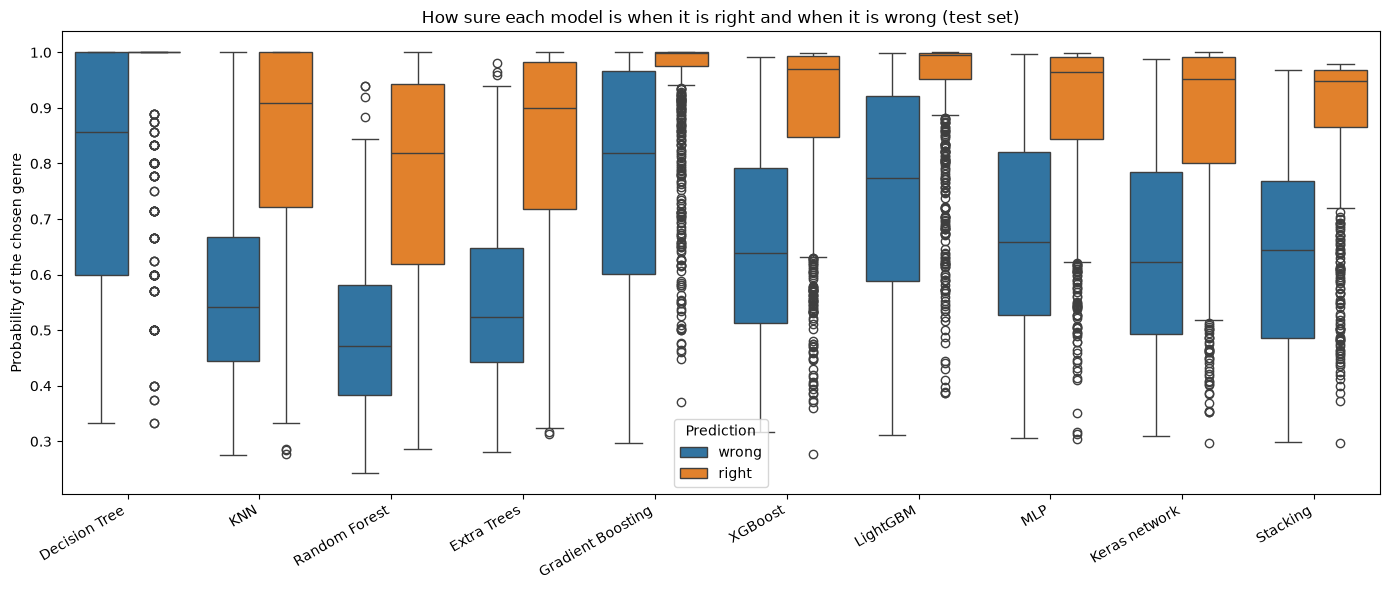

prediction,right,wrong,share of wrong predictions over 90% sure
model,,,
Decision Tree,0.948,0.802,0.456
KNN,0.829,0.563,0.040
Random Forest,0.773,0.500,0.022
Extra Trees,0.832,0.560,0.053
Gradient Boosting,0.952,0.780,0.400
XGBoost,0.894,0.653,0.108
LightGBM,0.938,0.747,0.287
MLP,0.894,0.663,0.098
Keras network,0.873,0.644,0.101


In [153]:
# For every model and every test song: how sure the model was (the probability of the genre it chose),
# and if the prediction was right or wrong
confidence_tables = []
for name in best_models:
    table = pd.DataFrame({
        'model': name,
        'confidence': test_probabilities[name].max(axis=1),
        'prediction': np.where(test_predictions[name] == test_targets.to_numpy(), 'right', 'wrong'),
    })
    confidence_tables.append(table)
confidence_df = pd.concat(confidence_tables)

plt.figure(figsize=(14, 6))
sns.boxplot(data=confidence_df, x='model', y='confidence', hue='prediction')
plt.xticks(rotation=30, ha='right')
plt.xlabel('')
plt.ylabel('Probability of the chosen genre')
plt.title('How sure each model is when it is right and when it is wrong (test set)')
plt.legend(title='Prediction')
plt.tight_layout()
plt.show()

# The average confidence when right and when wrong, and how often a wrong prediction was more than 90% sure
summary = confidence_df.groupby(['model', 'prediction'])['confidence'].mean().unstack()
wrong = confidence_df[confidence_df['prediction'] == 'wrong']
very_sure = wrong[wrong['confidence'] > 0.9]
summary['share of wrong predictions over 90% sure'] = very_sure.groupby('model').size() / wrong.groupby('model').size()
summary = summary.reindex(list(best_models)).fillna(0).round(3)
summary

### Interpretation

The plot shows that every model is more sure when it is right than when it is wrong. That is a good sign, because it means the confidence actually tells us something. But the models behave very differently.

The Decision Tree is the most often confidently wrong: 45.6% of its wrong predictions were made with more than 90% confidence. That makes sense for a single tree, since many of its leaves only contain songs from one genre, so the tree says it is completely sure even when it is wrong. Gradient Boosting is not much better. It is the most confident model when it is right (0.952 on average), but even when it is wrong it is on average 0.780 sure, and 40.0% of its wrong predictions were over 90% sure. So its probabilities can't be trusted very much.

The Random Forest is the most careful model. It is on average 0.773 sure when it is right and 0.500 when it is wrong, and only 2.2% of its wrong predictions were over 90% sure. This is because the forest takes the average vote of many trees, so the probabilities are more spread out. KNN (4.0%) and Extra Trees (5.3%) are also careful.

My final model, XGBoost, is in between. It is on average 0.894 sure when it is right and 0.653 when it is wrong, and only 10.8% of its wrong predictions were over 90% sure. LightGBM is more confident (0.938 when it is right), but it is also more often confidently wrong (28.7%). The neural networks and the stacking model are close to XGBoost (between 9.1% and 10.1%).

What I take from this is that a high score doesn't automatically mean that the probabilities can be trusted. Gradient Boosting and XGBoost have almost the same F1 (0.860 and 0.863), but when XGBoost is unsure, it actually says so much more often. That is one more reason why I am happy with XGBoost as my final model.

## ROC and precision-recall curves

The scores above only look at the final prediction. The curves use the predicted probabilities instead, and show how the model does for every possible threshold.

A ROC curve shows the true positive rate (the share of the songs in a genre that are found) against the false positive rate (the share of the other songs that are wrongly called that genre). A perfect model goes straight up to the top-left corner. The area under the curve (AUC) is 1.0 for a perfect model and 0.5 for random guessing.

A precision-recall curve shows precision against recall. A perfect model stays at a precision of 1.0 for every recall. AP (average precision) sums up the curve in one number.

With six genres, every genre is compared against all the other genres together, which is called "one vs rest".

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html
- https://www.geeksforgeeks.org/machine-learning/auc-roc-curve/
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.label_binarize.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.PrecisionRecallDisplay.html

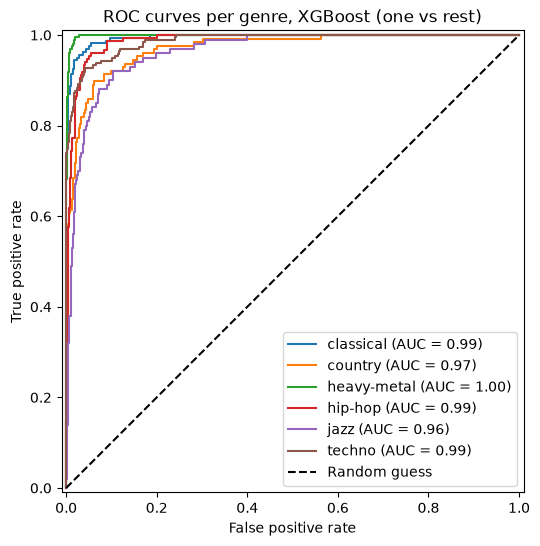

In [154]:
best_proba = test_probabilities[best_name]

fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    RocCurveDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title(f'ROC curves per genre, {best_name} (one vs rest)')
ax.legend(loc='lower right')
plt.show()

### Interpretation

Every genre has an AUC between 0.96 and 1.00, so the model ranks the songs of every genre well. Heavy-metal is almost perfect (1.00), and its curve goes straight up to the top-left corner. Classical, hip-hop and techno follow with 0.99. Jazz (0.96) and country (0.97) are the lowest, and their curves rise more slowly, which matches the confusion matrix, where these two genres had the most mistakes.

The ROC curve looks very good even for jazz. The reason is that there are many more "not jazz" songs (830) than jazz songs (100) in the test set, so even quite a few wrong jazz predictions only give a small false positive rate. The precision-recall curves below show the problem more clearly.

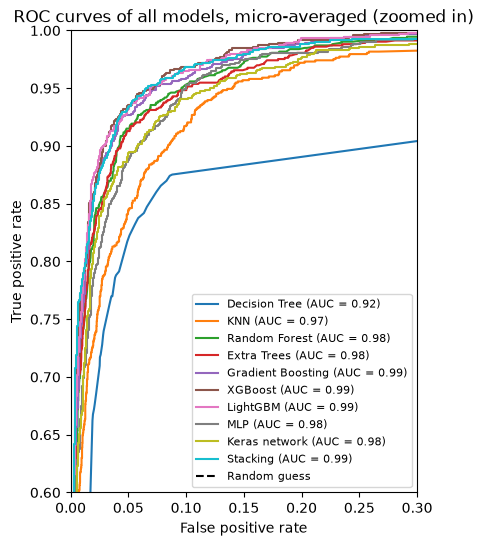

In [155]:
# Micro average: all six one-vs-rest problems are put together into one big yes/no problem,
# so every model gets one curve
test_binary = label_binarize(test_targets, classes=range(6))      # one yes/no column per genre

fig, ax = plt.subplots(figsize=(7, 6))
for name in best_models:
    RocCurveDisplay.from_predictions(test_binary.ravel(), test_probabilities[name].ravel(), name=name, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_xlim(0, 0.3)       # zoomed in on the top-left corner, otherwise the curves overlap
ax.set_ylim(0.6, 1.0)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves of all models, micro-averaged (zoomed in)')
ax.legend(loc='lower right', fontsize=8)     # small text, since there are 10 models
plt.show()

### Interpretation

This plot shows one micro-averaged ROC curve per model, zoomed in on the top-left corner. Gradient Boosting, XGBoost, LightGBM and Stacking have the best curves (AUC 0.99): they reach a true positive rate of about 0.9 at a false positive rate of only about 0.05. The Random Forest, Extra Trees and the neural networks are close behind (0.98), and KNN is a bit lower (0.97).

The Decision Tree stands out with an AUC of 0.92 and a curve with a sharp corner. A single tree gives the same probability to all the songs in the same leaf, so it only has a few different probability values, and the curve jumps instead of being smooth. The other models give more fine-grained probabilities, so they can rank the songs better.

The AUC values in the plot are a bit higher than in the test table, because the table uses the macro average (one AUC per genre, then the average), while this plot uses the micro average. The order of the models is the same as in the test table, so the probabilities tell the same story as the predictions.

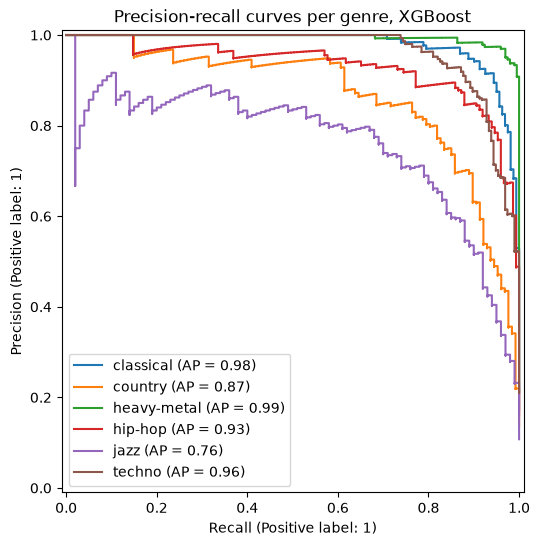

In [156]:
fig, ax = plt.subplots(figsize=(7, 6))
for i, genre in enumerate(label_encoder.classes_):
    PrecisionRecallDisplay.from_predictions(test_targets == i, best_proba[:, i], name=genre, ax=ax)

ax.set_title(f'Precision-recall curves per genre, {best_name}')
ax.legend(loc='lower left')
plt.show()

### Interpretation

The precision-recall curves show a much bigger difference between the genres than the ROC curves. Heavy-metal (AP 0.99), classical (0.98) and techno (0.96) keep a precision close to 1.0 until a recall of about 0.7 to 0.8, so the model can find most of these songs without many wrong ones. Hip-hop is a bit lower (0.93).

Country (0.87) and especially jazz (0.76) are clearly worse. For jazz, the precision stays below 0.9 for almost the whole curve, and after a recall of about 0.5 it falls steadily: to find more of the jazz songs, the model has to accept more and more songs from other genres. This is because jazz is the smallest genre, and it overlaps with both classical and country.

This is a good example of why ROC alone can look too positive when the classes are imbalanced: jazz has a ROC-AUC of 0.96, but an average precision of only 0.76.

# FURTHER ANALYSIS

## Audio only: how much does popularity add?

In the EDA I argued that popularity says something about listeners, not about how a song sounds, and every tuning chose to keep it. Here I measure how much of each model's score comes from popularity: I take every tuned model, keep all its settings but drop popularity, and calculate the cross-validation and test scores again.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.barh.html

In [157]:
def without_popularity(model):
    """A fresh, unfitted copy of a tuned model with the same settings, but with popularity dropped."""
    model = clone(model)
    if isinstance(model, StackingClassifier):
        # In the stacking model, popularity is inside the preprocessing of every base model
        model.set_params(**{f'{name}__preprocess__popularity': 'drop' for name, _ in model.estimators})
    else:
        model.set_params(preprocess__popularity='drop')
    return model


audio_rows = {}
for name, model in best_models.items():
    audio_model = without_popularity(model)
    n_jobs = 1 if name == 'Keras network' else -1      # Keras is trained one fold at a time, like in its search
    scores = cross_val_score(audio_model, train_features, train_targets, cv=cv, scoring='f1_macro', n_jobs=n_jobs)
    audio_model.fit(train_features, train_targets)
    audio_rows[name] = {
        'CV F1 with popularity': cv_table.loc[name, 'CV F1'],
        'CV F1 audio only': scores.mean(),
        'Test F1 with popularity': test_results_df.loc[name, 'F1'],
        'Test F1 audio only': f1_score(test_targets, audio_model.predict(test_features), average='macro'),
    }

audio_table = pd.DataFrame(audio_rows).T
audio_table['Test F1 lost'] = audio_table['Test F1 with popularity'] - audio_table['Test F1 audio only']
audio_table = audio_table.sort_values('Test F1 audio only', ascending=False).round(3)
audio_table

,CV F1 with popularity,CV F1 audio only,Test F1 with popularity,Test F1 audio only,Test F1 lost
Stacking,0.862,0.788,0.851,0.802,0.049
LightGBM,0.872,0.789,0.867,0.799,0.068
XGBoost,0.869,0.793,0.863,0.797,0.066
Random Forest,0.850,0.793,0.836,0.790,0.046
Gradient Boosting,0.865,0.778,0.860,0.786,0.074
Keras network,0.800,0.758,0.831,0.769,0.062
Extra Trees,0.851,0.778,0.838,0.769,0.069
MLP,0.814,0.754,0.813,0.752,0.061
KNN,0.793,0.745,0.784,0.747,0.037
Decision Tree,0.779,0.690,0.773,0.676,0.097


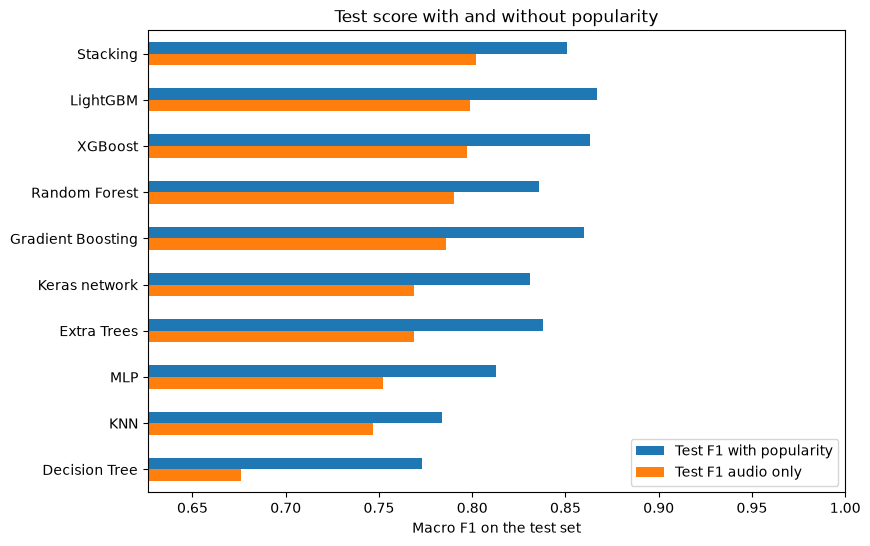

In [158]:
audio_table[['Test F1 with popularity', 'Test F1 audio only']].plot(kind='barh', figsize=(9, 6))
plt.gca().invert_yaxis()
plt.xlim(audio_table['Test F1 audio only'].min() - 0.05, 1.0)
plt.xlabel('Macro F1 on the test set')
plt.title('Test score with and without popularity')
plt.legend(loc='lower right')
plt.show()

### Interpretation

Every model gets worse without popularity. On the test set, the macro F1 drops by between 0.037 (KNN) and 0.097 (Decision Tree). For my final model, XGBoost, it drops from 0.863 to 0.797.

The order of the models changes. With only the audio features, the stacking model is the best (0.802), followed by LightGBM (0.799), XGBoost (0.797) and the Random Forest (0.790). Of these four, stacking and the Random Forest lose the least (0.049 and 0.046). Maybe this is because they both combine many different models or trees, so they depend less on one single feature. Gradient Boosting drops more (from 0.860 to 0.786), so it seems to rely more on popularity than the other boosting models. All the settings were tuned with popularity, so a model tuned without popularity from the start might do a bit better.

This confirms what I suspected in the EDA. Popularity helps mostly because jazz, country and classical have many songs with popularity 0, which is a pattern in how people listen, not in how the music sounds.

What I take from this: if the goal is just the highest score on this dataset, popularity should be kept. But if the goal is to recognise a genre from the sound, which was the goal I set at the start, the honest answer is the audio-only score: about 0.80 for the best models. That is still far above random guessing (0.16).

## Which features matter? Permutation importance

Permutation importance measures how much the score drops when the values of one feature are shuffled randomly, so the feature becomes useless while everything else stays the same. A big drop means the model depends a lot on that feature. It works for any model, and it measures the original columns, so key counts as one feature even when it is one-hot encoded. I calculate it on the test set for the best model, and repeat the shuffling 10 times per feature.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html
- https://scikit-learn.org/stable/modules/permutation_importance.html
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.barh.html

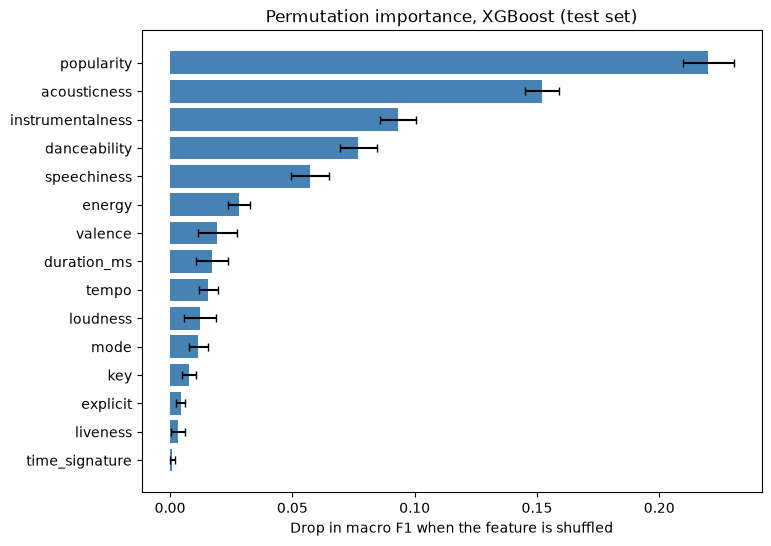

,importance,std
popularity,0.220,0.010
acousticness,0.152,0.007
instrumentalness,0.093,0.007
danceability,0.077,0.008
speechiness,0.057,0.008
energy,0.028,0.004
valence,0.019,0.008
duration_ms,0.017,0.007
tempo,0.016,0.004
loudness,0.012,0.007


In [159]:
best_model = best_models[best_name]
importance = permutation_importance(best_model, test_features, test_targets, scoring='f1_macro',
                                    n_repeats=10, random_state=random_state, n_jobs=-1)

importance_df = pd.DataFrame({'importance': importance.importances_mean, 'std': importance.importances_std},
                             index=test_features.columns).sort_values('importance')

plt.figure(figsize=(8, 6))
plt.barh(importance_df.index, importance_df['importance'], xerr=importance_df['std'], color='steelblue', capsize=3)
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.title(f'Permutation importance, {best_name} (test set)')
plt.show()

importance_df.sort_values('importance', ascending=False).round(3)

### Interpretation

Popularity is the most important feature for XGBoost: shuffling it lowers the macro F1 by 0.220. That fits with the audio-only comparison above, where the test F1 dropped from 0.863 to 0.797 without it. The two numbers are not the same: when the model is trained without popularity, it can learn to use the other features instead, but when popularity is only shuffled, the trained model still relies on it and gets confused.

Right behind it is acousticness (0.152). Then come instrumentalness (0.093) and danceability (0.077), followed by speechiness (0.057) and energy (0.028). This matches my EDA very well. In the box plots, acousticness and instrumentalness separated the calm genres (classical and jazz) from the rest, danceability separated hip-hop and techno from the others, and speechiness mostly helped to recognise hip-hop.

Some features that looked useful in the EDA are less important here. Loudness (0.012) separated the genres well in the box plots, but it is strongly correlated with energy (0.82) and acousticness (-0.71). When it is shuffled, the model can still get almost the same information from the other features, so it looks less important on its own. Energy (0.028) is quite low for the same reason.

Key, explicit, liveness and time_signature are almost useless (0.008 or less). This also fits with the EDA, where key and time signature only showed small differences between the genres, and liveness looked the same for every genre.

## Error analysis: which songs does the model get wrong?

The confusion matrix shows how many songs are mixed up. Here I look at the actual songs behind the most common mistakes, using the song names I saved before dropping them.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html
- https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html

In [160]:
genre_names = label_encoder.classes_
mistakes = pd.DataFrame({'true genre': genre_names[test_targets.to_numpy()],
                         'predicted genre': genre_names[best_pred]}, index=test_targets.index)
mistakes = mistakes[mistakes['true genre'] != mistakes['predicted genre']]

print(f"{best_name} got {len(mistakes)} of {len(test_targets)} test songs wrong.\n")
print("Most common mistakes:")
print(mistakes.value_counts().head(8).to_string())

XGBoost got 111 of 930 test songs wrong.

Most common mistakes:
true genre  predicted genre
country     jazz               17
techno      hip-hop            13
jazz        classical          11
country     hip-hop             9
jazz        country             9
classical   jazz                6
hip-hop     techno              6
techno      heavy-metal         6


In [161]:
# Some of the songs behind the three most common mistakes, with a few of their features
examples = mistakes.join(song_info).join(
    test_features[['acousticness', 'energy', 'instrumentalness', 'speechiness', 'popularity']])

for true_genre, predicted_genre in mistakes.value_counts().head(3).index:
    print(f"\n{true_genre} predicted as {predicted_genre}:")
    rows = examples[(examples['true genre'] == true_genre) & (examples['predicted genre'] == predicted_genre)]
    display(rows.drop(columns=['true genre', 'predicted genre']).head(5))


country predicted as jazz:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
19003,Something in the Orange,Zach Bryan,New Country,0.555,0.192,0.000008,0.0400,3
19032,"Burn, Burn, Burn",Zach Bryan,Burn Burn Burn - Hot Country Hits,0.897,0.296,0.000050,0.0755,0
19093,Silent Night,Cody Johnson;Clara Johnson;Brandi Johnson;Cori...,Happy Country Christmas,0.687,0.131,0.000000,0.0280,0
19145,O Christmas Tree,George Strait,Weihnachten Playlist,0.794,0.295,0.000000,0.0287,0
19188,Better Boat,Kenny Chesney;Mindy Smith,Finest Country,0.827,0.265,0.000023,0.0302,0



techno predicted as hip-hop:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
109004,Good Thing (with Kehlani),Zedd;Kehlani,Good Thing (with Kehlani),0.3990,0.564,0.000000,0.0378,68
109011,Your Love (9PM),ATB;Topic;A7S,Your Love (9PM),0.1940,0.784,0.000006,0.1120,78
109012,Clarity,Zedd;Foxes,Clarity,0.0398,0.781,0.000000,0.0720,75
109033,Stay,Zedd;Alessia Cara,Beginner Ride (Mixtape Vol. 1),0.2540,0.623,0.000000,0.0621,1
109060,Wonders,Neelix;Ghost Rider;The Gardener & The Tree,Wonders,0.1670,0.616,0.016500,0.0488,62



jazz predicted as classical:


,track_name,artists,album_name,acousticness,energy,instrumentalness,speechiness,popularity
64556,Love Letter - Original Mix,Living Room,"Lounge La Nuit, Vol. 1",0.914,0.3000,0.86200,0.0357,0
64564,Love Will Follow,George Howard,Cool Covers - Smooth Jazz Plays The Hits!,0.580,0.6000,0.45200,0.0324,45
64654,Day Dream,Bill Charlap Trio,Street Of Dreams,0.909,0.0951,0.89000,0.0388,65
64707,"Goodbye, Old Girl",Art Farmer,Art,0.994,0.0288,0.89500,0.0467,51
64731,Zerdaliler,Ezginin Günlügü,İlk Aşk,0.940,0.2920,0.00121,0.0497,45


### Interpretation

XGBoost got 111 of the 930 test songs wrong. The most common mistakes are country predicted as jazz (17), techno predicted as hip-hop (13) and jazz predicted as classical (11).

Looking at the actual songs makes the mistakes easier to understand.

The country songs that were predicted as jazz are calm, acoustic country songs, like "Something in the Orange" and "Burn, Burn, Burn" by Zach Bryan, and Christmas songs like "Silent Night" and "O Christmas Tree". They have a high acousticness (0.56 to 0.90), a low energy (0.13 to 0.30) and a popularity of 0 or close to it, which is exactly what a typical jazz song looks like in this dataset.

The techno songs that were predicted as hip-hop are electronic songs with a singer, like "Good Thing" by Zedd and Kehlani, "Clarity" by Zedd and Foxes, "Stay" by Zedd and Alessia Cara, and "Your Love (9PM)" by ATB. They have vocals (instrumentalness close to 0), and most of them are quite popular. That looks more like a typical hip-hop song than a typical techno track, which is usually instrumental.

The jazz songs that were predicted as classical are calm and acoustic, like "Day Dream" by Bill Charlap Trio and "Goodbye, Old Girl" by Art Farmer. Most of them have a very high acousticness (up to 0.99), and three of the five songs shown have almost no vocals (instrumentalness between 0.86 and 0.90). Without vocals and with acoustic instruments, they look like classical music to the model.

So many of the mistakes are understandable. Christmas songs especially seem to be hard, since they show up in several genres and are often recorded in a calm, acoustic style no matter what the genre is. Some of these songs could also be argued to belong to another genre. Zedd, for example, is usually described as an EDM or pop producer rather than a techno artist. The genre label comes from the playlist the song was found in, and not from the song itself.

## Learning curve: would more data help?

A learning curve trains the best model on bigger and bigger parts of the training data and shows the training score and the cross-validation score. If the cross-validation score is still rising at the end, more data would probably help. If it has flattened out, more data of the same kind would not help much.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html
- https://scikit-learn.org/stable/modules/learning_curve.html
- https://www.geeksforgeeks.org/machine-learning/learning-curve-to-identify-overfit-underfit/

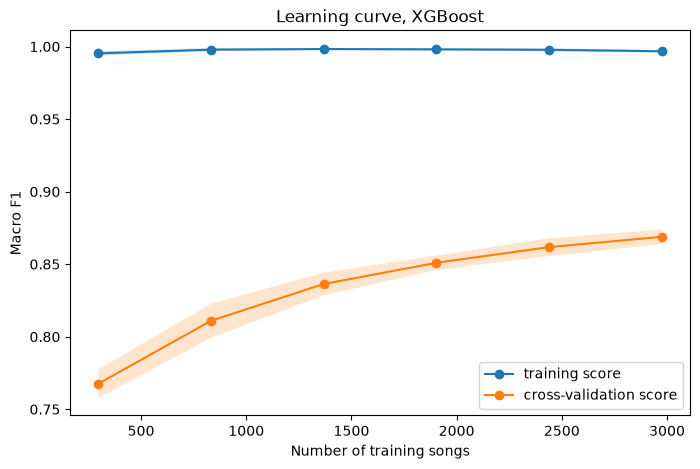

 songs  train F1  CV F1
   297     0.995  0.768
   833     0.998  0.811
  1368     0.998  0.836
  1904     0.998  0.851
  2440     0.998  0.862
  2976     0.997  0.869


In [162]:
sizes, train_scores, val_scores = learning_curve(clone(best_model), train_features, train_targets, cv=cv, scoring='f1_macro', train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)

plt.figure(figsize=(8, 5))

for scores, label in [(train_scores, 'training score'), (val_scores, 'cross-validation score')]:
    plt.plot(sizes, scores.mean(axis=1), 'o-', label=label)
    plt.fill_between(sizes, scores.mean(axis=1) - scores.std(axis=1),
                     scores.mean(axis=1) + scores.std(axis=1), alpha=0.2)
plt.xlabel('Number of training songs')
plt.ylabel('Macro F1')
plt.title(f'Learning curve, {best_name}')
plt.legend()
plt.show()

print(pd.DataFrame({'songs': sizes, 'train F1': train_scores.mean(axis=1),
                    'CV F1': val_scores.mean(axis=1)}).round(3).to_string(index=False))

### Interpretation

The training score is almost perfect for every size (0.995 to 0.998), so XGBoost fits its training data very well. It is not exactly 1.0, probably because settings like subsample and min_child_weight stop the trees from learning every single song. The cross-validation score rises the whole time: from 0.768 with about 300 songs to 0.869 with about 3,000 songs. It rises fastest in the beginning, but it is still rising at the end (from 0.862 to 0.869 in the last step).

This means that more data would probably help. The big gap between the training score and the cross-validation score (about 0.13) points in the same direction: the model could learn more if it had more examples. This is a cost of removing the re-released copies, which made the dataset smaller, especially for jazz and country. A natural next step would be to collect more songs for these genres.

# CONCLUSION

### What I did

In this project I used the Spotify Tracks dataset from Kaggle to try to predict the genre of a song, only by looking at numbers that describe how the song sounds, like how energetic, danceable or acoustic it is.

The full dataset has 114 genres, but when I looked closer I saw that many of them share the same songs. For example, singer-songwriter and songwriter have exactly the same 1,000 songs. A model can't learn the difference between two genres that contain the same songs, so I chose six genres that are very different from each other and share almost no songs: classical, country, heavy-metal, hip-hop, jazz and techno.

### What I learned from the data

The features that helped the most to tell the genres apart were acousticness, instrumentalness, danceability, energy and loudness. But no single feature could separate all six genres on its own. For example, classical and jazz are both calm and acoustic, and the main difference is that classical usually has no vocals. So the models had to combine several features to get it right.

I also found that popularity is very different between the genres. Jazz, country and classical have a lot of songs with a popularity of 0, while heavy-metal has almost none. But popularity says something about how many people listen to a song, not about how it sounds, so I kept an eye on it the whole way.

The biggest surprise was a problem I didn't see at first. The same song is often released on many different albums, for example on compilation albums like "Mozart: A Night of Classics", and every release gets its own track_id. That is why my first duplicate check didn't find them. There were 1,248 of these copies. I tested what would happen if I kept them: about one in four test songs would also be in the training data, and the model got a perfect score (1.000) on those songs, but only 0.884 on the new songs. In other words, the model was partly remembering songs instead of learning the genres. After removing the copies I had 4,650 songs left, but the genres were not balanced anymore: there were 500 jazz songs and 991 heavy-metal songs.

### How I prepared the data and tuned the models

I put all the preparation steps, like scaling and encoding, inside a pipeline together with the model. This way the preparation is only learned from the training data, and the test data stays completely unseen. Instead of choosing one way to prepare the data myself, I let the automatic tuning try different options together with the model settings.

All the models were tuned with cross-validation, where the training data is split into 5 parts and every part takes a turn as the validation data. I used the same 5 parts for every model, so the comparison between them is fair.

The tuning showed me a few things. Keeping popularity always gave a better score. Scaling was very important for KNN: without scaling its average score was about 0.54, and with scaling it was about 0.74. This makes sense, because KNN measures the distance between songs, and without scaling, a feature with big numbers like the song length decides almost everything. For the tree models, scaling didn't matter at all. It made almost no difference if key and time signature were one-hot encoded (turned into yes/no columns) or kept as numbers. And giving the smaller genres more weight (class_weight='balanced') helped the Random Forest a little, but not the other models.

### Results

I compared the models with the macro F1 score, which gives every genre the same weight, also the small ones like jazz. On the test set, random guessing got 0.158. The two baselines got 0.773 (Decision Tree) and 0.784 (KNN), and the two neural networks got 0.813 (MLP) and 0.831 (Keras). The Random Forest got 0.836 and Extra Trees 0.838. My extra stacking model, which combines four of the other models, got 0.851. At the top were the three boosting models: Gradient Boosting got 0.860, XGBoost 0.863 and LightGBM 0.867.

From the results, I can see that the tree ensembles were the best, the neural networks came in the middle, and the baselines were the weakest. But all of them are far better than random guessing.

The three boosting models were at the top, and they were so close that I can't really say that one of them is better than the others. The difference between them was smaller than how much the score changed from one part of the data to another in the cross-validation. Because of this, I chose my final model with a simple rule before I looked at the test set: if several models are about equally good, I take the most stable one, which is the one whose score changed the least between the 5 parts of the cross-validation. That was XGBoost. On the test set it got an accuracy of 0.881 and a macro F1 of 0.863, only a little below LightGBM (0.867).

What I find interesting is that combining the best models in a stacking ensemble didn't help. My thinking is that all the models struggle with the same songs, so putting them together doesn't fix the mistakes.

The hardest genres were jazz (F1 0.73) and country (0.80). They were mostly mixed up with each other and with classical. This makes sense when I think back to the EDA, because these three genres are all calm and acoustic. When I looked at the actual songs the model got wrong, many of the mistakes were understandable: calm acoustic country songs, jazz pieces without vocals, Christmas songs, and electronic songs with a singer that the model thought were hip-hop instead of techno.

### How much of this is really about the sound?

When I removed popularity, the score of the best models dropped to about 0.80, and to 0.797 for XGBoost. This tells me that a part of the score, around 0.05 to 0.07, comes from how many people listen to the songs and not from how they sound. Since my goal was to recognise the genre from the sound, I think the honest answer is the score without popularity: about 0.80. That is still much better than random guessing (0.16), so the audio features really do say a lot about the genre of a song.

### Limitations

There are some limitations I want to mention. The genre of a song comes from the playlist it was found in, not from the song itself. Some songs, like Christmas songs, could fit in more than one genre, so some of the "mistakes" might not be real mistakes. I also only used six genres that are quite different from each other. With genres that sound more alike, or with all 114, it would be much harder.

After removing the copies I had less data, and the genres were not balanced. The learning curve showed that the models would probably get better with more songs. I also tuned all the models with popularity included, so if I had tuned them without it from the start, the scores without popularity might be a bit higher. Finally, I found the copies by looking for songs with exactly the same audio values. Different versions of the same song, like a remastered version, have slightly different values, so some of them might still be in the data.